In [1]:
import simexpal

import pandas as pd
from io import StringIO
from tabulate import tabulate

pd.set_option('display.width', 120)

def parse(run, f):

  csv_data = f.read()
  try:
    df = pd.read_csv(StringIO(csv_data))
  except Exception as e:
    print(f"Error parsing CSV for run {run}: {e}")
    return None
  
  instance_name = run.instance.shortname
  df['experiment'] = run.experiment.name
  df['instance'] = instance_name

  return df

cfg = simexpal.config_for_dir("./../simex")

results_HEFT = []
for successful_run in cfg.collect_successful_results():
  with successful_run.open_output_file() as f:
    result = parse(successful_run, f)
    if result is not None:
      if "Algorithm" in result.columns:
        heft_rows = result[result["Algorithm"] == "HEFT-SL"]
        if not heft_rows.empty:
          results_HEFT.append(heft_rows)

if results_HEFT:
  df_HEFT = pd.concat(results_HEFT, ignore_index=True)
else:
  print("No results found.")


# add one to avoid zero division
df_HEFT["carbon cost"] = df_HEFT["carbon cost"] + 1
df_HEFT["experiment_norm"] = df_HEFT["experiment"].str.replace("CaWoMap_", "", regex=False)
df_HEFT["time[ms]"] = df_HEFT["time[ms]"].astype(float)
print(tabulate(df_HEFT, headers='keys', tablefmt='psql'))


+----+-------------+------------+------------+------------+---------------+------------+----------+----------------------+-------------+-------------------+
|    | Algorithm   |   time[ms] |   makespan |   deadline |   carbon cost |   validity |   factor | experiment           | instance    | experiment_norm   |
|----+-------------+------------+------------+------------+---------------+------------+----------+----------------------+-------------+-------------------|
|  0 | HEFT-SL     |        219 |        140 |        140 |             1 |          1 |        1 | CaWoMap_DE2024_large | atacseq     | DE2024_large      |
|  1 | HEFT-SL     |       5019 |        199 |        199 |             1 |          1 |        1 | CaWoMap_DE2024_large | atacseq1000 | DE2024_large      |
|  2 | HEFT-SL     |        991 |        168 |        168 |             1 |          1 |        1 | CaWoMap_DE2024_large | atacseq200  | DE2024_large      |
|  3 | HEFT-SL     |         60 |         66 |         66 

In [2]:
results_CWM_12 = []
for successful_run in cfg.collect_successful_results():
  with successful_run.open_output_file() as f:
    result = parse(successful_run, f)
    if result is not None:
      if "Algorithm" in result.columns: 
        cwm_rows = result[(result["Algorithm"] == "CWM") & (result["factor"] == 1.2)]
        if not cwm_rows.empty:
          results_CWM_12.append(cwm_rows)

if results_CWM_12:
  df_CWM_12 = pd.concat(results_CWM_12, ignore_index=True)
  print(tabulate(df_CWM_12, headers='keys', tablefmt='psql'))
else:
  print("No results found.")

# add one to avoid zero division
df_CWM_12["carbon cost"] = df_CWM_12["carbon cost"] + 1
df_CWM_12["experiment_norm"] = df_CWM_12["experiment"].str.replace("CaWoMap_", "", regex=False)

results_CWM_15 = []
for successful_run in cfg.collect_successful_results():
  with successful_run.open_output_file() as f:
    result = parse(successful_run, f)
    if result is not None:
      if "Algorithm" in result.columns: 
        cwm_rows = result[(result["Algorithm"] == "CWM") & (result["factor"] == 1.5)]
        if not cwm_rows.empty:
          results_CWM_15.append(cwm_rows)

if results_CWM_15:
  df_CWM_15 = pd.concat(results_CWM_15, ignore_index=True)
  #print(tabulate(df_CWM_15, headers='keys', tablefmt='psql'))
else:
  print("No results found.")

# add one to avoid zero division
df_CWM_15["carbon cost"] = df_CWM_15["carbon cost"] + 1
df_CWM_15["experiment_norm"] = df_CWM_15["experiment"].str.replace("CaWoMap_", "", regex=False)

results_CWM_20 = []
for successful_run in cfg.collect_successful_results():
  with successful_run.open_output_file() as f:
    result = parse(successful_run, f)
    if result is not None:
      if "Algorithm" in result.columns: 
        cwm_rows = result[(result["Algorithm"] == "CWM") & (result["factor"] == 2.0)]
        if not cwm_rows.empty:
          results_CWM_20.append(cwm_rows)

if results_CWM_20:
  df_CWM_20 = pd.concat(results_CWM_20, ignore_index=True)
  #print(tabulate(df_CWM_20, headers='keys', tablefmt='psql'))
else:
  print("No results found.")

# add one to avoid zero division
df_CWM_20["carbon cost"] = df_CWM_20["carbon cost"] + 1
df_CWM_20["experiment_norm"] = df_CWM_20["experiment"].str.replace("CaWoMap_", "", regex=False)
df_CWM_20["time[ms]"] = df_CWM_20["time[ms]"].astype(float)


+----+-------------+------------+------------+------------+---------------+------------+----------+----------------------+-------------+
|    | Algorithm   |   time[ms] |   makespan |   deadline |   carbon cost |   validity |   factor | experiment           | instance    |
|----+-------------+------------+------------+------------+---------------+------------+----------+----------------------+-------------|
|  0 | CWM         |       9111 |        140 |        168 |             0 |          1 |      1.2 | CaWoMap_DE2024_large | atacseq     |
|  1 | CWM         |      14125 |        216 |        239 |             0 |          1 |      1.2 | CaWoMap_DE2024_large | atacseq1000 |
|  2 | CWM         |       9732 |        168 |        202 |             0 |          1 |      1.2 | CaWoMap_DE2024_large | atacseq200  |
|  3 | CWM         |       8901 |         66 |         80 |             0 |          1 |      1.2 | CaWoMap_DE2024_large | bacass      |
|  4 | CWM         |       8977 |        

In [3]:
violations_12 = df_CWM_12[df_CWM_12["makespan"] > df_CWM_12["deadline"]].copy()
print(len(violations_12))
#print(tabulate(violations_12, headers='keys', tablefmt='psql'))
violations_15 = df_CWM_15[df_CWM_15["makespan"] > df_CWM_15["deadline"]].copy()
print(len(violations_15))
#print(tabulate(violations_15, headers='keys', tablefmt='psql'))
violations_20 = df_CWM_20[df_CWM_20["makespan"] > df_CWM_20["deadline"]].copy()
print(len(violations_20))
#print(tabulate(violations_20, headers='keys', tablefmt='psql'))

violations_12_val = df_CWM_12[df_CWM_12["validity"] == 0].copy()
print(len(violations_12_val))
violations_15_val = df_CWM_15[df_CWM_15["validity"] == 0].copy()
print(len(violations_15_val))
violations_20_val = df_CWM_20[df_CWM_20["validity"] == 0].copy()
print(len(violations_20_val))

0
0
0
0
0
0


In [4]:
results_cawosched_pressure = []
for successful_run in cfg.collect_successful_results():
  with successful_run.open_output_file() as f:
    result = parse(successful_run, f)
    if result is not None:
      if "Variant" in result.columns:
        cawomap_rows = result[result["Variant"] == "pressWR-LS"]
        if not cawomap_rows.empty:
          results_cawosched_pressure.append(cawomap_rows)

if results_cawosched_pressure:
  df_cawosched_pressure = pd.concat(results_cawosched_pressure, ignore_index=True)
  #print(tabulate(df_cawosched_pressure, headers='keys', tablefmt='psql'))
else:
  print("No results found.")

# Currently df_cawosched_pressure["Cost"] is string but we want int
df_cawosched_pressure["Cost"] = df_cawosched_pressure["Cost"].astype(int)
df_cawosched_pressure["Time[ms]"] = df_cawosched_pressure["Time[ms]"].astype(float)

# add one to avoid zero division
df_cawosched_pressure["Cost"] = df_cawosched_pressure["Cost"] + 1
df_cawosched_pressure["experiment_norm"] = df_cawosched_pressure["experiment"].str.replace("CaWoSched_", "", regex=False)
print(tabulate(df_cawosched_pressure, headers='keys', tablefmt='psql'))

+----+------------+--------------------------------+-------+------------+----------------+-------+--------+---------+------------+------------+------------------------+-------------+-------------------+
|    | Variant    | Workflow                       |   PEs |   Deadline |   Subintervals |   BCC |   Seed |    Cost |   Time[ms] |   Validity | experiment             | instance    | experiment_norm   |
|----+------------+--------------------------------+-------+------------+----------------+-------+--------+---------+------------+------------+------------------------+-------------+-------------------|
|  0 | pressWR-LS | atacseq_large_DE24_DAG.dot     | 20736 |        168 |              9 |     1 |      1 |       1 |          0 |          1 | CaWoSched_DE2024_large | atacseq     | DE2024_large      |
|  1 | pressWR-LS | atacseq_large_DE24_DAG.dot     | 20736 |        210 |             11 |     1 |      1 |       1 |          1 |          1 | CaWoSched_DE2024_large | atacseq     | DE202

In [5]:
results_cawosched_slack = []
for successful_run in cfg.collect_successful_results():
  with successful_run.open_output_file() as f:
    result = parse(successful_run, f)
    if result is not None:
      if "Variant" in result.columns:
        cawomap_rows = result[result["Variant"] == "slackWR-LS"]
        if not cawomap_rows.empty:
          results_cawosched_slack.append(cawomap_rows)

if results_cawosched_slack:
  df_cawosched_slack = pd.concat(results_cawosched_slack, ignore_index=True)
  #print(tabulate(df_cawosched_slack, headers='keys', tablefmt='psql'))
else:
  print("No results found.")

# Currently df_cawosched_slack["Cost"] is string but we want int
df_cawosched_slack["Cost"] = df_cawosched_slack["Cost"].astype(int)
df_cawosched_slack["Time[ms]"] = df_cawosched_slack["Time[ms]"].astype(float)

# add one to avoid zero division
df_cawosched_slack["Cost"] = df_cawosched_slack["Cost"] + 1
df_cawosched_slack["experiment_norm"] = df_cawosched_slack["experiment"].str.replace("CaWoSched_", "", regex=False)
print(tabulate(df_cawosched_slack, headers='keys', tablefmt='psql'))


+----+------------+--------------------------------+-------+------------+----------------+-------+--------+---------+------------+------------+------------------------+-------------+-------------------+
|    | Variant    | Workflow                       |   PEs |   Deadline |   Subintervals |   BCC |   Seed |    Cost |   Time[ms] |   Validity | experiment             | instance    | experiment_norm   |
|----+------------+--------------------------------+-------+------------+----------------+-------+--------+---------+------------+------------+------------------------+-------------+-------------------|
|  0 | slackWR-LS | atacseq_large_DE24_DAG.dot     | 20736 |        168 |              9 |     1 |      1 |       1 |          0 |          1 | CaWoSched_DE2024_large | atacseq     | DE2024_large      |
|  1 | slackWR-LS | atacseq_large_DE24_DAG.dot     | 20736 |        210 |             11 |     1 |      1 |       1 |          1 |          1 | CaWoSched_DE2024_large | atacseq     | DE202

In [6]:
violations_slack = df_cawosched_slack[df_cawosched_slack["Validity"] == 0].copy()
print(len(violations_slack))
violations_pressure = df_cawosched_pressure[df_cawosched_pressure["Validity"] == 0].copy()
print(len(violations_pressure))

0
0


In [7]:
deadline12_results_pressure = df_cawosched_pressure.iloc[::3]
deadline12_results_pressure = deadline12_results_pressure.rename(columns={
  "Cost": "carbon cost",
  "Time[ms]": "time[ms]"
})
print(tabulate(deadline12_results_pressure, headers='keys', tablefmt='psql'))
print(len(deadline12_results_pressure))
deadline15_results_pressure = df_cawosched_pressure.iloc[1::3]
deadline15_results_pressure = deadline15_results_pressure.rename(columns={
  "Cost": "carbon cost",
  "Time[ms]": "time[ms]"
})
#print(tabulate(deadline15_results_pressure, headers='keys', tablefmt='psql'))

deadline20_results_pressure = df_cawosched_pressure.iloc[2::3]
deadline20_results_pressure = deadline20_results_pressure.rename(columns={
  "Cost": "carbon cost",
  "Time[ms]": "time[ms]"
})
#print(tabulate(deadline20_results_pressure, headers='keys', tablefmt='psql'))

+----+------------+--------------------------------+-------+------------+----------------+-------+--------+---------------+------------+------------+------------------------+-------------+-------------------+
|    | Variant    | Workflow                       |   PEs |   Deadline |   Subintervals |   BCC |   Seed |   carbon cost |   time[ms] |   Validity | experiment             | instance    | experiment_norm   |
|----+------------+--------------------------------+-------+------------+----------------+-------+--------+---------------+------------+------------+------------------------+-------------+-------------------|
|  0 | pressWR-LS | atacseq_large_DE24_DAG.dot     | 20736 |        168 |              9 |     1 |      1 |             1 |          0 |          1 | CaWoSched_DE2024_large | atacseq     | DE2024_large      |
|  3 | pressWR-LS | atacseq1000_large_DE24_DAG.dot | 20736 |        239 |             11 |     1 |      1 |             1 |         43 |          1 | CaWoSched_DE20

In [8]:
deadline12_results_slack = df_cawosched_slack.iloc[::3]
deadline12_results_slack = deadline12_results_slack.rename(columns={
  "Cost": "carbon cost",
  "Time[ms]": "time[ms]"
})
#print(tabulate(deadline12_results_slack, headers='keys', tablefmt='psql'))

deadline15_results_slack = df_cawosched_slack.iloc[1::3]
deadline15_results_slack = deadline15_results_slack.rename(columns={
  "Cost": "carbon cost",
  "Time[ms]": "time[ms]"
})
#print(tabulate(deadline15_results_slack, headers='keys', tablefmt='psql'))

deadline20_results_slack = df_cawosched_slack.iloc[2::3]
deadline20_results_slack = deadline20_results_slack.rename(columns={
  "Cost": "carbon cost",
  "Time[ms]": "time[ms]"
})
#print(tabulate(deadline20_results_slack, headers='keys', tablefmt='psql'))



In [9]:
# combined for deadline 1.2

df_CWM_12_perf = df_CWM_12[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_cwm", "time[ms]": "time_cwm"})
df_HEFT_perf =  df_HEFT[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_heft", "time[ms]": "time_heft"})
df_pressure_12_perf = deadline12_results_pressure[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_pressure", "time[ms]": "time_pressure"})
df_slack_12_perf = deadline12_results_slack[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_slack", "time[ms]": "time_slack"})

combined_df_12 = df_CWM_12_perf.merge(df_HEFT_perf, on=["instance", "experiment_norm"], how="outer").merge(df_pressure_12_perf, on=["instance", "experiment_norm"], how="outer").merge(df_slack_12_perf, on=["instance", "experiment_norm"], how="outer")
combined_df_12["time_slack"] += combined_df_12["time_heft"]
combined_df_12["time_pressure"] += combined_df_12["time_heft"]

# convert time from ms to s (float)
combined_df_12["time_cwm"] = combined_df_12["time_cwm"] / 1000.0
combined_df_12["time_heft"] = combined_df_12["time_heft"] / 1000.0
combined_df_12["time_pressure"] = combined_df_12["time_pressure"] / 1000.0
combined_df_12["time_slack"] = combined_df_12["time_slack"] / 1000.0
print(tabulate(combined_df_12, headers='keys', tablefmt='psql'))


+----+-------------+-------------------+------------+------------+-------------+-------------+-----------------+-----------------+--------------+--------------+
|    | instance    | experiment_norm   |   cost_cwm |   time_cwm |   cost_heft |   time_heft |   cost_pressure |   time_pressure |   cost_slack |   time_slack |
|----+-------------+-------------------+------------+------------+-------------+-------------+-----------------+-----------------+--------------+--------------|
|  0 | atacseq     | DE2024_large      |          1 |      9.111 |           1 |       0.219 |               1 |           0.219 |            1 |        0.219 |
|  1 | atacseq     | DE2024_small      |          1 |      1.758 |           1 |       0.028 |               1 |           0.028 |            1 |        0.028 |
|  2 | atacseq     | LA2024_large      |          1 |      9.272 |           1 |       0.199 |               1 |           0.199 |            1 |        0.199 |
|  3 | atacseq     | LA2024_small 

In [10]:
# combined for deadline 1.5

df_CWM_15_perf = df_CWM_15[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_cwm", "time[ms]": "time_cwm"})
df_HEFT_perf =  df_HEFT[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_heft", "time[ms]": "time_heft"})
df_pressure_15_perf = deadline15_results_pressure[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_pressure", "time[ms]": "time_pressure"})
df_slack_15_perf = deadline15_results_slack[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_slack", "time[ms]": "time_slack"})

combined_df_15 = df_CWM_15_perf.merge(df_HEFT_perf, on=["instance", "experiment_norm"], how="outer").merge(df_pressure_15_perf, on=["instance", "experiment_norm"], how="outer").merge(df_slack_15_perf, on=["instance", "experiment_norm"], how="outer")
combined_df_15["time_slack"] += combined_df_15["time_heft"]
combined_df_15["time_pressure"] += combined_df_15["time_heft"]

# convert time from ms to s (float)
combined_df_15["time_cwm"] = combined_df_15["time_cwm"] / 1000.0
combined_df_15["time_heft"] = combined_df_15["time_heft"] / 1000.0
combined_df_15["time_pressure"] = combined_df_15["time_pressure"] / 1000.0
combined_df_15["time_slack"] = combined_df_15["time_slack"] / 1000.0
print(tabulate(combined_df_15, headers='keys', tablefmt='psql'))

+----+-------------+-------------------+------------+------------+-------------+-------------+-----------------+-----------------+--------------+--------------+
|    | instance    | experiment_norm   |   cost_cwm |   time_cwm |   cost_heft |   time_heft |   cost_pressure |   time_pressure |   cost_slack |   time_slack |
|----+-------------+-------------------+------------+------------+-------------+-------------+-----------------+-----------------+--------------+--------------|
|  0 | atacseq     | DE2024_large      |          1 |      9.528 |           1 |       0.219 |               1 |           0.22  |            1 |        0.22  |
|  1 | atacseq     | DE2024_small      |          1 |      1.75  |           1 |       0.028 |               1 |           0.028 |            1 |        0.028 |
|  2 | atacseq     | LA2024_large      |          1 |      9.274 |           1 |       0.199 |               1 |           0.199 |            1 |        0.199 |
|  3 | atacseq     | LA2024_small 

In [11]:
# combined for deadline 2.0

df_CWM_20_perf = df_CWM_20[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_cwm", "time[ms]": "time_cwm"})
df_HEFT_perf =  df_HEFT[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_heft", "time[ms]": "time_heft"})
df_pressure_20_perf = deadline20_results_pressure[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_pressure", "time[ms]": "time_pressure"})
df_slack_20_perf = deadline20_results_slack[["instance", "experiment_norm", "carbon cost", "time[ms]"]].rename(columns={"carbon cost": "cost_slack", "time[ms]": "time_slack"})

combined_df_20 = df_CWM_20_perf.merge(df_HEFT_perf, on=["instance", "experiment_norm"], how="outer").merge(df_pressure_20_perf, on=["instance", "experiment_norm"], how="outer").merge(df_slack_20_perf, on=["instance", "experiment_norm"], how="outer")

combined_df_20["time_slack"] += combined_df_20["time_heft"]
combined_df_20["time_pressure"] += combined_df_20["time_heft"]

# convert time from ms to s (float)
combined_df_20["time_cwm"] = combined_df_20["time_cwm"] / 1000.0
combined_df_20["time_heft"] = combined_df_20["time_heft"] / 1000.0
combined_df_20["time_pressure"] = combined_df_20["time_pressure"] / 1000.0
combined_df_20["time_slack"] = combined_df_20["time_slack"] / 1000.0
print(tabulate(combined_df_20, headers='keys', tablefmt='psql'))

+----+-------------+-------------------+------------+------------+-------------+-------------+-----------------+-----------------+--------------+--------------+
|    | instance    | experiment_norm   |   cost_cwm |   time_cwm |   cost_heft |   time_heft |   cost_pressure |   time_pressure |   cost_slack |   time_slack |
|----+-------------+-------------------+------------+------------+-------------+-------------+-----------------+-----------------+--------------+--------------|
|  0 | atacseq     | DE2024_large      |          1 |      8.885 |           1 |       0.219 |               1 |           0.22  |            1 |        0.22  |
|  1 | atacseq     | DE2024_small      |          1 |      1.749 |           1 |       0.028 |               1 |           0.028 |            1 |        0.028 |
|  2 | atacseq     | LA2024_large      |          1 |      9.012 |           1 |       0.199 |               1 |           0.199 |            1 |        0.199 |
|  3 | atacseq     | LA2024_small 

In [12]:
"""












Start plot generation













"""

'\n\n\n\n\n\n\n\n\n\n\n\n\nStart plot generation\n\n\n\n\n\n\n\n\n\n\n\n\n\n'

Matplotlib is building the font cache; this may take a moment.


CWM: 0.9000
HEFT-SL: 0.7500
H-CWS-p: 0.8500
H-CWS-s: 0.7500


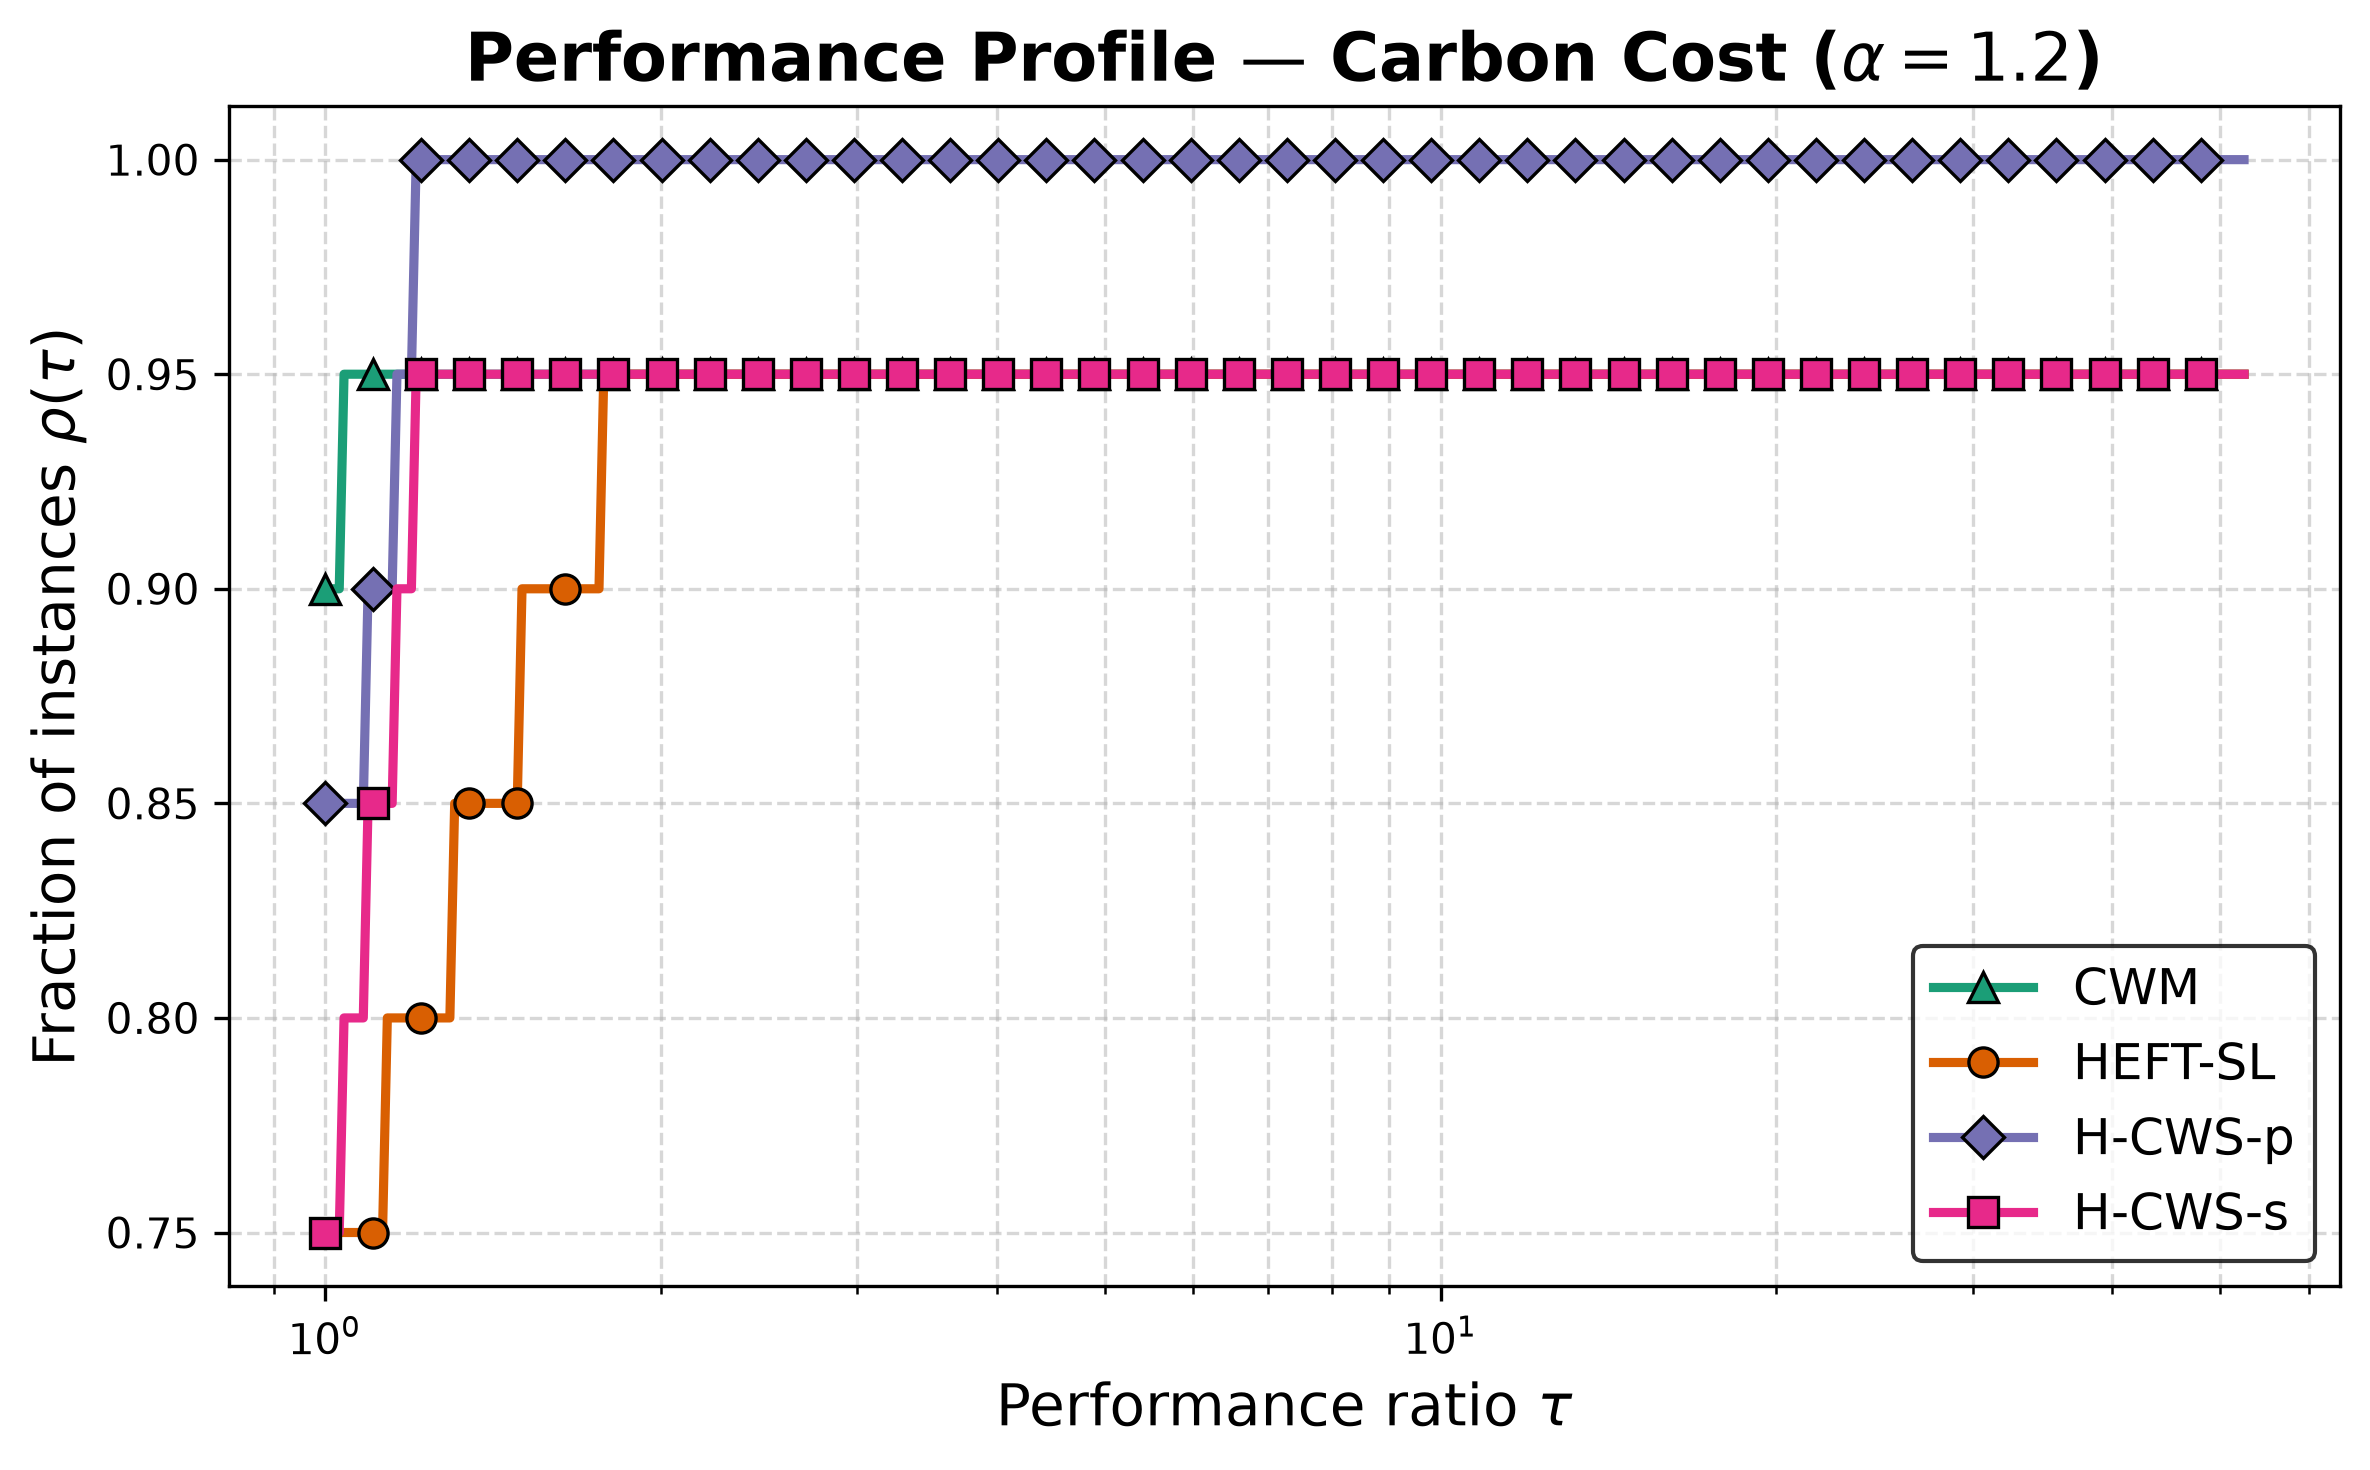

In [13]:


import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ----------------------------------------------
# 1. Ensure numeric cost columns
# ----------------------------------------------

cost_cols = ["cost_cwm", "cost_heft", "cost_pressure", "cost_slack"]

for col in cost_cols:
    combined_df_12[col] = pd.to_numeric(combined_df_12[col], errors="coerce")

# Remove rows where all algorithms are NaN
combined_df_12 = combined_df_12.dropna(subset=cost_cols, how="all")

# Extract cost matrix
costs = combined_df_12[cost_cols].values

# ----------------------------------------------
# 2. Dolan–Moré performance ratios
# ----------------------------------------------
# r[i,a] = t[i,a] / min_k t[i,k]

best = np.nanmin(costs, axis=1).reshape(-1, 1)

# Handle division by 0 or INF (set to huge number)
ratios = costs / best
ratios = np.where(np.isfinite(ratios), ratios, 1e9)  # cap infinities

# ----------------------------------------------
# 3. Compute performance profile curves
# ----------------------------------------------

# Tau range (log scale recommended for large variance)
#taus = np.logspace(0, np.log10(np.nanmax(ratios) * 1.05), 400)
taus = np.logspace(0, np.log10(50 * 1.05), 400)

profiles = {}

for idx, alg in enumerate(cost_cols):
    r = ratios[:, idx]
    profiles[alg] = [np.mean(r <= tau) for tau in taus]

# ----------------------------------------------
# 4. Plot (Publication Quality)
# ----------------------------------------------

plt.figure(figsize=(8, 5), dpi=300)

# Colorblind-friendly palette
colors = {
    "cost_cwm": "#1b9e77",      # green
    "cost_heft": "#d95f02",     # orange
    "cost_pressure": "#7570b3", # purple
    "cost_slack": "#e7298a"     # pink
}

# Marker shapes (distinct)
markers = ['^', 'o', 'D', 's']

# Distinct colors (tab10)
#colors = plt.cm.tab10.colors
algo_labels = {
    "cost_cwm": "CWM",
    "cost_heft": "HEFT-SL",
    "cost_pressure": "H-CWS-p",
    "cost_slack": "H-CWS-s"
}
for (alg, marker) in zip(cost_cols, markers):

    label = algo_labels[alg]

    plt.plot(
        taus,
        profiles[alg],
        label=label,
        linewidth=2.2,
        color=colors[alg],
        marker=marker,
        markevery=10,          # marker frequency along the line
        markersize=7,
        markeredgewidth=0.8,
        markeredgecolor='black'
    )

for alg in cost_cols:
    print(f"{algo_labels[alg]}: {profiles[alg][0]:.4f}")

plt.xscale("log")

# Axis labels
plt.xlabel(r"Performance ratio $\tau$", fontsize=14)
plt.ylabel(r"Fraction of instances $\rho(\tau)$", fontsize=14)
plt.title(r"Performance Profile — Carbon Cost ($\alpha=1.2$)", fontsize=16, weight="bold")

# Grid + aesthetics
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(fontsize=12, frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/perf_profile_12", bbox_inches='tight')
plt.show()

CWM: 0.9500
HEFT-SL: 0.7500
H-CWS-p: 0.8000
H-CWS-s: 0.8500


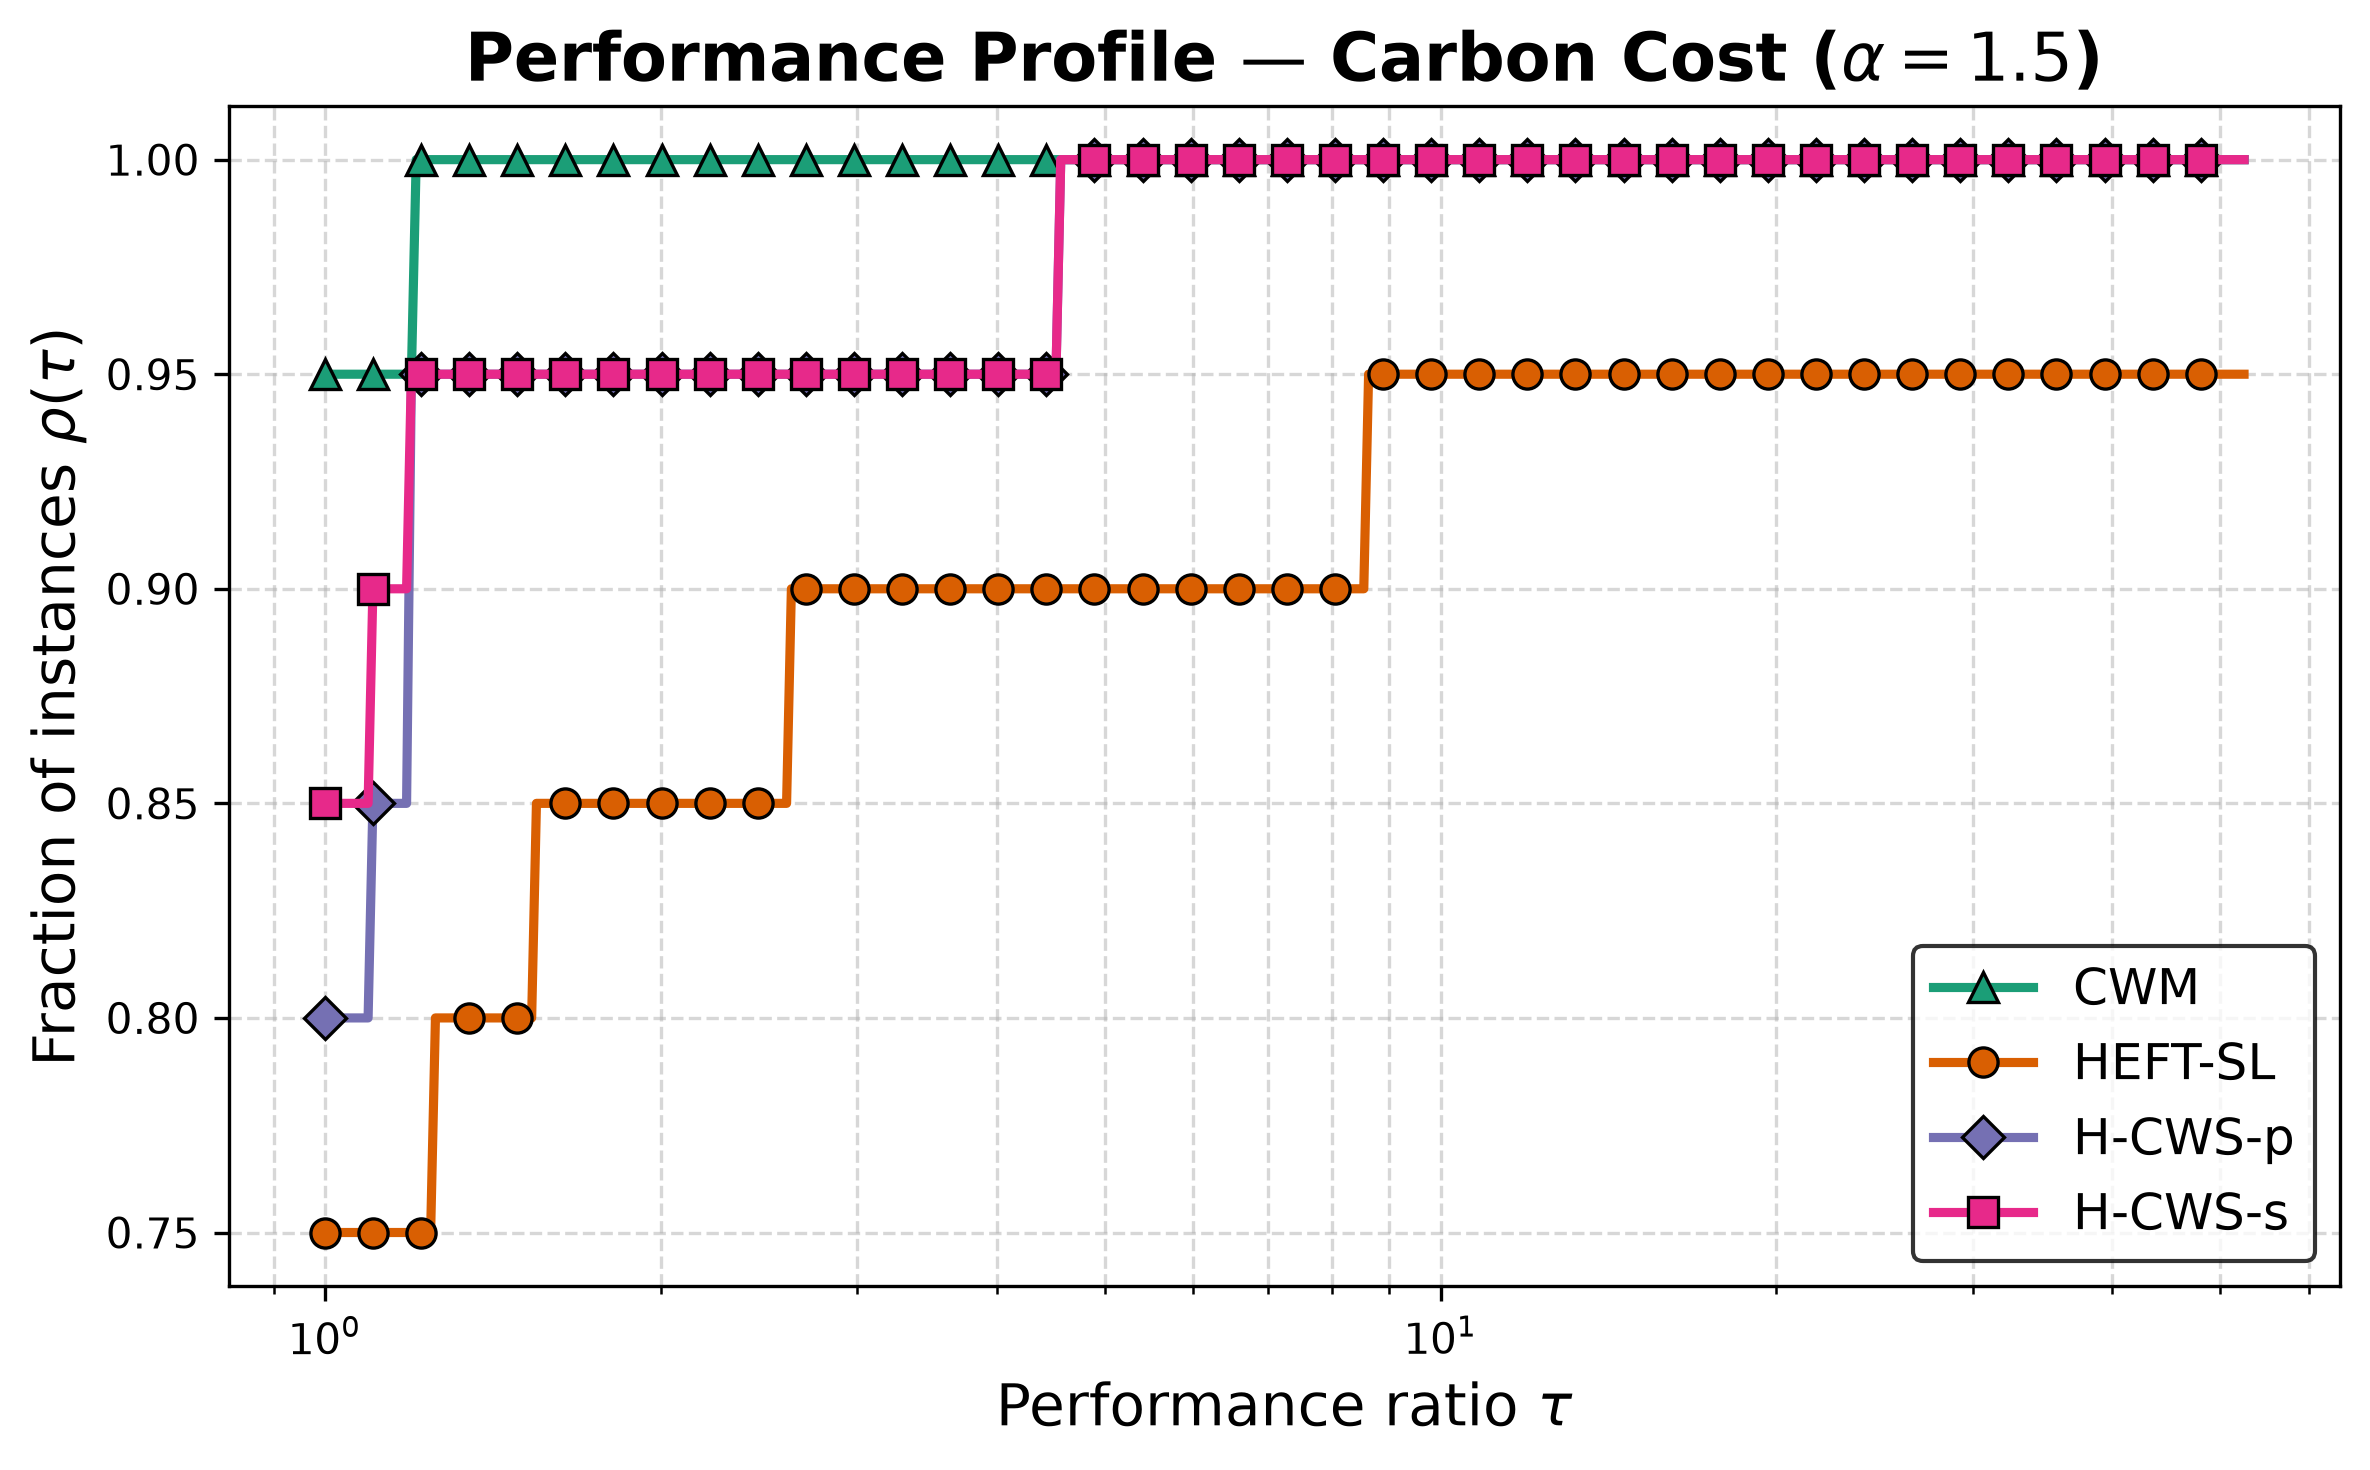

In [14]:


import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ----------------------------------------------
# 1. Ensure numeric cost columns
# ----------------------------------------------

cost_cols = ["cost_cwm", "cost_heft", "cost_pressure", "cost_slack"]

for col in cost_cols:
    combined_df_15[col] = pd.to_numeric(combined_df_15[col], errors="coerce")

# Remove rows where all algorithms are NaN
combined_df_15 = combined_df_15.dropna(subset=cost_cols, how="all")

# Extract cost matrix
costs = combined_df_15[cost_cols].values

# ----------------------------------------------
# 2. Dolan–Moré performance ratios
# ----------------------------------------------
# r[i,a] = t[i,a] / min_k t[i,k]

best = np.nanmin(costs, axis=1).reshape(-1, 1)

# Handle division by 0 or INF (set to huge number)
ratios = costs / best
ratios = np.where(np.isfinite(ratios), ratios, 1e9)  # cap infinities

# ----------------------------------------------
# 3. Compute performance profile curves
# ----------------------------------------------

# Tau range (log scale recommended for large variance)
#taus = np.logspace(0, np.log10(np.nanmax(ratios) * 1.05), 400)
taus = np.logspace(0, np.log10(50 * 1.05), 400)

profiles = {}

for idx, alg in enumerate(cost_cols):
    r = ratios[:, idx]
    profiles[alg] = [np.mean(r <= tau) for tau in taus]

# ----------------------------------------------
# 4. Plot (Publication Quality)
# ----------------------------------------------

plt.figure(figsize=(8, 5), dpi=300)

# Colorblind-friendly palette
colors = {
    "cost_cwm": "#1b9e77",      # green
    "cost_heft": "#d95f02",     # orange
    "cost_pressure": "#7570b3", # purple
    "cost_slack": "#e7298a"     # pink
}
markers = ['^', 'o', 'D', 's']

# Distinct colors (tab10)
#colors = plt.cm.tab10.colors
algo_labels = {
    "cost_cwm": "CWM",
    "cost_heft": "HEFT-SL",
    "cost_pressure": "H-CWS-p",
    "cost_slack": "H-CWS-s"
}
for (alg, marker) in zip(cost_cols, markers):

    label = algo_labels[alg]

    plt.plot(
        taus,
        profiles[alg],
        label=label,
        linewidth=2.2,
        color=colors[alg],
        marker=marker,
        markevery=10,          # marker frequency along the line
        markersize=7,
        markeredgewidth=0.8,
        markeredgecolor='black'
    )

for alg in cost_cols:
    print(f"{algo_labels[alg]}: {profiles[alg][0]:.4f}")
plt.xscale("log")

# Axis labels
plt.xlabel(r"Performance ratio $\tau$", fontsize=14)
plt.ylabel(r"Fraction of instances $\rho(\tau)$", fontsize=14)
plt.title(r"Performance Profile — Carbon Cost ($\alpha=1.5$)", fontsize=16, weight="bold")

# Grid + aesthetics
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(fontsize=12, frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/perf_profile_15", bbox_inches='tight')
plt.show()

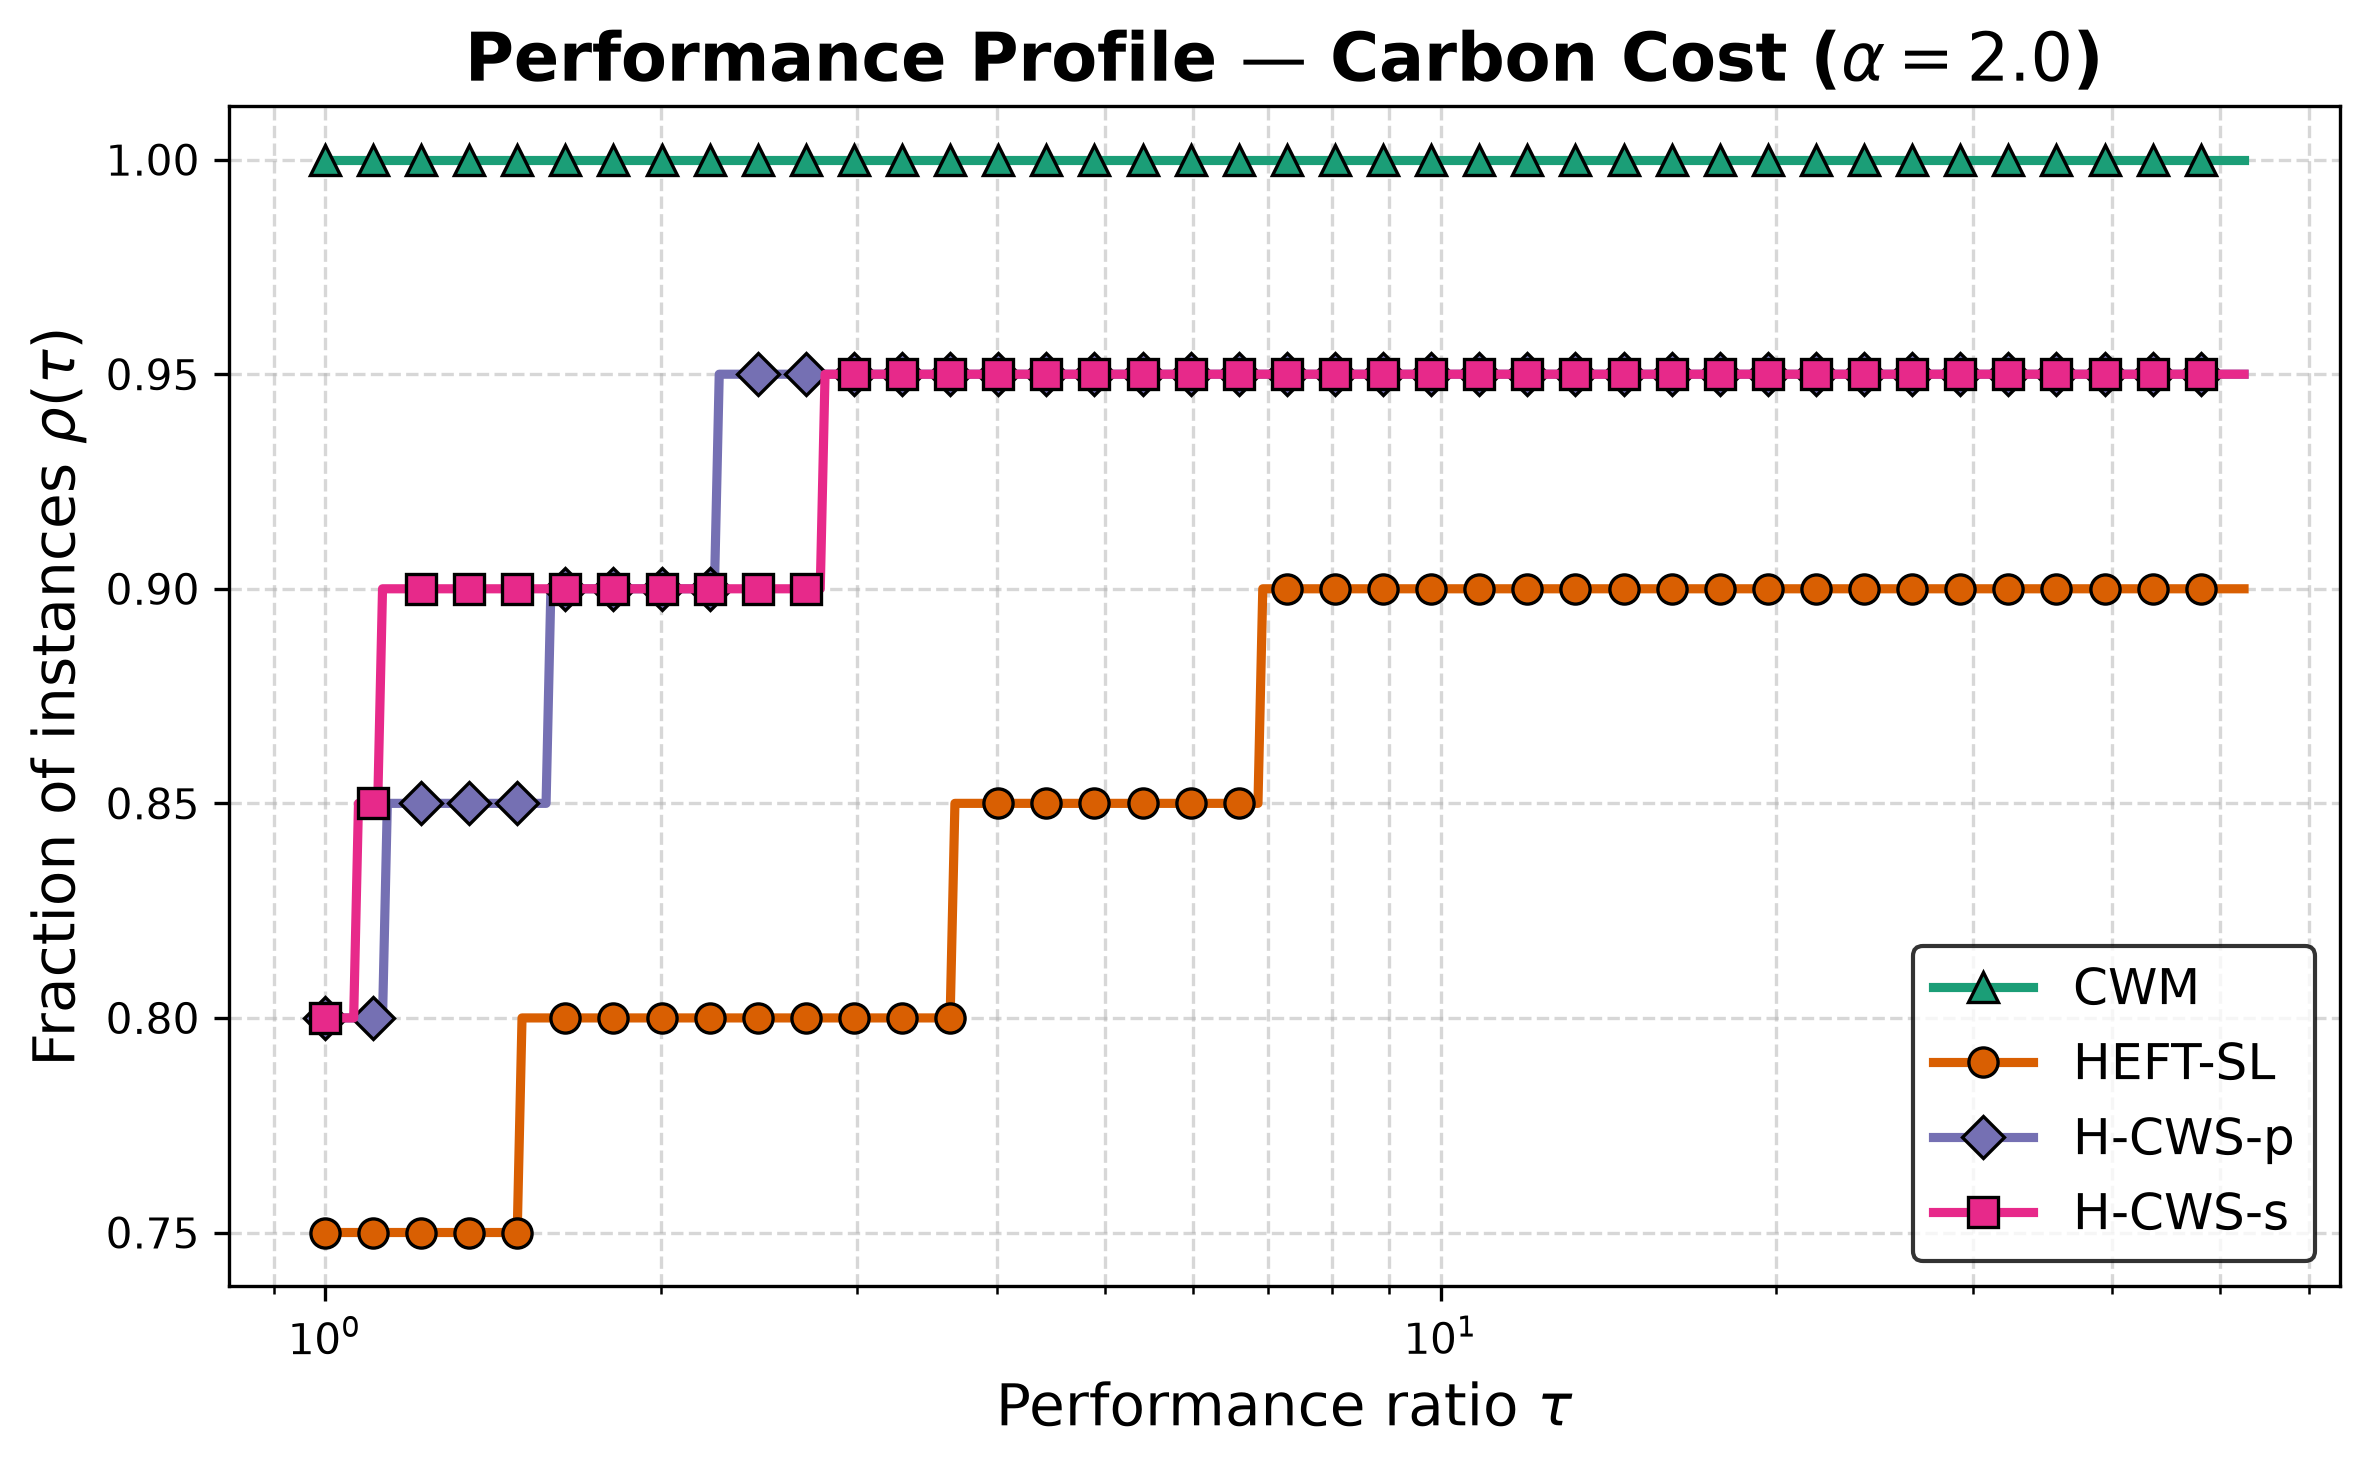

In [15]:


import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ----------------------------------------------
# 1. Ensure numeric cost columns
# ----------------------------------------------

cost_cols = ["cost_cwm", "cost_heft", "cost_pressure", "cost_slack"]

for col in cost_cols:
    combined_df_20[col] = pd.to_numeric(combined_df_20[col], errors="coerce")

# Remove rows where all algorithms are NaN
combined_df_20 = combined_df_20.dropna(subset=cost_cols, how="all")

# Extract cost matrix
costs = combined_df_20[cost_cols].values

# ----------------------------------------------
# 2. Dolan–Moré performance ratios
# ----------------------------------------------
# r[i,a] = t[i,a] / min_k t[i,k]

best = np.nanmin(costs, axis=1).reshape(-1, 1)

# Handle division by 0 or INF (set to huge number)
ratios = costs / best
ratios = np.where(np.isfinite(ratios), ratios, 1e9)  # cap infinities

# ----------------------------------------------
# 3. Compute performance profile curves
# ----------------------------------------------

# Tau range (log scale recommended for large variance)
#taus = np.logspace(0, np.log10(np.nanmax(ratios) * 1.05), 400)
taus = np.logspace(0, np.log10(50 * 1.05), 400)

profiles = {}

for idx, alg in enumerate(cost_cols):
    r = ratios[:, idx]
    profiles[alg] = [np.mean(r <= tau) for tau in taus]

# ----------------------------------------------
# 4. Plot (Publication Quality)
# ----------------------------------------------

plt.figure(figsize=(8, 5), dpi=300)

# Colorblind-friendly palette
colors = {
    "cost_cwm": "#1b9e77",      # green
    "cost_heft": "#d95f02",     # orange
    "cost_pressure": "#7570b3", # purple
    "cost_slack": "#e7298a"     # pink
}

# Marker shapes (distinct)
markers = ['^', 'o', 'D', 's']

# Distinct colors (tab10)
# colors = plt.cm.tab10.colors
algo_labels = {
    "cost_cwm": "CWM",
    "cost_heft": "HEFT-SL",
    "cost_pressure": "H-CWS-p",
    "cost_slack": "H-CWS-s"
}
for (alg, marker) in zip(cost_cols, markers):

    label = algo_labels[alg]

    plt.plot(
        taus,
        profiles[alg],
        label=label,
        linewidth=2.2,
        color=colors[alg],
        marker=marker,
        markevery=10,          # marker frequency along the line
        markersize=7,
        markeredgewidth=0.8,
        markeredgecolor='black'
    )


plt.xscale("log")

# Axis labels
plt.xlabel(r"Performance ratio $\tau$", fontsize=14)
plt.ylabel(r"Fraction of instances $\rho(\tau)$", fontsize=14)
plt.title(r"Performance Profile — Carbon Cost ($\alpha=2.0$)", fontsize=16, weight="bold")

# Grid + aesthetics
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(fontsize=12, frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/perf_profile_20", bbox_inches='tight')
plt.show()

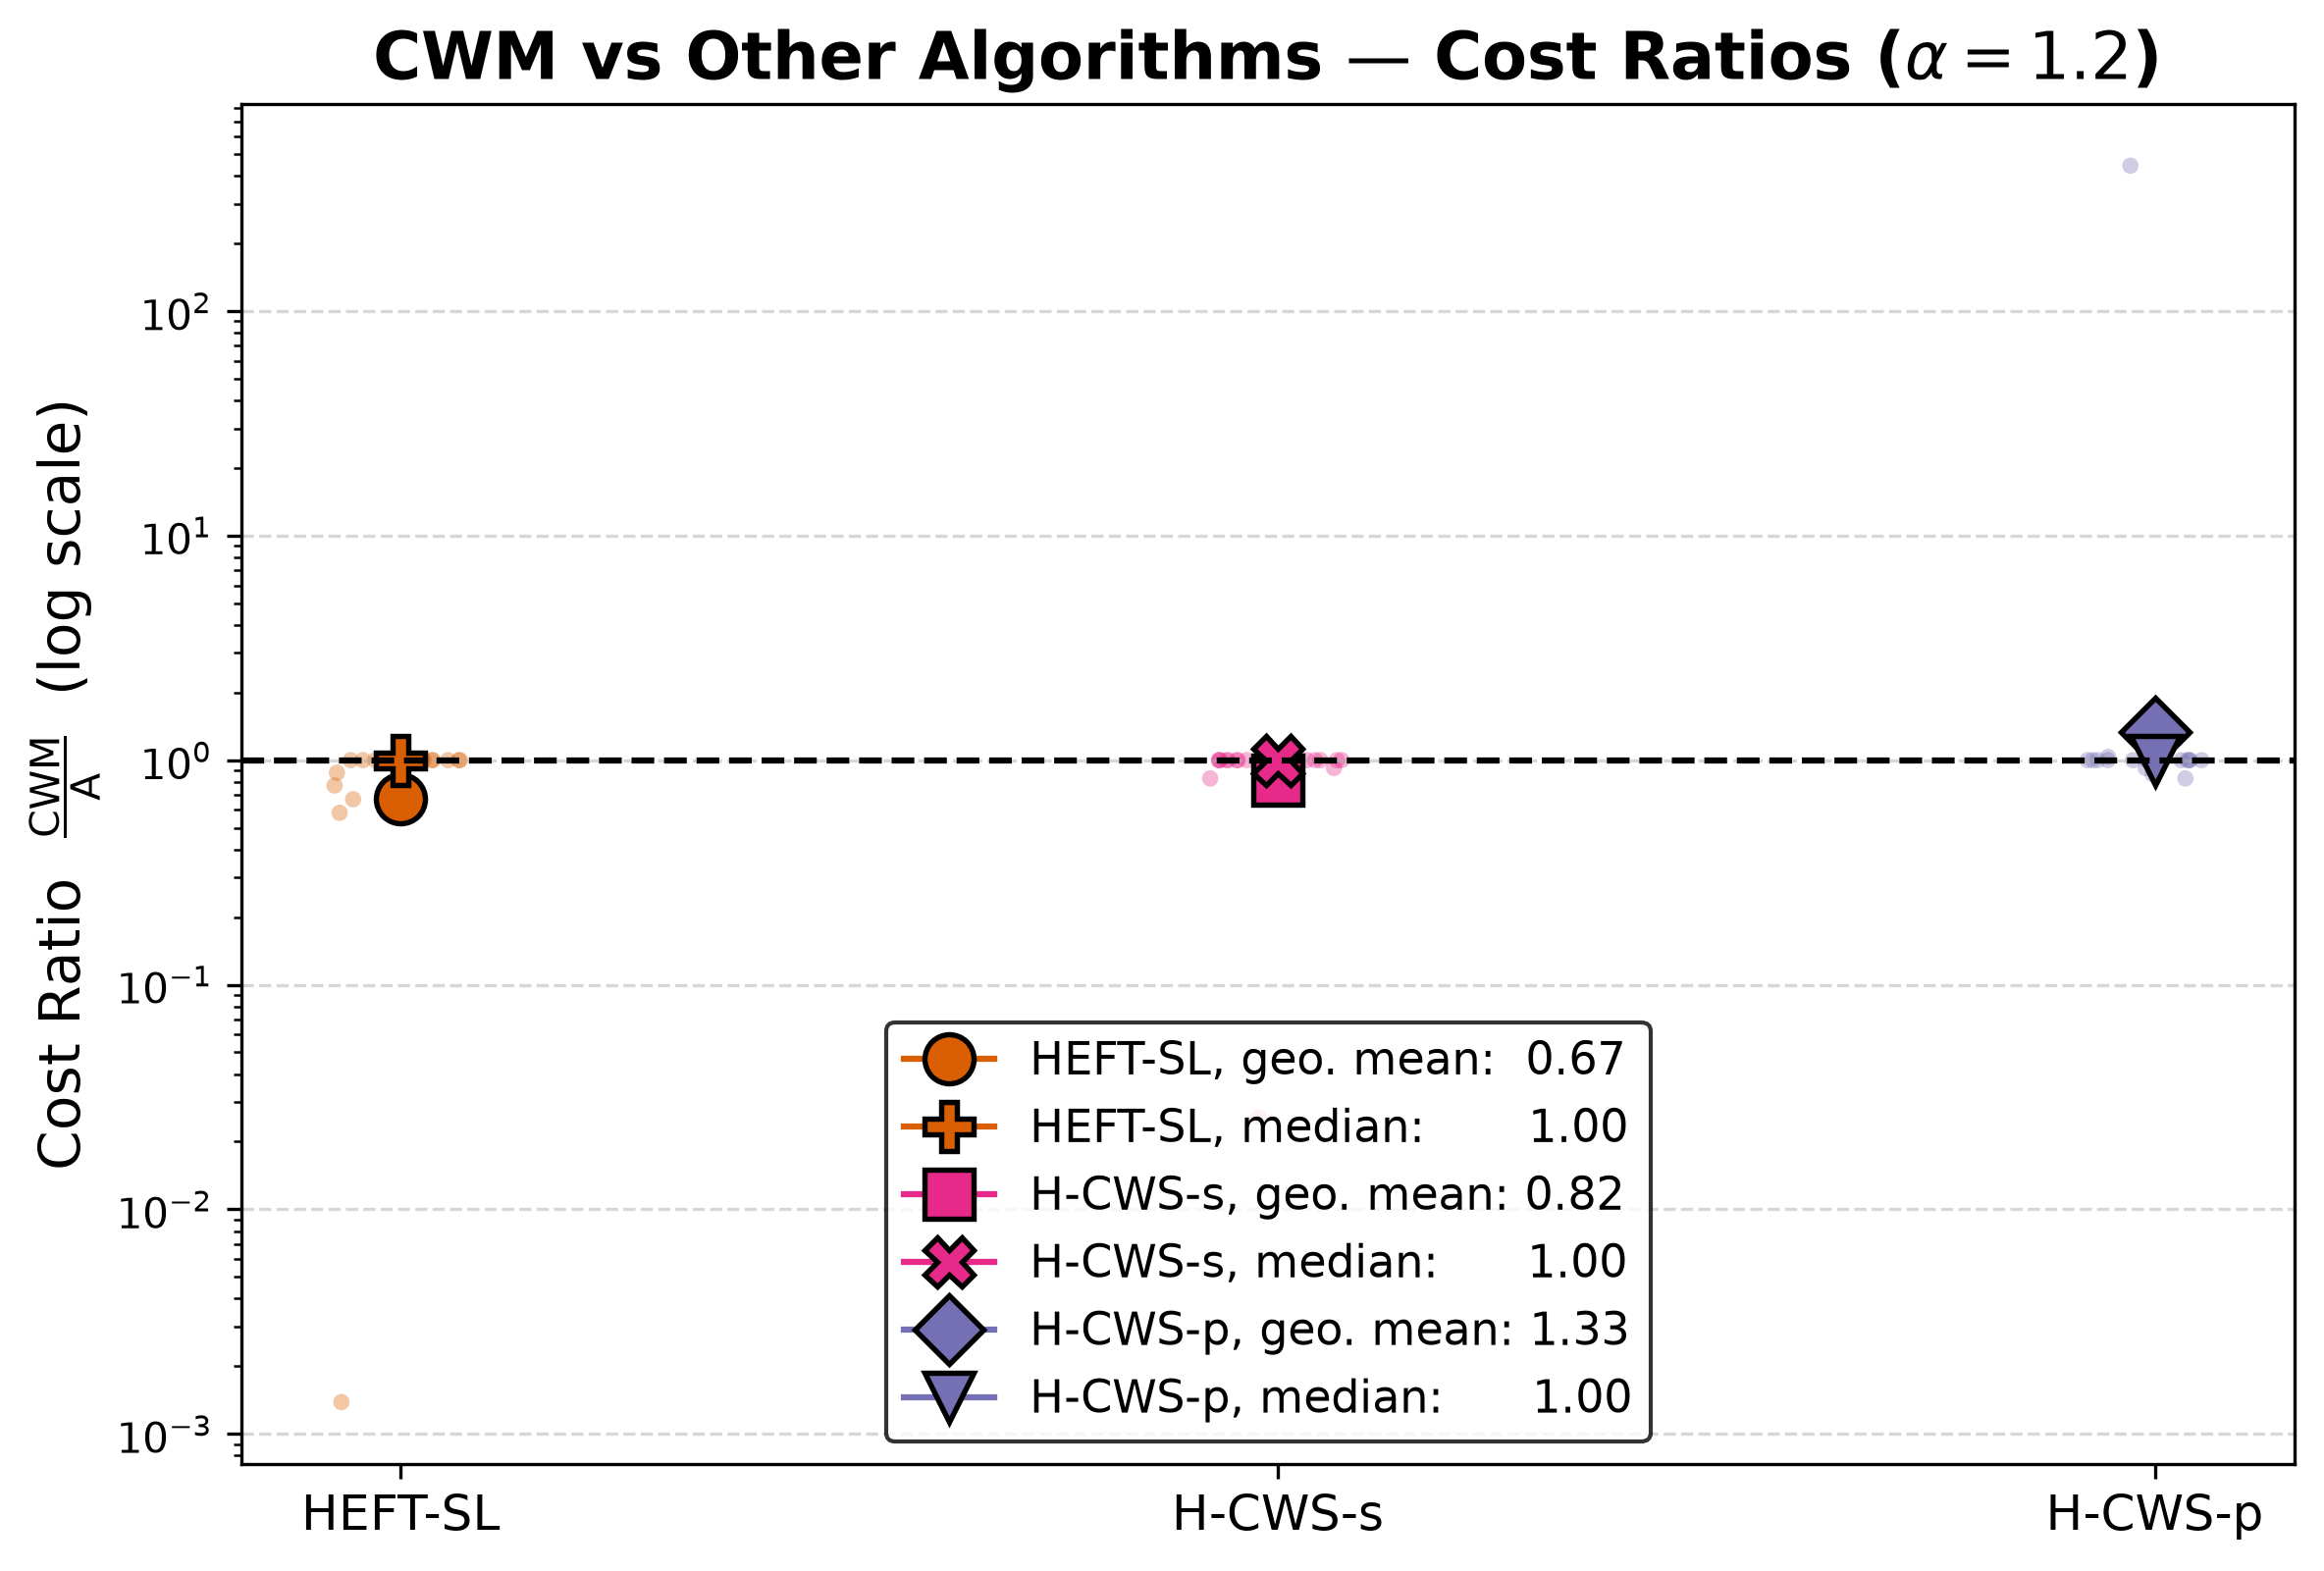

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.table import Table
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     (combined_df_12["cost_cwm"]) / (combined_df_12["cost_heft"]),
    "H-CWS-s":    (combined_df_12["cost_cwm"]) / (combined_df_12["cost_slack"]),
    "H-CWS-p": (combined_df_12["cost_cwm"]) / (combined_df_12["cost_pressure"]),
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
median_markers = ["P", "X", "v"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.2$)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black", loc="lower center") #, bbox_to_anchor=(1.40, 0.45))


# ----------------------------------------------------
# 3. Embedded Zoom Subplot (inside the main plot)
# ----------------------------------------------------
"""
ax_zoom = inset_axes(
    ax,
    width="85%",         # size relative to parent axis
    height="75%",
    bbox_to_anchor=(0.95, 0.01, 0.45, 0.35),
    bbox_transform=ax.transAxes,
    borderpad=0
)

for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.06, 0.06, size=len(r))
    mask = (r >= ZOOM_LOWER) & (r <= ZOOM_UPPER)

    # scatter zoomed points
    ax_zoom.scatter(
        np.full_like(r[mask], x_positions[i]) + jitter[mask],
        r[mask],
        s=20,
        alpha=0.45,
        color=colors[i],
        edgecolors="none"
    )

    # geometric mean (only if inside zoom range)
    gm = geo_means[alg]
    if ZOOM_LOWER <= gm <= ZOOM_UPPER:
        ax_zoom.plot(
            x_positions[i],
            gm,
            marker=markers[i],
            markersize=9,
            markeredgewidth=1.1,
            markeredgecolor="black",
            color=colors[i]
        )

ax_zoom.axhline(1.0, linestyle="--", color="black")
ax_zoom.set_ylim(ZOOM_LOWER, ZOOM_UPPER)

ax_zoom.set_xticks(x_positions)
ax_zoom.set_xticklabels([])  # clean look
ax_zoom.set_yticks([])

#ax_zoom.set_title("Zoom", fontsize=10)
"""
#plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_12.png", bbox_inches='tight')
plt.show()

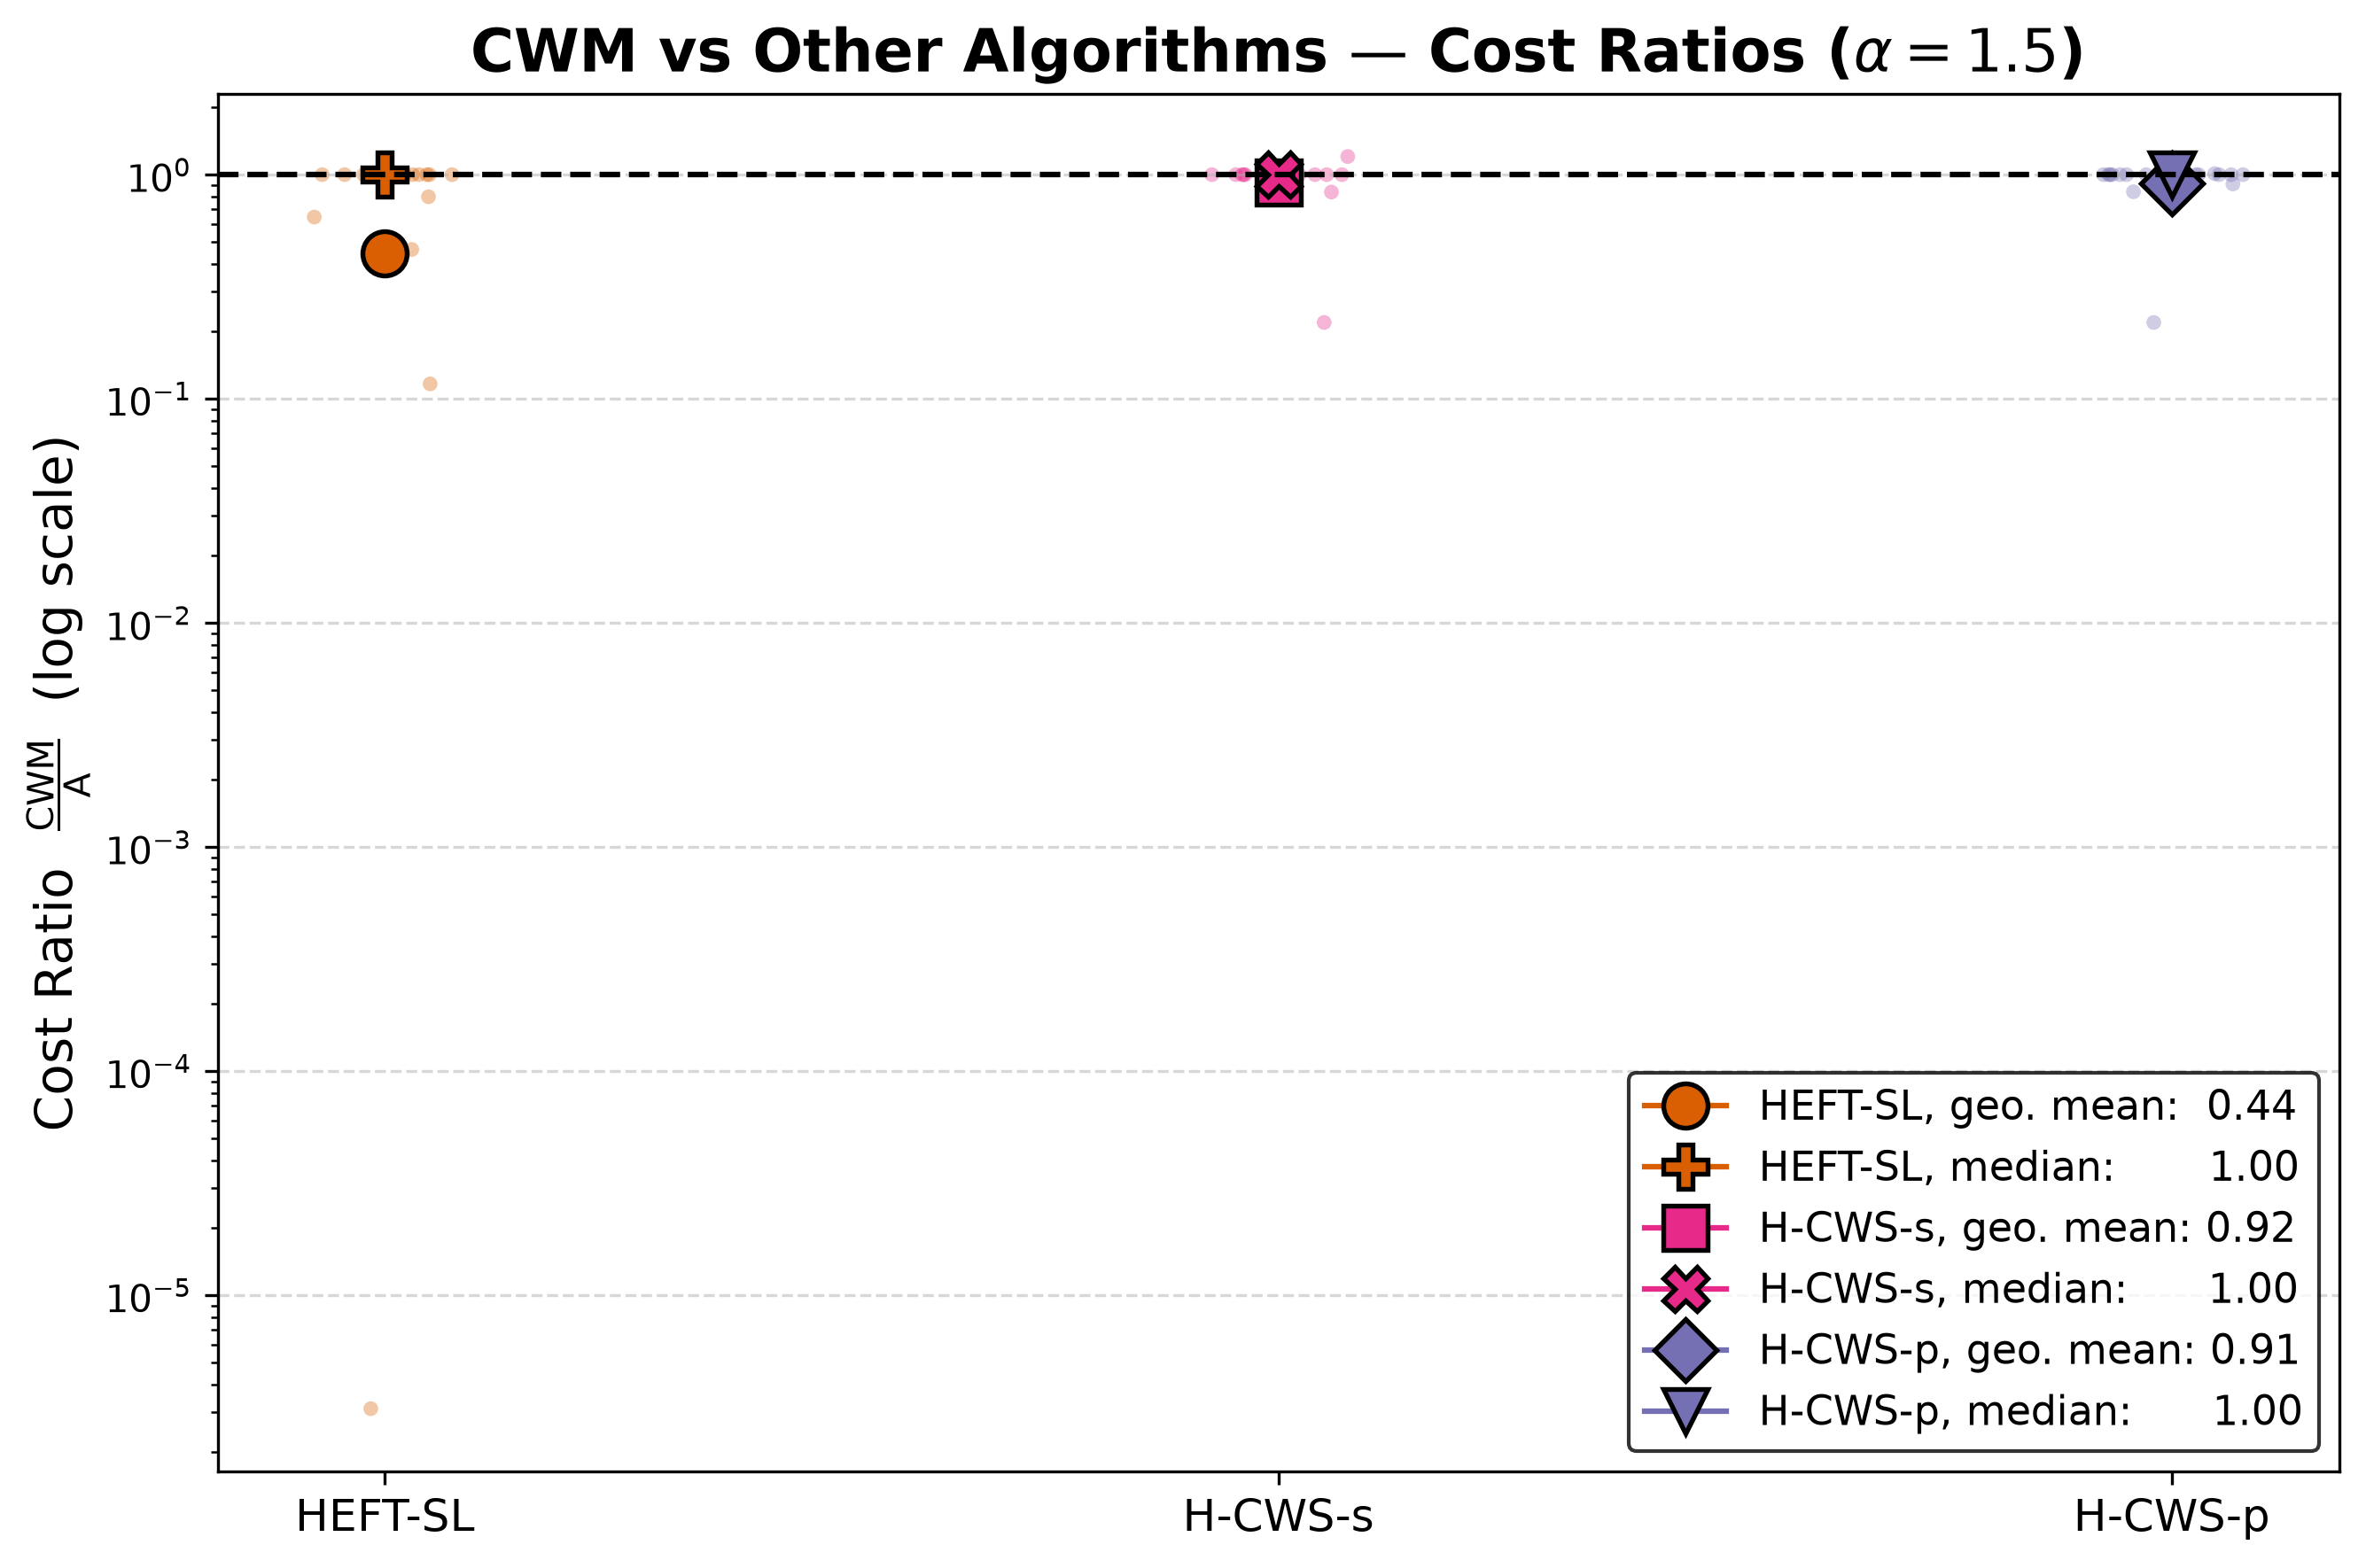

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_15["cost_cwm"] / combined_df_15["cost_heft"],
    "H-CWS-s":    combined_df_15["cost_cwm"] / combined_df_15["cost_slack"],
    "H-CWS-p": combined_df_15["cost_cwm"] / combined_df_15["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )



ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.5$)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")






plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_15.png", bbox_inches='tight')
plt.show()

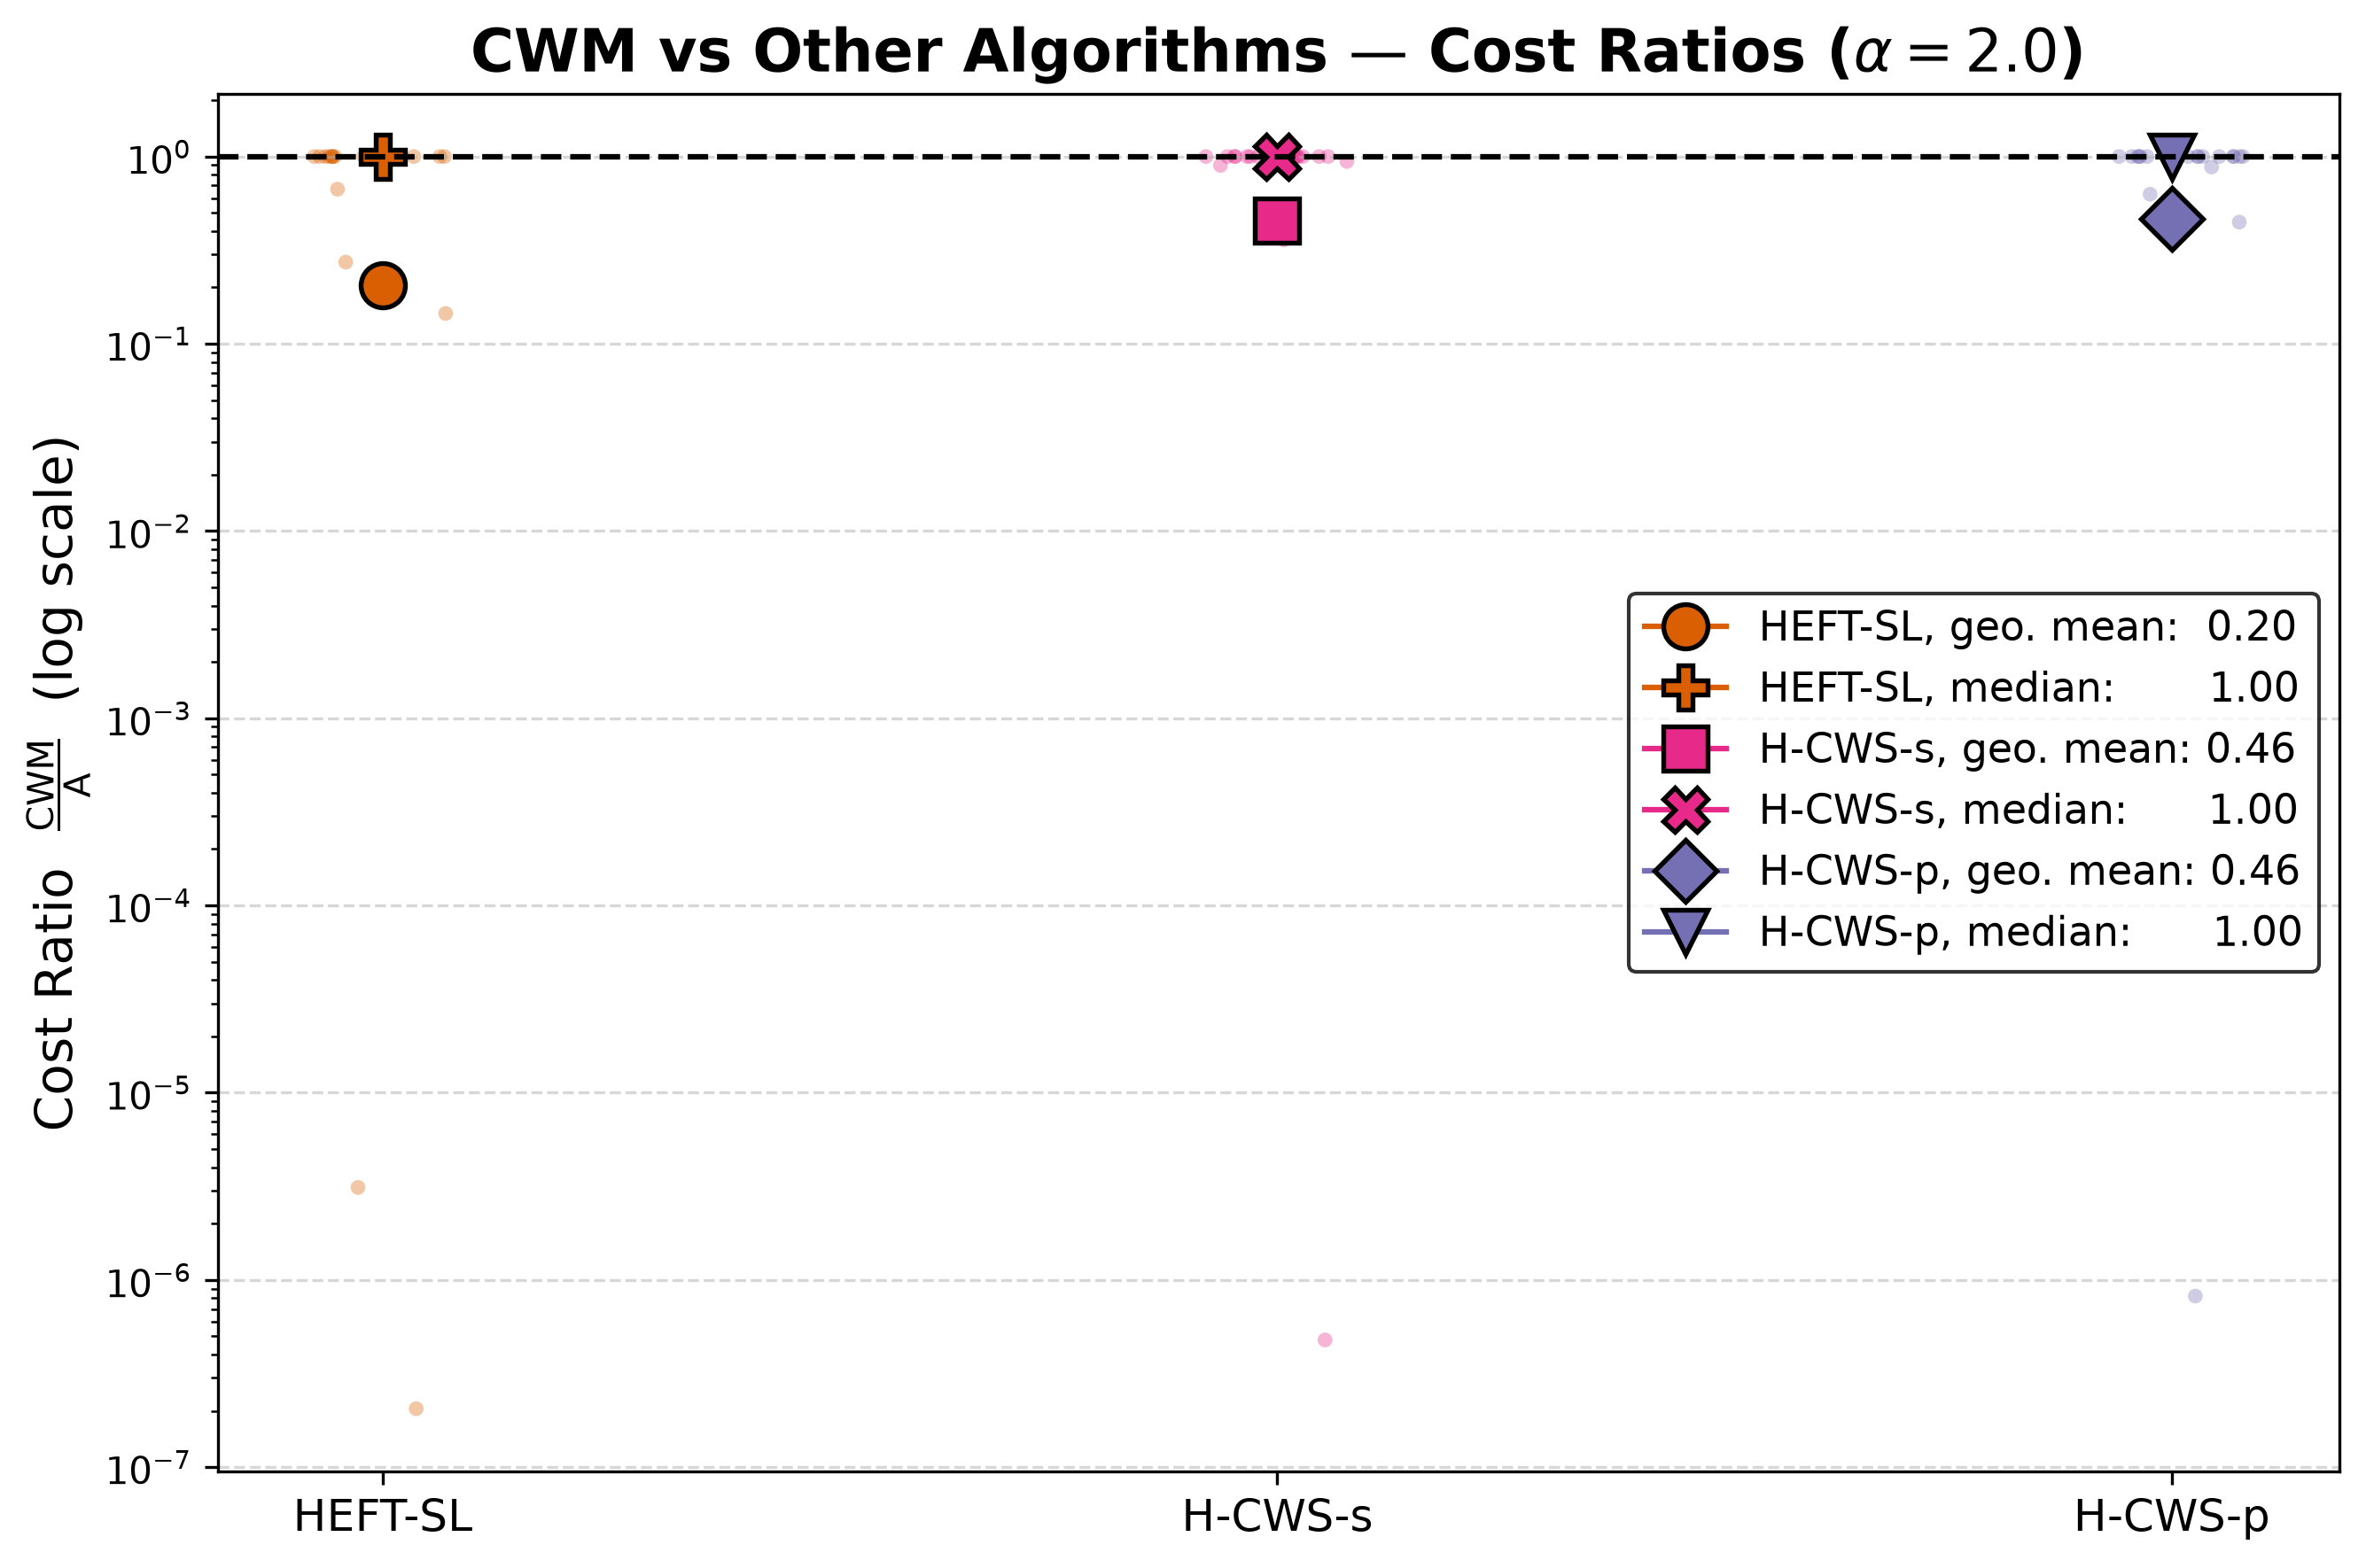

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_20["cost_cwm"] / combined_df_20["cost_heft"],
    "H-CWS-s":    combined_df_20["cost_cwm"] / combined_df_20["cost_slack"],
    "H-CWS-p": combined_df_20["cost_cwm"] / combined_df_20["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}
# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}


algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=2.0$)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")






plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_20.png", bbox_inches='tight')
plt.show()

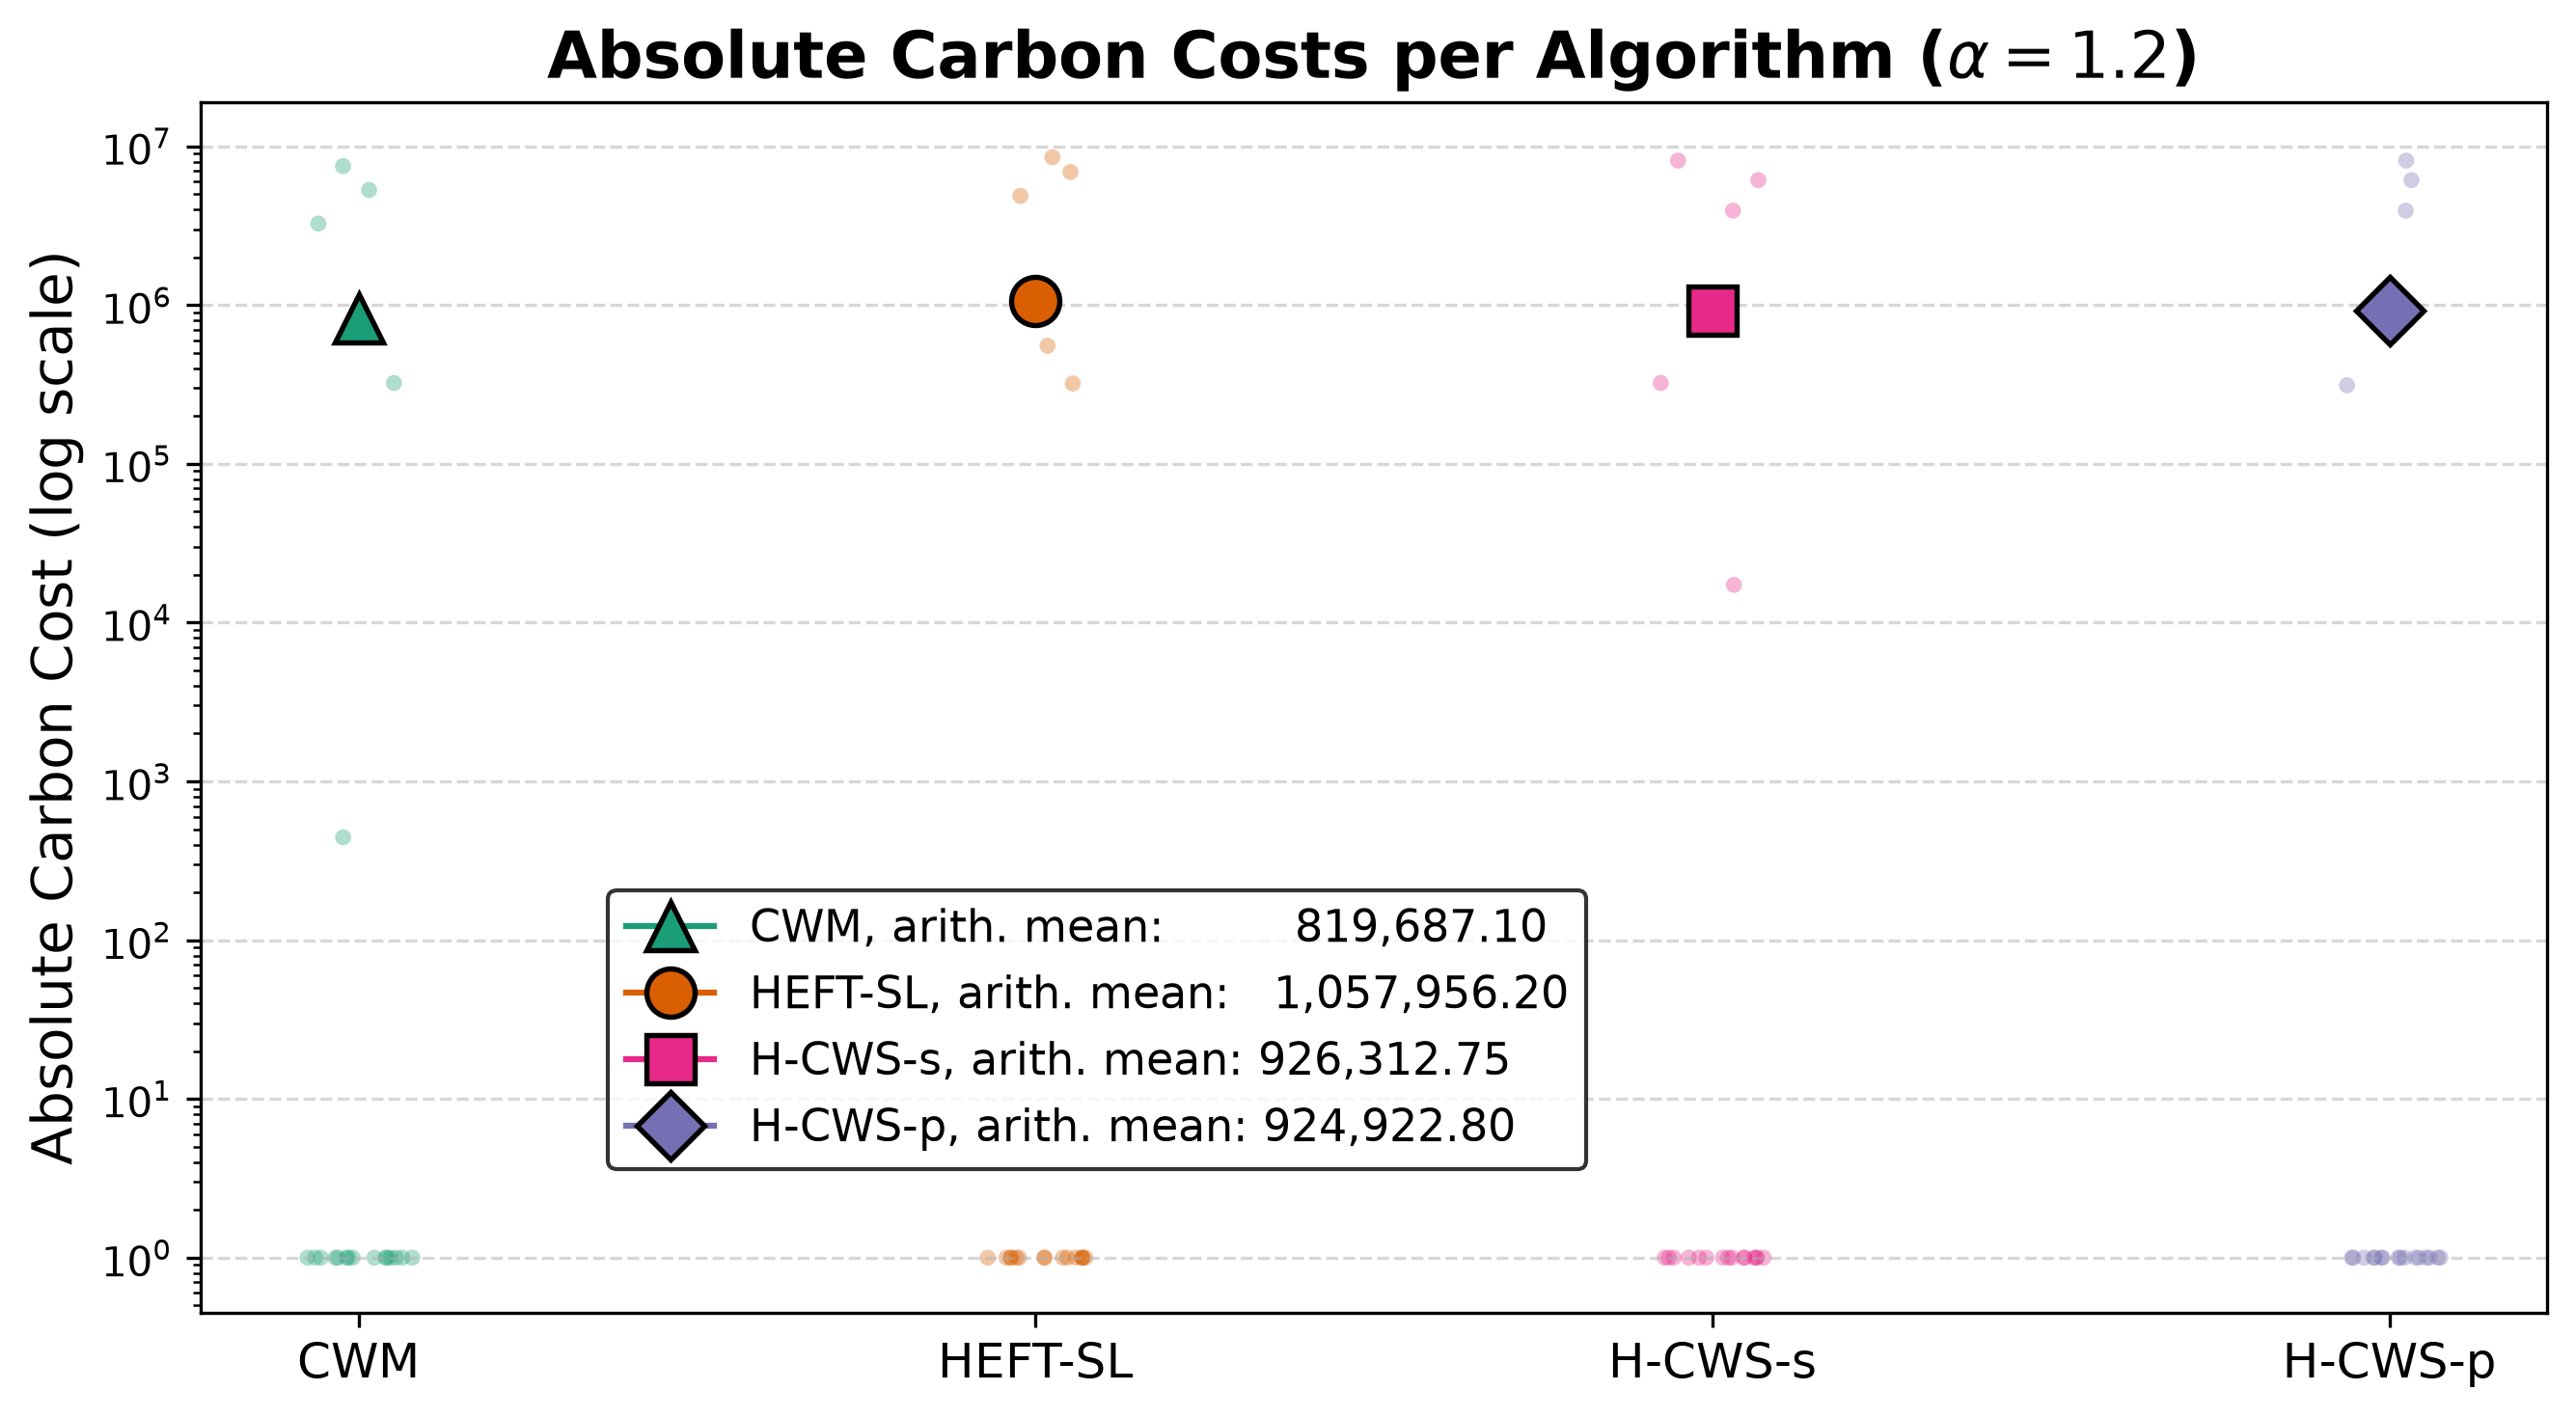

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------
# 1. Extract absolute costs for each algorithm
# ----------------------------------------------------
abs_costs = {
    "CWM":      combined_df_12["cost_cwm"],
    "HEFT-SL":     combined_df_12["cost_heft"],
    "H-CWS-s":    combined_df_12["cost_slack"],
    "H-CWS-p": combined_df_12["cost_pressure"],
}

# Clean invalid entries
for k in abs_costs:
    abs_costs[k] = pd.to_numeric(abs_costs[k], errors="coerce")
    abs_costs[k] = abs_costs[k].replace([np.inf, -np.inf], np.nan).dropna()

# ----------------------------------------------------
# 2. Compute geometric means
# ----------------------------------------------------
geo_means_abs = {k: np.exp(np.mean(np.log(v))) for k, v in abs_costs.items()}
arith_means_abs = {k: np.mean(v) for k, v in abs_costs.items()}

algos_abs = list(abs_costs.keys())
colors = ["#1b9e77", "#d95f02", "#e7298a", "#7570b3"]   # same palette as before
markers = ["^", "o", "s", "D"]
x_positions = np.arange(len(algos_abs))

# ----------------------------------------------------
# 3. Plot absolute cost distributions
# ----------------------------------------------------
plt.figure(figsize=(9, 5), dpi=300)

for i, alg in enumerate(algos_abs):
    values = abs_costs[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(values))

    # point cloud
    plt.scatter(
        np.full_like(values, x_positions[i]) + jitter,
        values,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "CWM":
      label_text = f"{alg}, arith. mean: {arith_means_abs[alg]:18,.2f}"
    else:
      if alg == "HEFT-SL":
        label_text = f"{alg}, arith. mean: {arith_means_abs[alg]:14,.2f}"
      else:
        label_text = f"{alg}, arith. mean: {arith_means_abs[alg]:,.2f}"
    # arithmetic mean marker
    plt.plot(
        x_positions[i],
        arith_means_abs[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

plt.yscale("log")
plt.xticks(x_positions, algos_abs, fontsize=12)

plt.ylabel("Absolute Carbon Cost (log scale)", fontsize=14)
plt.title(r"Absolute Carbon Costs per Algorithm ($\alpha=1.2$)", fontsize=16, weight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(fontsize=11, frameon=True, edgecolor="black", loc="lower right", bbox_to_anchor=(0.6, 0.1))

plt.tight_layout()
plt.savefig("plots/shifted/absolute_cost_12.png", bbox_inches='tight')
plt.show()

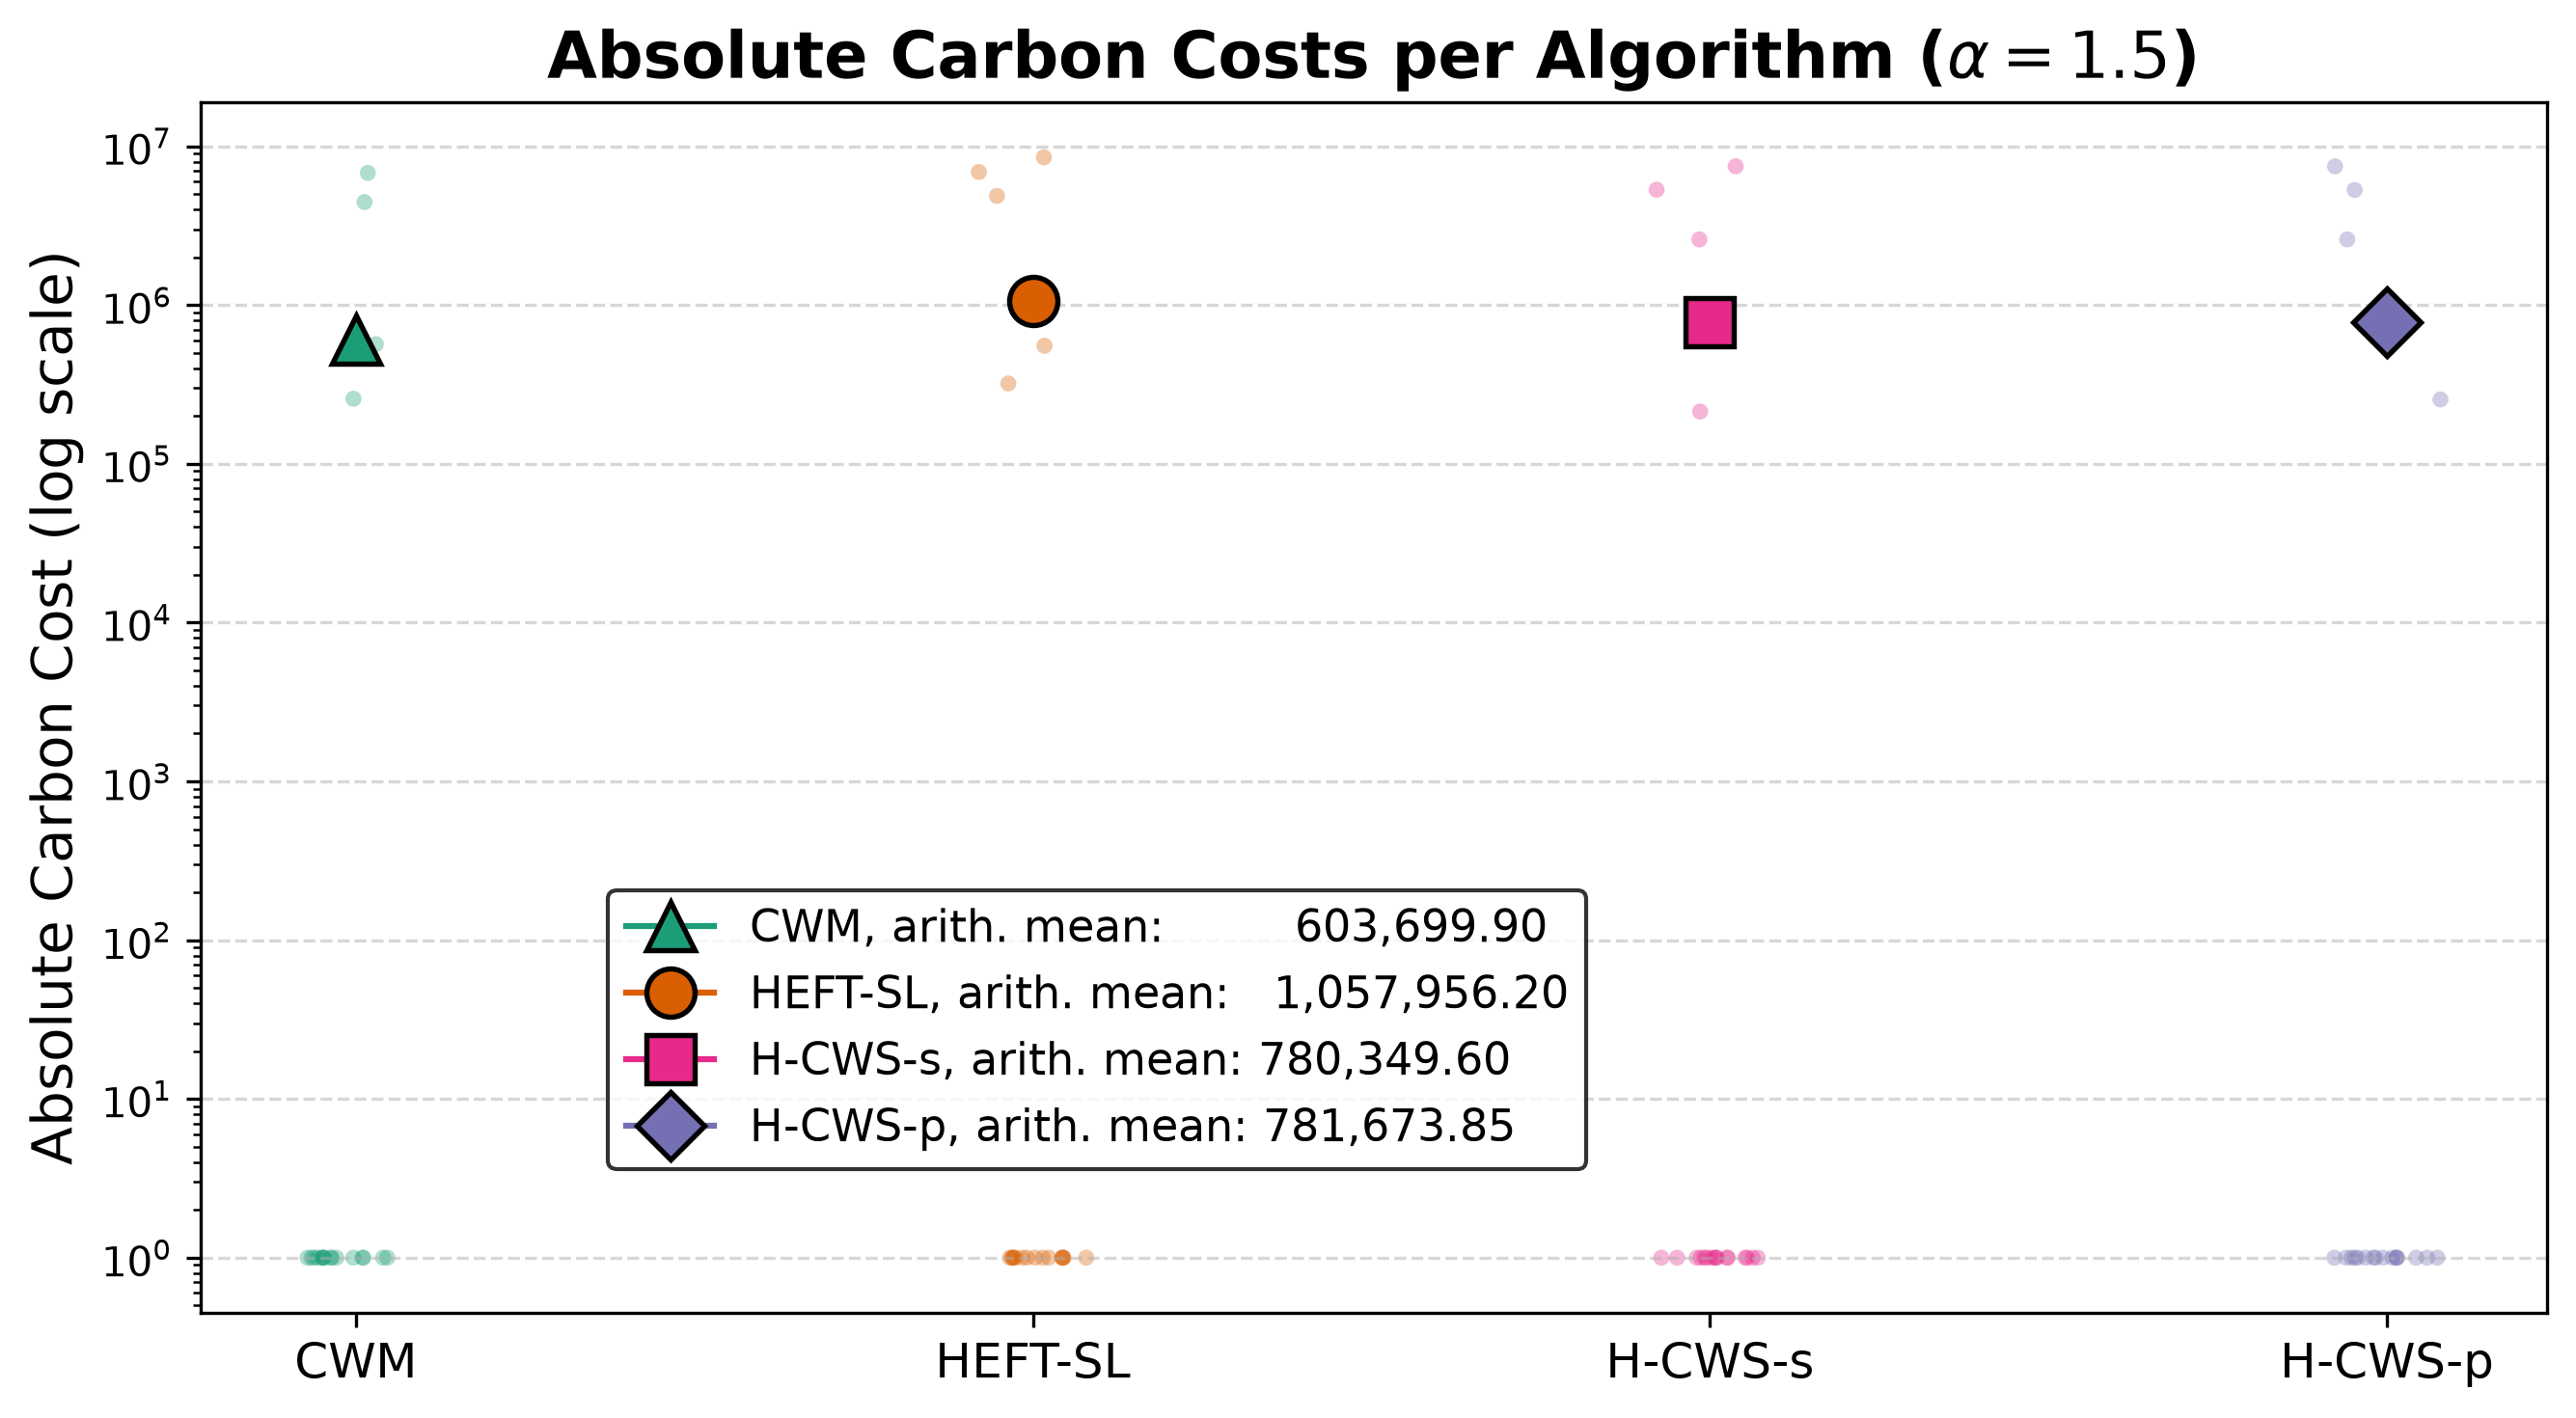

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------
# 1. Extract absolute costs for each algorithm
# ----------------------------------------------------
abs_costs = {
    "CWM":      combined_df_15["cost_cwm"],
    "HEFT-SL":     combined_df_15["cost_heft"],
    "H-CWS-s":    combined_df_15["cost_slack"],
    "H-CWS-p": combined_df_15["cost_pressure"],
}

# Clean invalid entries
for k in abs_costs:
    abs_costs[k] = pd.to_numeric(abs_costs[k], errors="coerce")
    abs_costs[k] = abs_costs[k].replace([np.inf, -np.inf], np.nan).dropna()

# ----------------------------------------------------
# 2. Compute geometric means
# ----------------------------------------------------
geo_means_abs = {k: np.exp(np.mean(np.log(v))) for k, v in abs_costs.items()}
arith_means_abs = {k: np.mean(v) for k, v in abs_costs.items()}

algos_abs = list(abs_costs.keys())
colors = ["#1b9e77", "#d95f02", "#e7298a", "#7570b3"]   # same palette as before
markers = ["^", "o", "s", "D"]
x_positions = np.arange(len(algos_abs))

# ----------------------------------------------------
# 3. Plot absolute cost distributions
# ----------------------------------------------------
plt.figure(figsize=(9, 5), dpi=300)

for i, alg in enumerate(algos_abs):
    values = abs_costs[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(values))

    # point cloud
    plt.scatter(
        np.full_like(values, x_positions[i]) + jitter,
        values,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "CWM":
      label_text = f"{alg}, arith. mean: {arith_means_abs[alg]:18,.2f}"
    else:
      if alg == "HEFT-SL":
        label_text = f"{alg}, arith. mean: {arith_means_abs[alg]:14,.2f}"
      else:
        label_text = f"{alg}, arith. mean: {arith_means_abs[alg]:,.2f}"
    # arithmetic mean marker
    plt.plot(
        x_positions[i],
        arith_means_abs[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

plt.yscale("log")
plt.xticks(x_positions, algos_abs, fontsize=12)

plt.ylabel("Absolute Carbon Cost (log scale)", fontsize=14)
plt.title(r"Absolute Carbon Costs per Algorithm ($\alpha=1.5$)", fontsize=16, weight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(fontsize=11, frameon=True, edgecolor="black", loc="lower right", bbox_to_anchor=(0.6, 0.1))
plt.tight_layout()
plt.savefig("plots/shifted/absolute_cost_15.png", bbox_inches='tight')
plt.show()

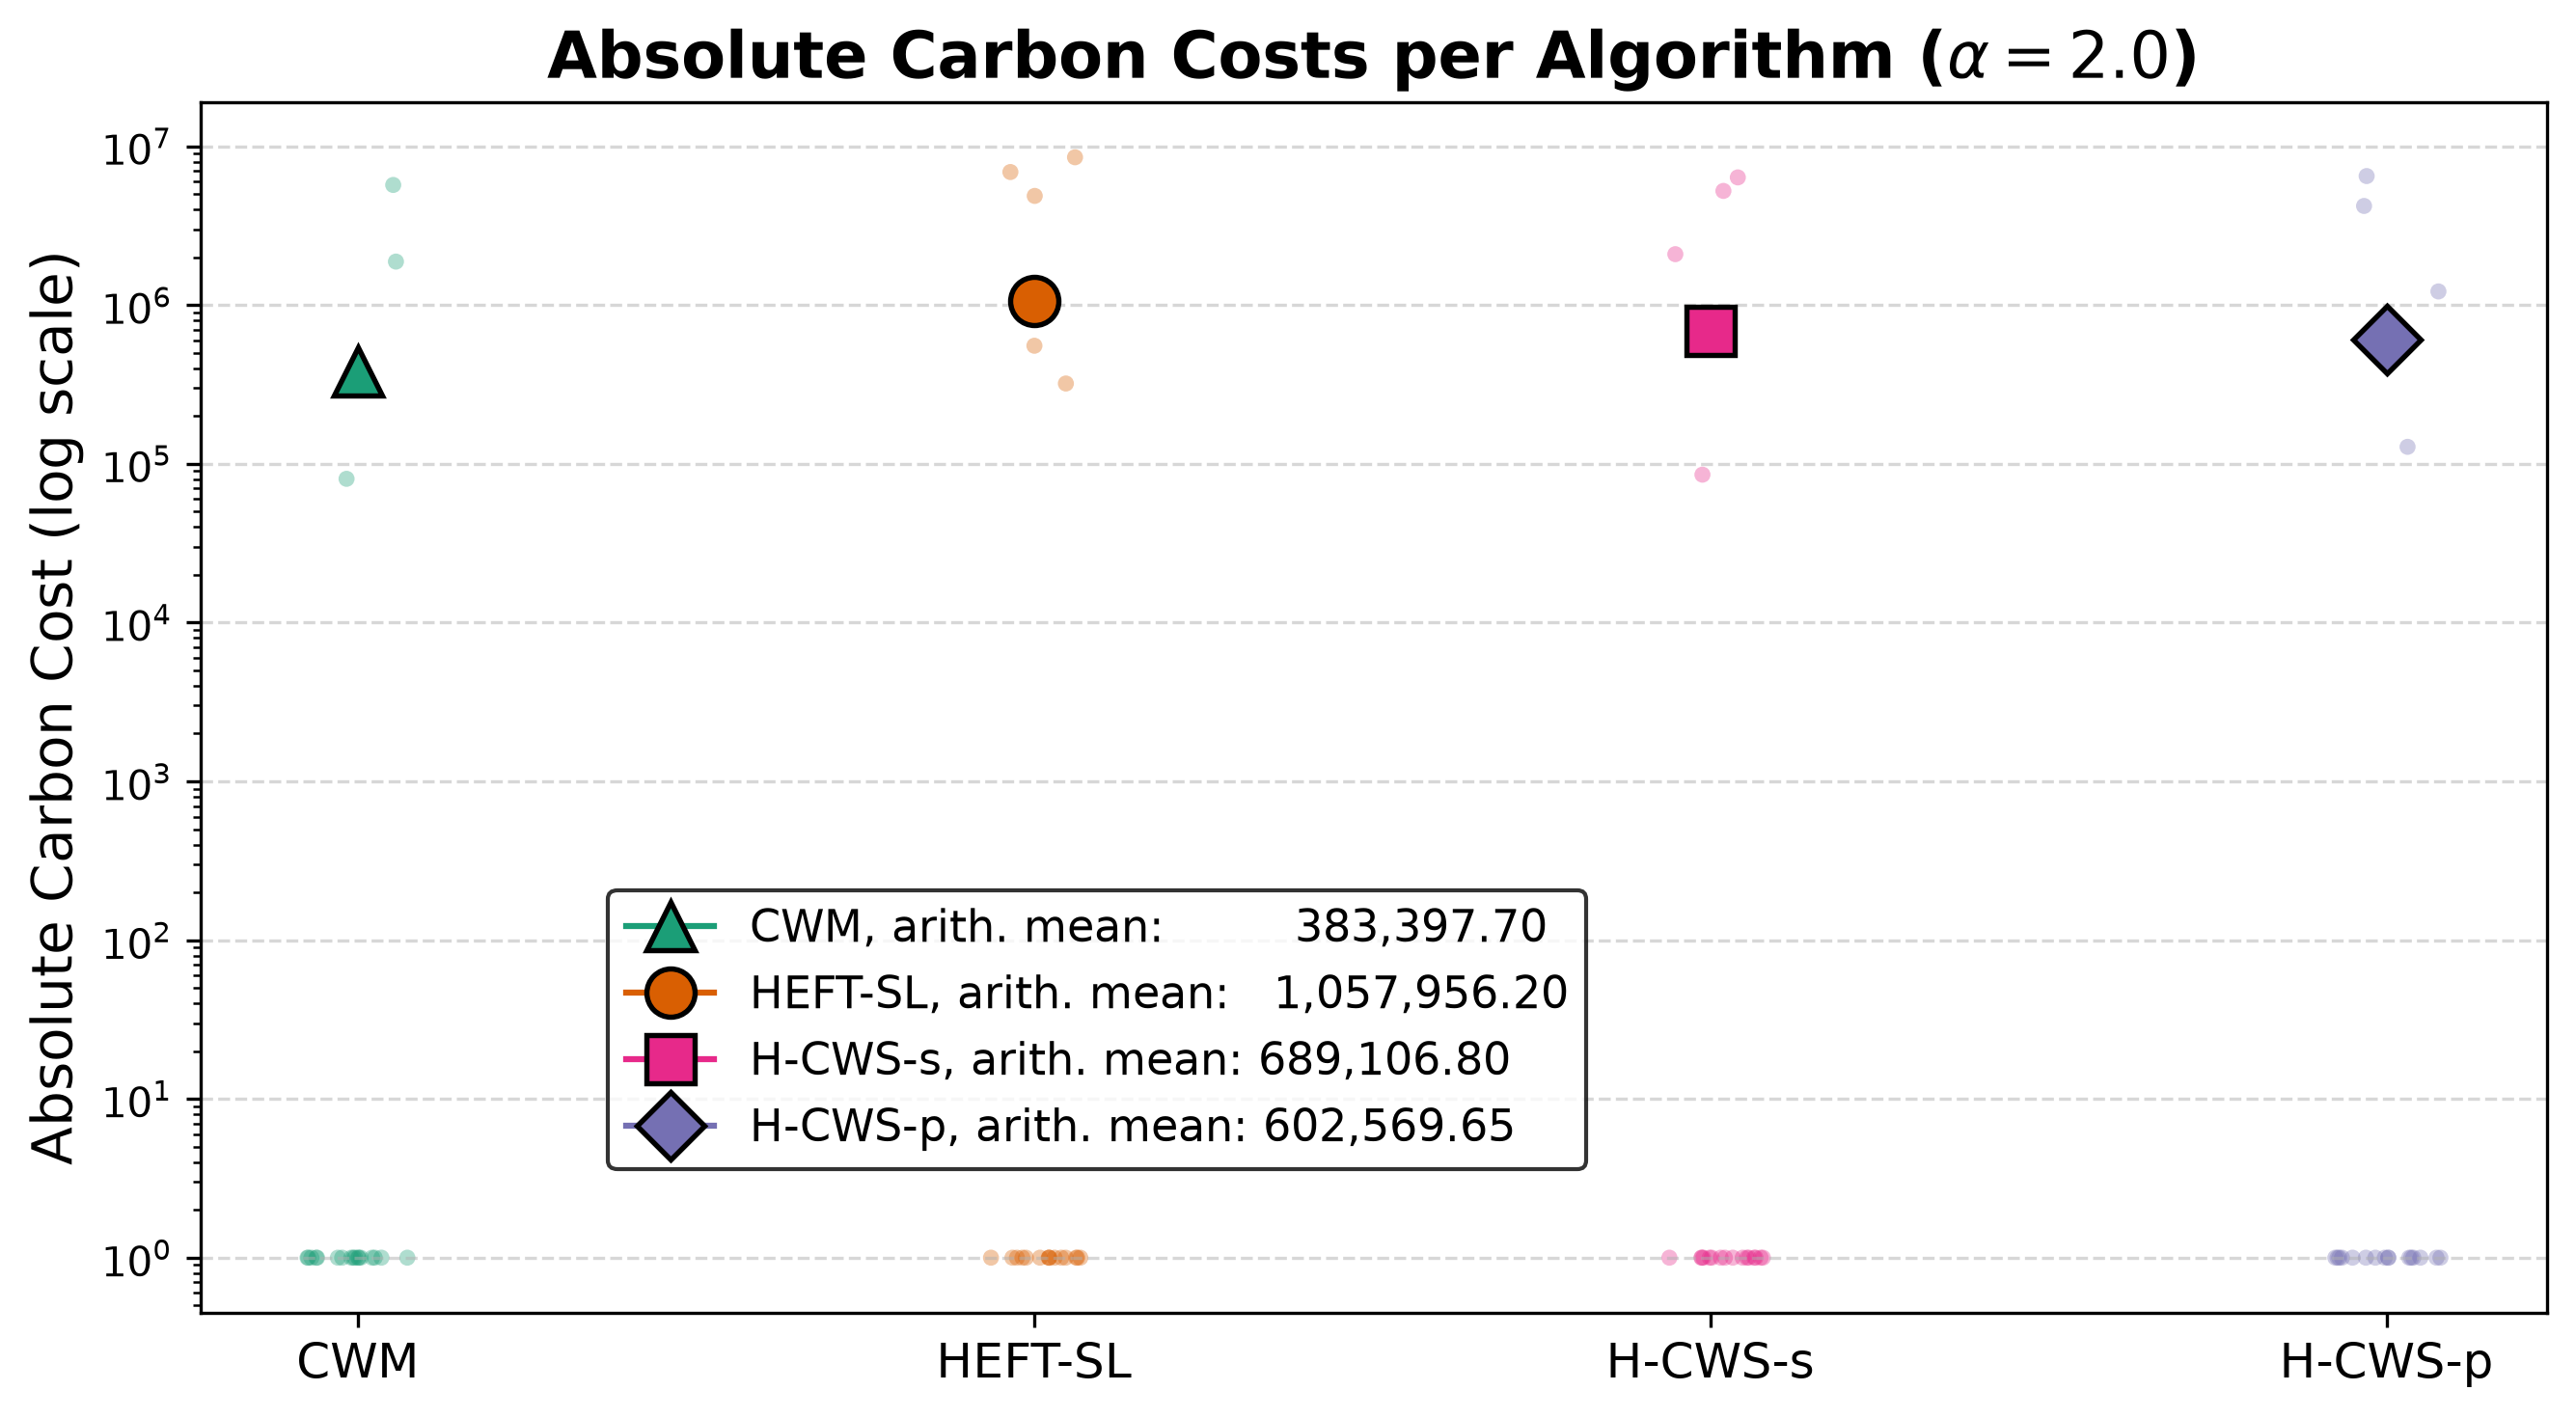

In [21]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------
# 1. Extract absolute costs for each algorithm
# ----------------------------------------------------
abs_costs = {
    "CWM":      combined_df_20["cost_cwm"],
    "HEFT-SL":     combined_df_20["cost_heft"],
    "H-CWS-s":    combined_df_20["cost_slack"],
    "H-CWS-p": combined_df_20["cost_pressure"],
}

# Clean invalid entries
for k in abs_costs:
    abs_costs[k] = pd.to_numeric(abs_costs[k], errors="coerce")
    abs_costs[k] = abs_costs[k].replace([np.inf, -np.inf], np.nan).dropna()

# ----------------------------------------------------
# 2. Compute geometric means
# ----------------------------------------------------
geo_means_abs = {k: np.exp(np.mean(np.log(v))) for k, v in abs_costs.items()}
arith_means_abs = {k: np.mean(v) for k, v in abs_costs.items()}

algos_abs = list(abs_costs.keys())
colors = ["#1b9e77", "#d95f02", "#e7298a", "#7570b3"]   # same palette as before
markers = ["^", "o", "s", "D"]
x_positions = np.arange(len(algos_abs))

# ----------------------------------------------------
# 3. Plot absolute cost distributions
# ----------------------------------------------------
plt.figure(figsize=(9, 5), dpi=300)

for i, alg in enumerate(algos_abs):
    values = abs_costs[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(values))

    # point cloud
    plt.scatter(
        np.full_like(values, x_positions[i]) + jitter,
        values,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "CWM":
      label_text = f"{alg}, arith. mean: {arith_means_abs[alg]:18,.2f}"
    else:
      if alg == "HEFT-SL":
        label_text = f"{alg}, arith. mean: {arith_means_abs[alg]:14,.2f}"
      else:
        label_text = f"{alg}, arith. mean: {arith_means_abs[alg]:,.2f}"
    # arithmetic mean marker
    plt.plot(
        x_positions[i],
        arith_means_abs[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

plt.yscale("log")
plt.xticks(x_positions, algos_abs, fontsize=12)

plt.ylabel("Absolute Carbon Cost (log scale)", fontsize=14)
plt.title(r"Absolute Carbon Costs per Algorithm ($\alpha=2.0$)", fontsize=16, weight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(fontsize=11, frameon=True, edgecolor="black", loc="lower right", bbox_to_anchor=(0.6, 0.1))

plt.tight_layout()
plt.savefig("plots/shifted/absolute_cost_20.png", bbox_inches='tight')
plt.show()

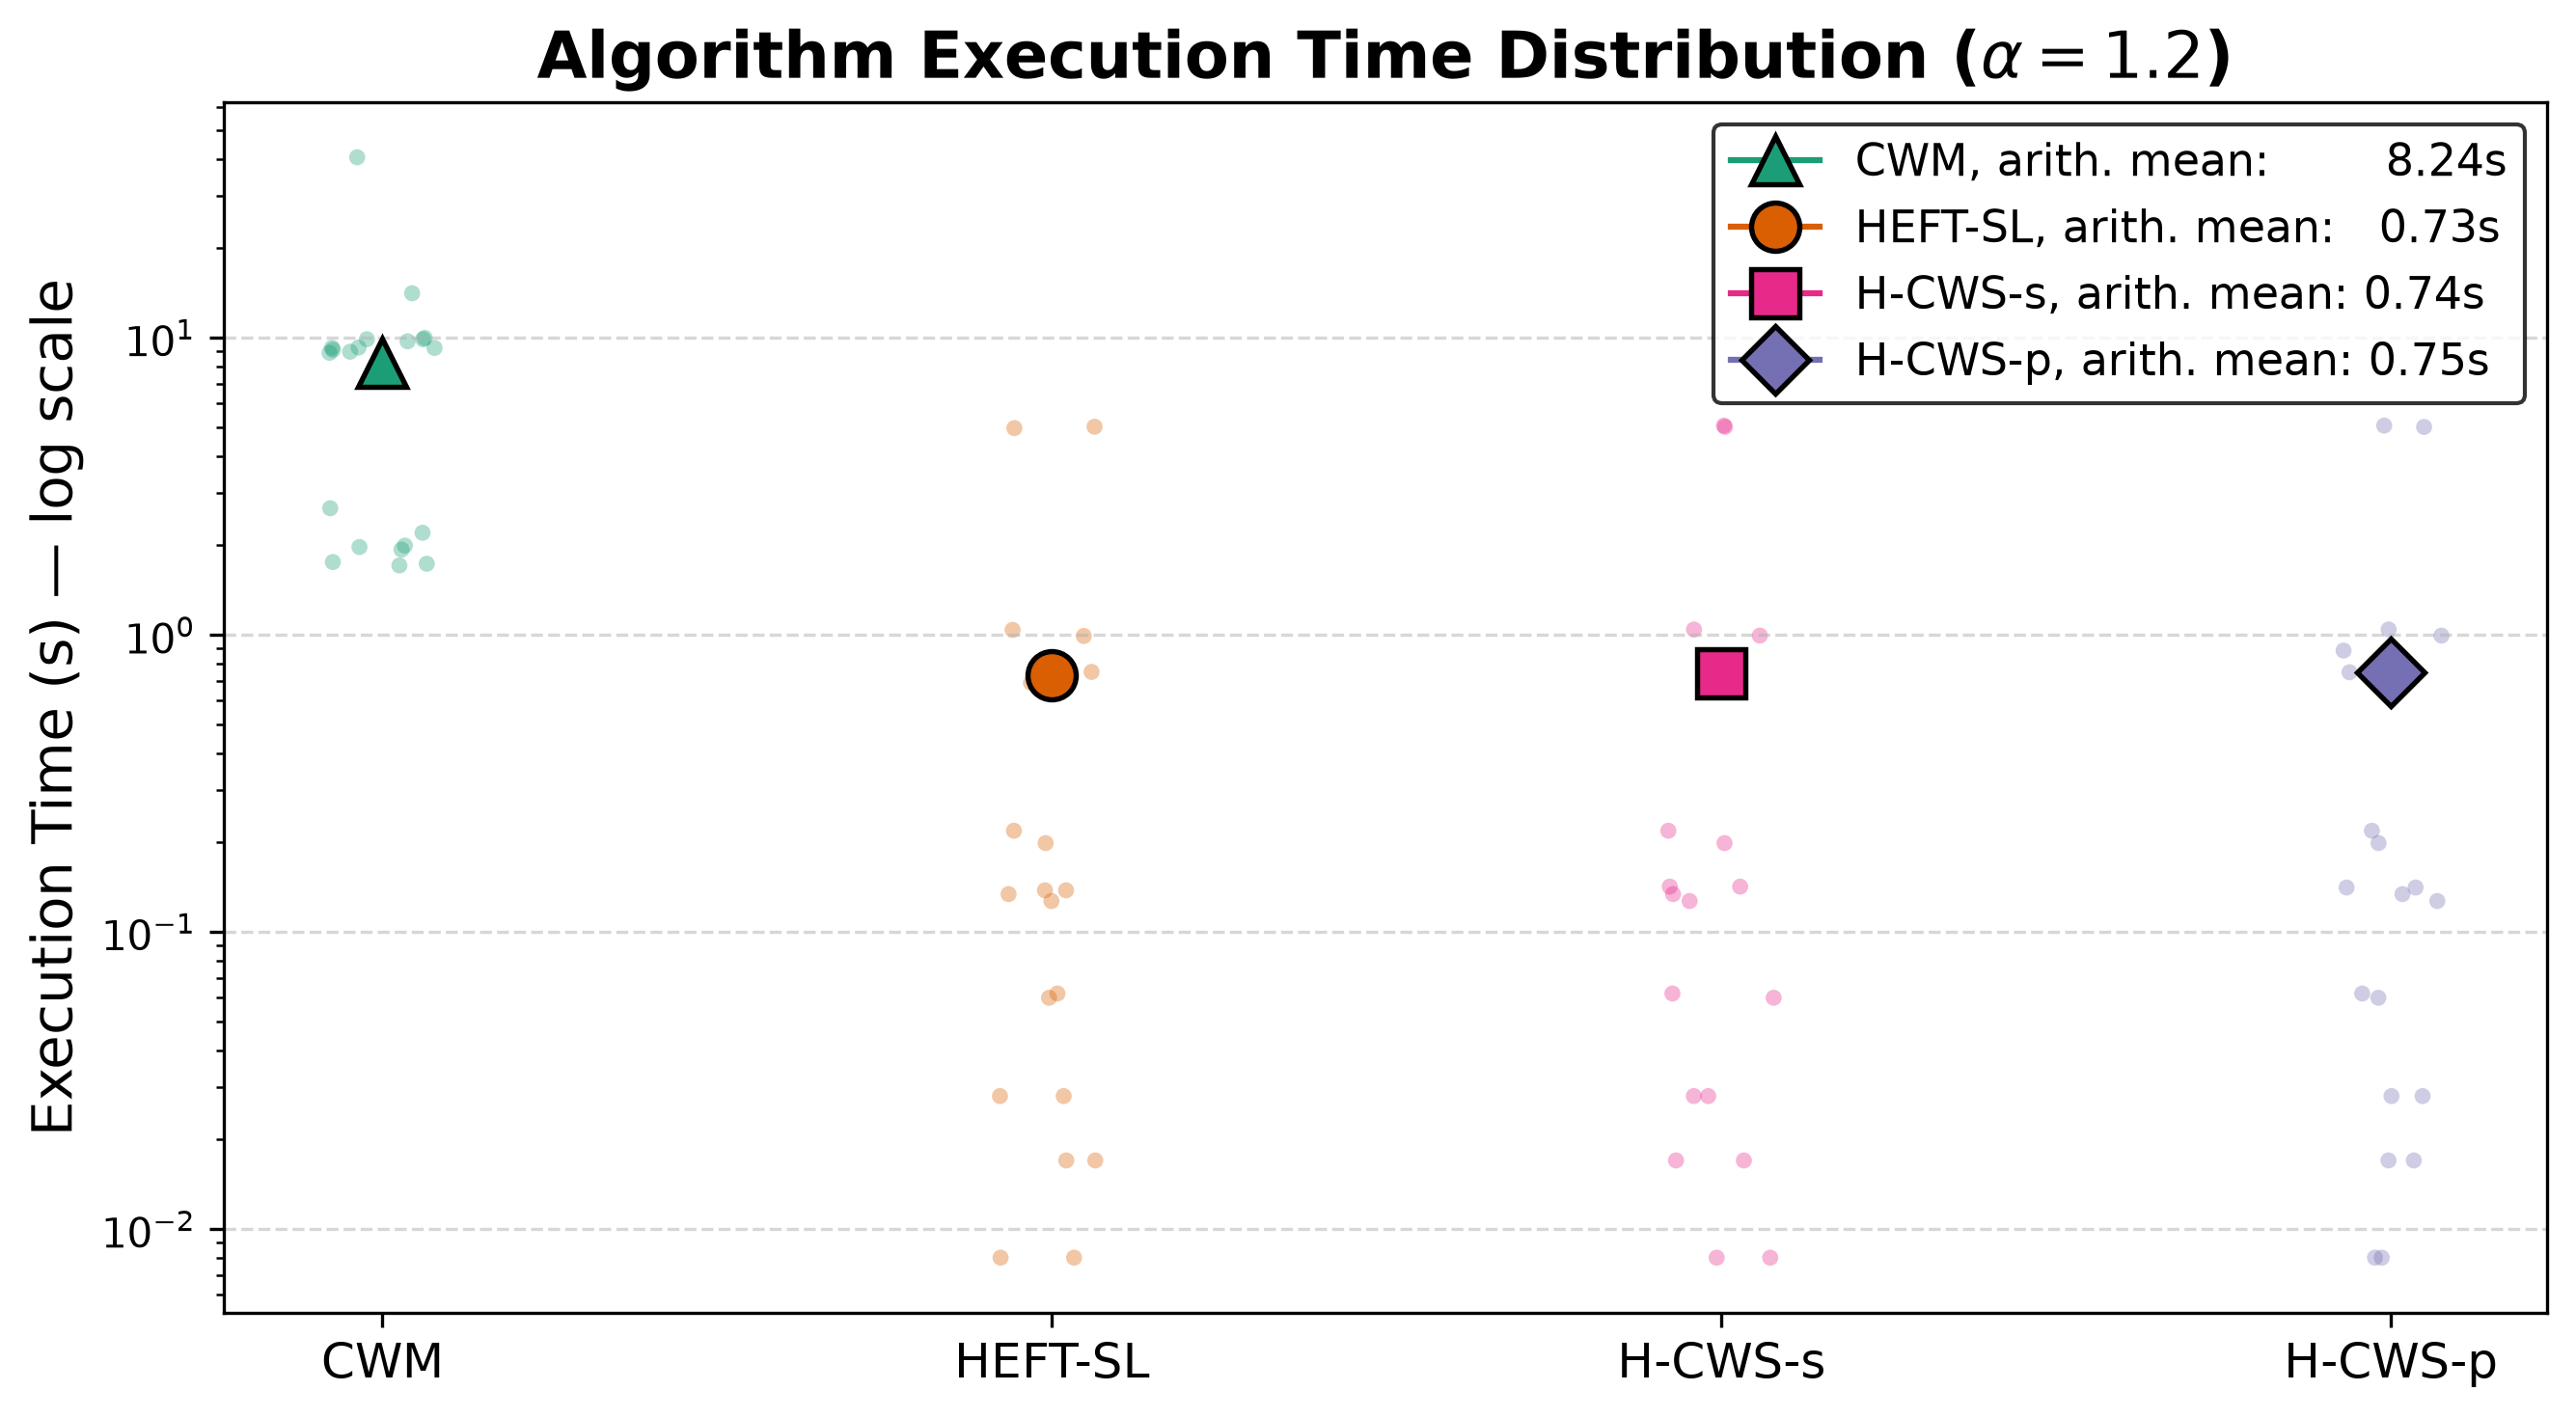

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------
# 1. Collect runtimes
# ----------------------------------------------------
runtime_dict = {
    "CWM":      combined_df_12["time_cwm"],
    "HEFT-SL":  combined_df_12["time_heft"],
    "H-CWS-s":    combined_df_12["time_slack"],
    "H-CWS-p": combined_df_12["time_pressure"]
}

# Clean invalid values
for k in runtime_dict:
    runtime_dict[k] = pd.to_numeric(runtime_dict[k], errors="coerce")
    runtime_dict[k] = runtime_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# ----------------------------------------------------
# 2. Compute geometric mean runtime per algorithm
# ----------------------------------------------------
geo_means_runtime = {k: np.exp(np.mean(np.log(v))) for k, v in runtime_dict.items()}
arith_means_runtime = {k: np.mean(v) for k, v in runtime_dict.items()}

algos = list(runtime_dict.keys())
colors = ["#1b9e77", "#d95f02", "#e7298a", "#7570b3"]
markers = ["^", "o", "s", "D"]
x_positions = np.arange(len(algos))

# ----------------------------------------------------
# 3. Plot (Time Point Clouds + Geometric Means)
# ----------------------------------------------------
plt.figure(figsize=(9, 5), dpi=300)

for i, alg in enumerate(algos):
    times = runtime_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(times))

    # point cloud
    plt.scatter(
        np.full_like(times, x_positions[i]) + jitter,
        times,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "CWM":
      label_text = f"{alg}, arith. mean: {arith_means_runtime[alg]:11,.2f}s"
    else:
      if alg == "HEFT-SL":
        label_text = f"{alg}, arith. mean: {arith_means_runtime[alg]:6,.2f}s"
      else:
        label_text = f"{alg}, arith. mean: {arith_means_runtime[alg]:,.2f}s"
    # arithmetic mean
    plt.plot(
        x_positions[i],
        arith_means_runtime[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor='black',
        color=colors[i],
        label=label_text
    )

plt.yscale("log")
plt.xticks(x_positions, algos, fontsize=12)

plt.ylabel("Execution Time (s) — log scale", fontsize=14)
plt.title(r"Algorithm Execution Time Distribution ($\alpha=1.2$)", fontsize=16, weight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(fontsize=11, frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/abs_execution_time_12.png", bbox_inches='tight')
plt.show()

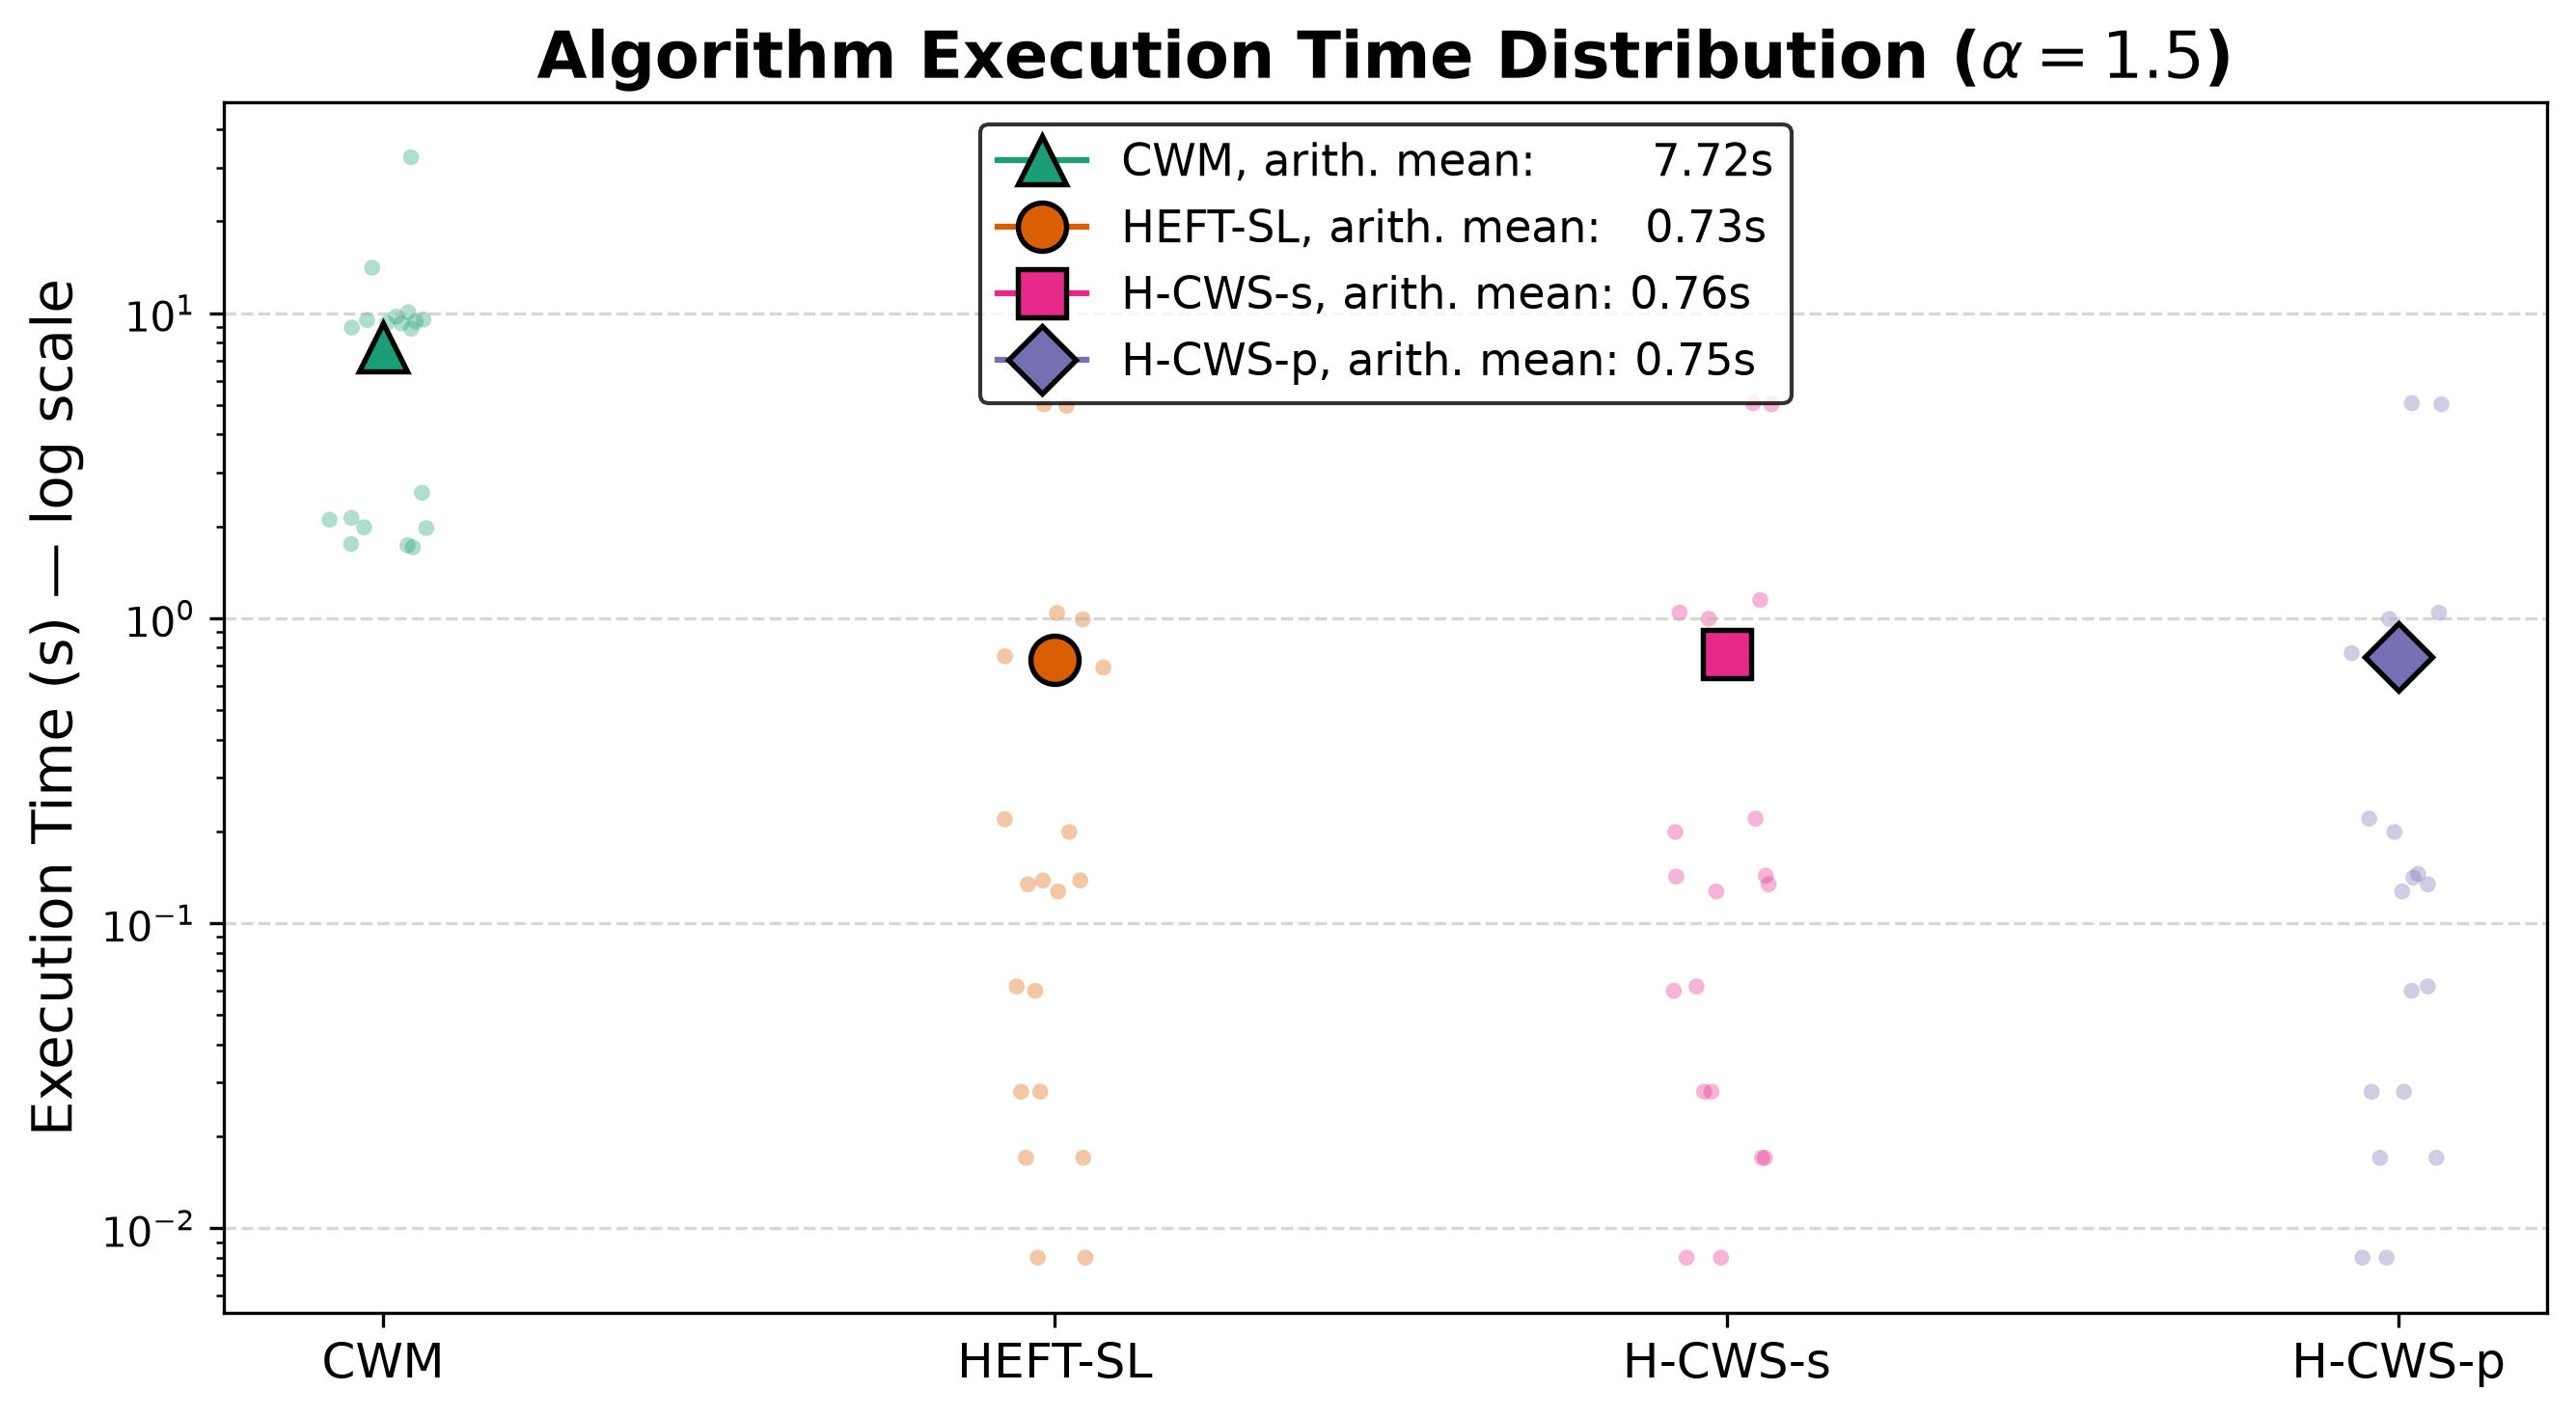

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------
# 1. Collect runtimes
# ----------------------------------------------------
runtime_dict = {
    "CWM":      combined_df_15["time_cwm"],
    "HEFT-SL":  combined_df_15["time_heft"],
    "H-CWS-s":    combined_df_15["time_slack"],
    "H-CWS-p": combined_df_15["time_pressure"]
}

# Clean invalid values
for k in runtime_dict:
    runtime_dict[k] = pd.to_numeric(runtime_dict[k], errors="coerce")
    runtime_dict[k] = runtime_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# ----------------------------------------------------
# 2. Compute geometric mean runtime per algorithm
# ----------------------------------------------------
geo_means_runtime = {k: np.exp(np.mean(np.log(v))) for k, v in runtime_dict.items()}
arith_means_runtime = {k: np.mean(v) for k, v in runtime_dict.items()}

algos = list(runtime_dict.keys())
colors = ["#1b9e77", "#d95f02", "#e7298a", "#7570b3"]
markers = ["^", "o", "s", "D"]
x_positions = np.arange(len(algos))

# ----------------------------------------------------
# 3. Plot (Time Point Clouds + Geometric Means)
# ----------------------------------------------------
plt.figure(figsize=(9, 5), dpi=300)

for i, alg in enumerate(algos):
    times = runtime_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(times))

    # point cloud
    plt.scatter(
        np.full_like(times, x_positions[i]) + jitter,
        times,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "CWM":
      label_text = f"{alg}, arith. mean: {arith_means_runtime[alg]:11,.2f}s"
    else:
      if alg == "HEFT-SL":
        label_text = f"{alg}, arith. mean: {arith_means_runtime[alg]:6,.2f}s"
      else:
        label_text = f"{alg}, arith. mean: {arith_means_runtime[alg]:,.2f}s"
    # arithmetic mean
    plt.plot(
        x_positions[i],
        arith_means_runtime[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor='black',
        color=colors[i],
        label=label_text
    )

plt.yscale("log")
plt.xticks(x_positions, algos, fontsize=12)

plt.ylabel("Execution Time (s) — log scale", fontsize=14)
plt.title(r"Algorithm Execution Time Distribution ($\alpha=1.5$)", fontsize=16, weight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(fontsize=11, frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/abs_execution_time_15.png", bbox_inches='tight')
plt.show()

20


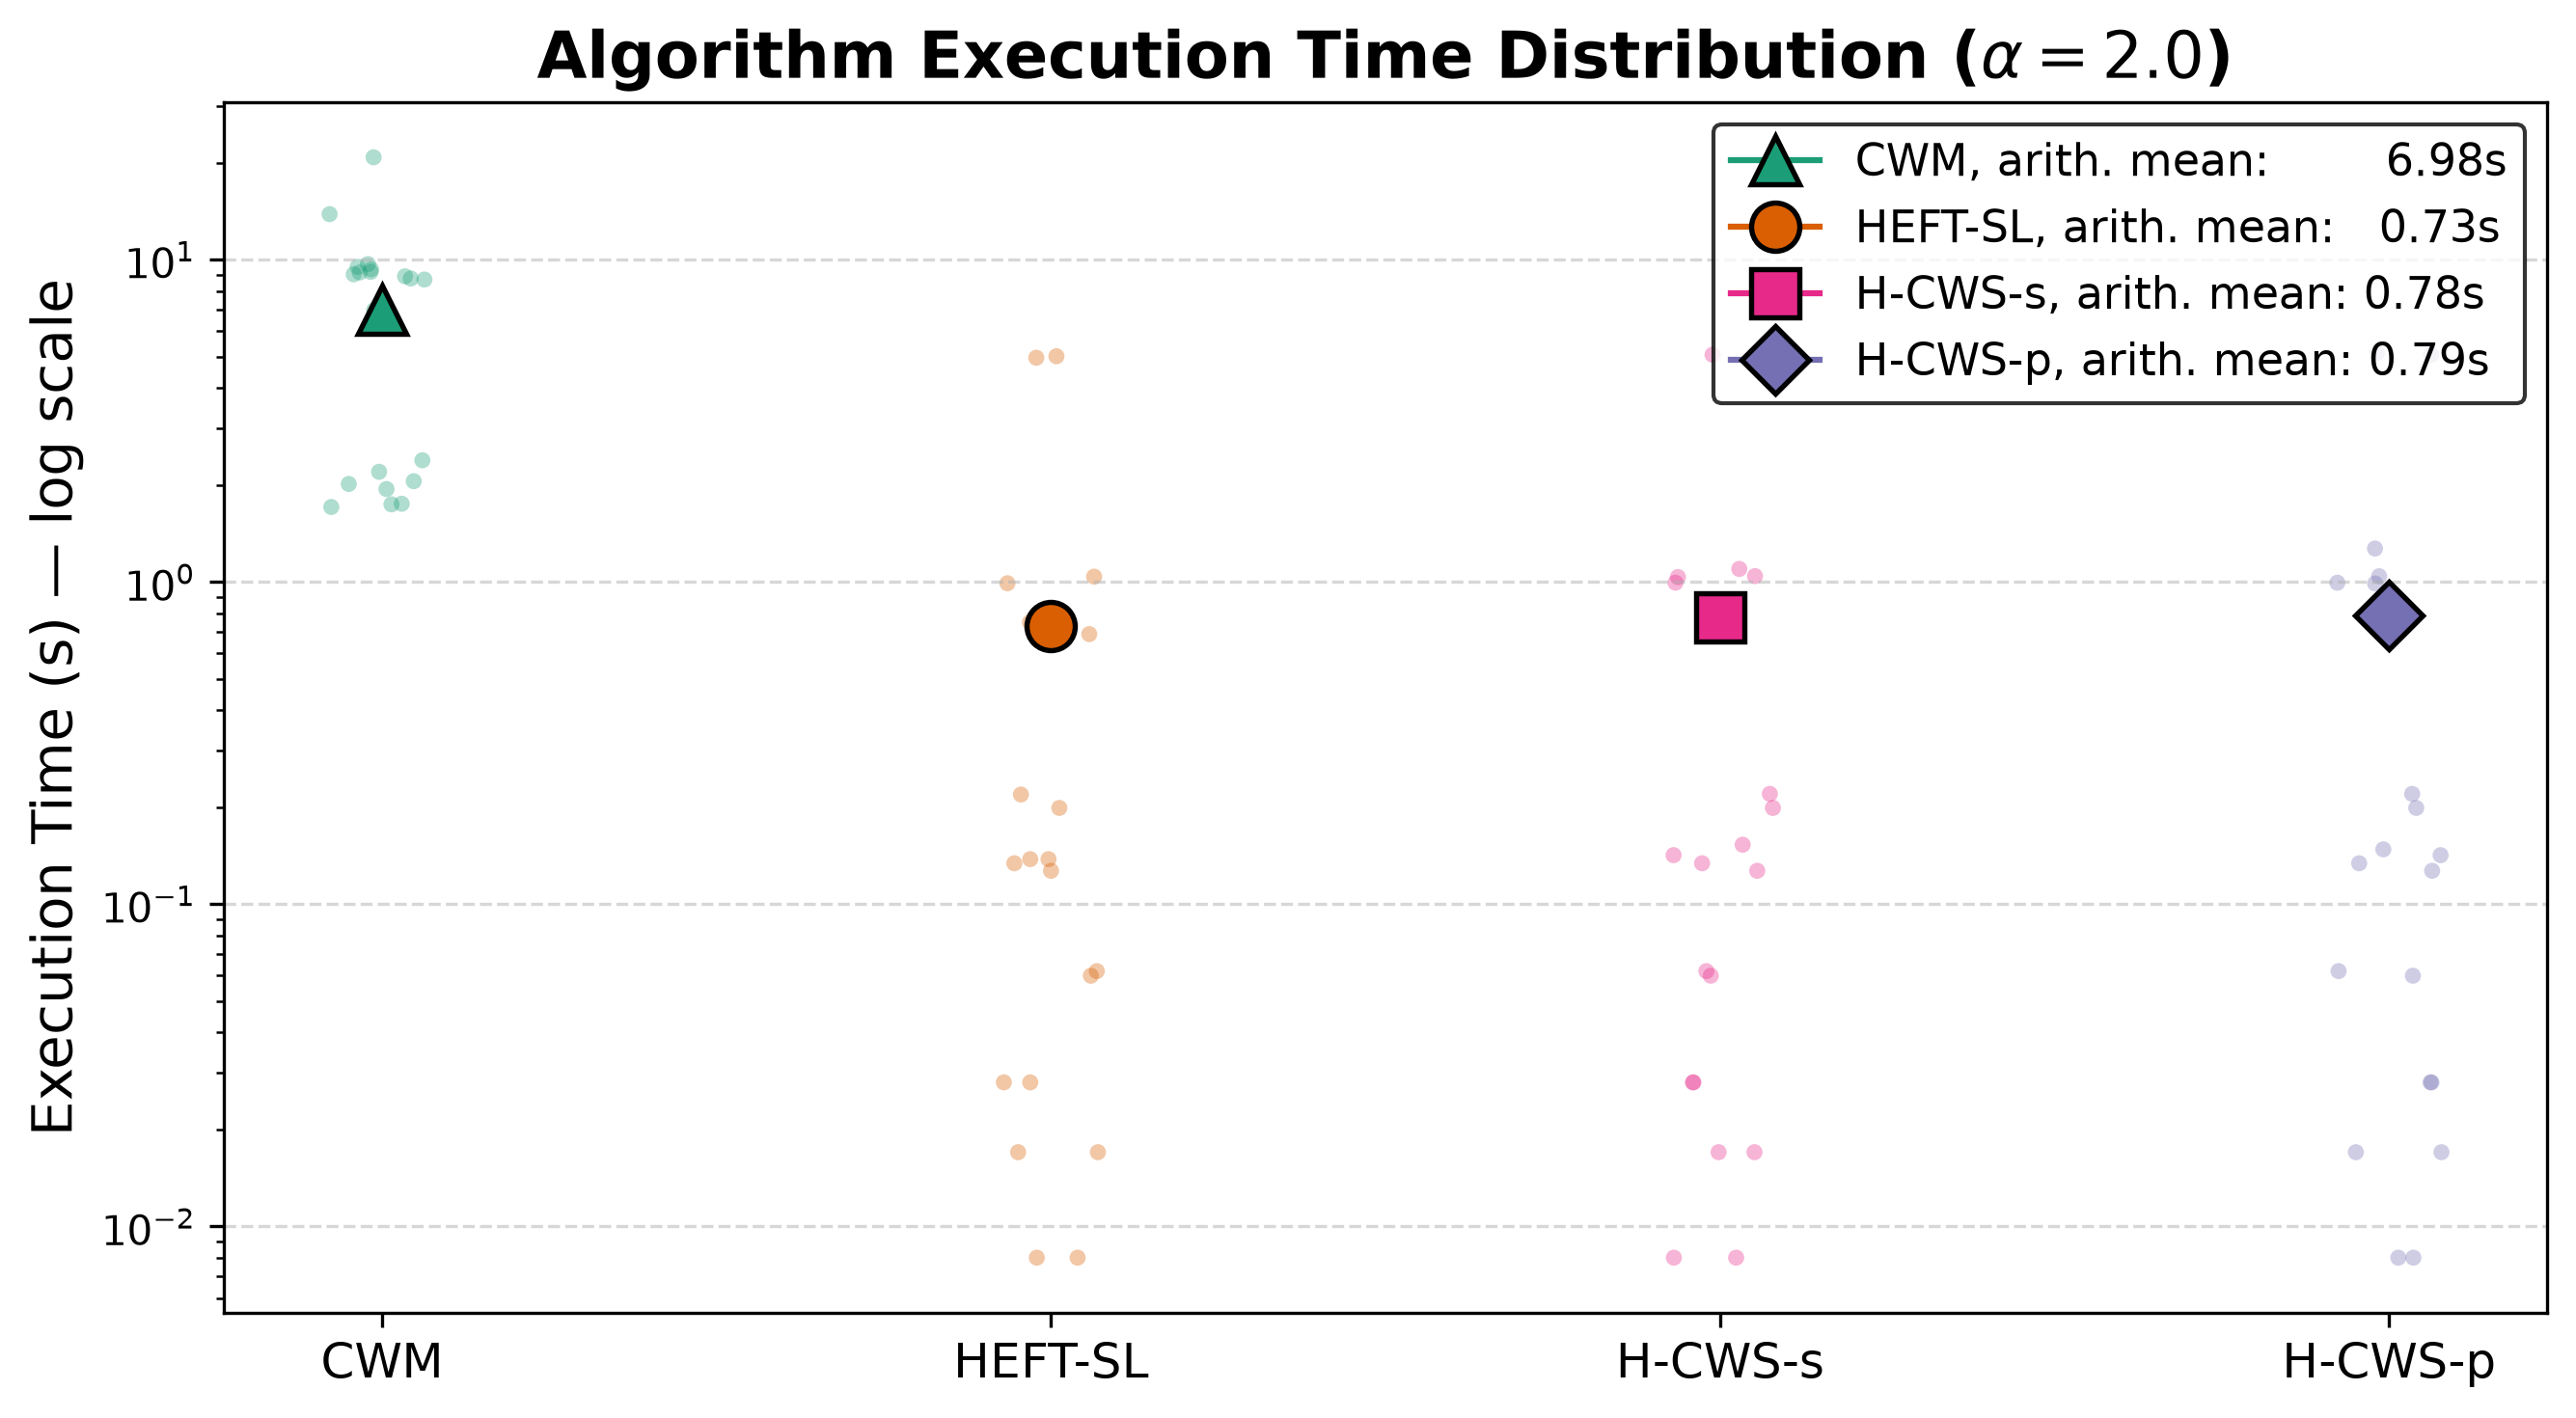

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------------------------
# 1. Collect runtimes
# ----------------------------------------------------
runtime_dict = {
    "CWM":      combined_df_20["time_cwm"],
    "HEFT-SL":  combined_df_20["time_heft"],
    "H-CWS-s":    combined_df_20["time_slack"],
    "H-CWS-p": combined_df_20["time_pressure"]
}

print(len(combined_df_20))

# Clean invalid values
for k in runtime_dict:
    runtime_dict[k] = pd.to_numeric(runtime_dict[k], errors="coerce")
    runtime_dict[k] = runtime_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# ----------------------------------------------------
# 2. Compute geometric mean runtime per algorithm
# ----------------------------------------------------
geo_means_runtime = {k: np.exp(np.mean(np.log(v))) for k, v in runtime_dict.items()}
arith_means_runtime = {k: np.mean(v) for k, v in runtime_dict.items()}

algos = list(runtime_dict.keys())
colors = ["#1b9e77", "#d95f02", "#e7298a", "#7570b3"]
markers = ["^", "o", "s", "D"]
x_positions = np.arange(len(algos))

# ----------------------------------------------------
# 3. Plot (Time Point Clouds + Geometric Means)
# ----------------------------------------------------
plt.figure(figsize=(9, 5), dpi=300)

for i, alg in enumerate(algos):
    times = runtime_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(times))

    # point cloud
    plt.scatter(
        np.full_like(times, x_positions[i]) + jitter,
        times,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )

    if alg == "CWM":
      label_text = f"{alg}, arith. mean: {arith_means_runtime[alg]:11,.2f}s"
    else:
      if alg == "HEFT-SL":
        label_text = f"{alg}, arith. mean: {arith_means_runtime[alg]:6,.2f}s"
      else:
        label_text = f"{alg}, arith. mean: {arith_means_runtime[alg]:,.2f}s"
    # arithmetic mean
    plt.plot(
        x_positions[i],
        arith_means_runtime[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor='black',
        color=colors[i],
        label=label_text
    )

plt.yscale("log")
plt.xticks(x_positions, algos, fontsize=12)

plt.ylabel("Execution Time (s) — log scale", fontsize=14)
plt.title(r"Algorithm Execution Time Distribution ($\alpha=2.0$)", fontsize=16, weight="bold")

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(fontsize=11, frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/abs_execution_time_20.png", bbox_inches='tight')
plt.show()

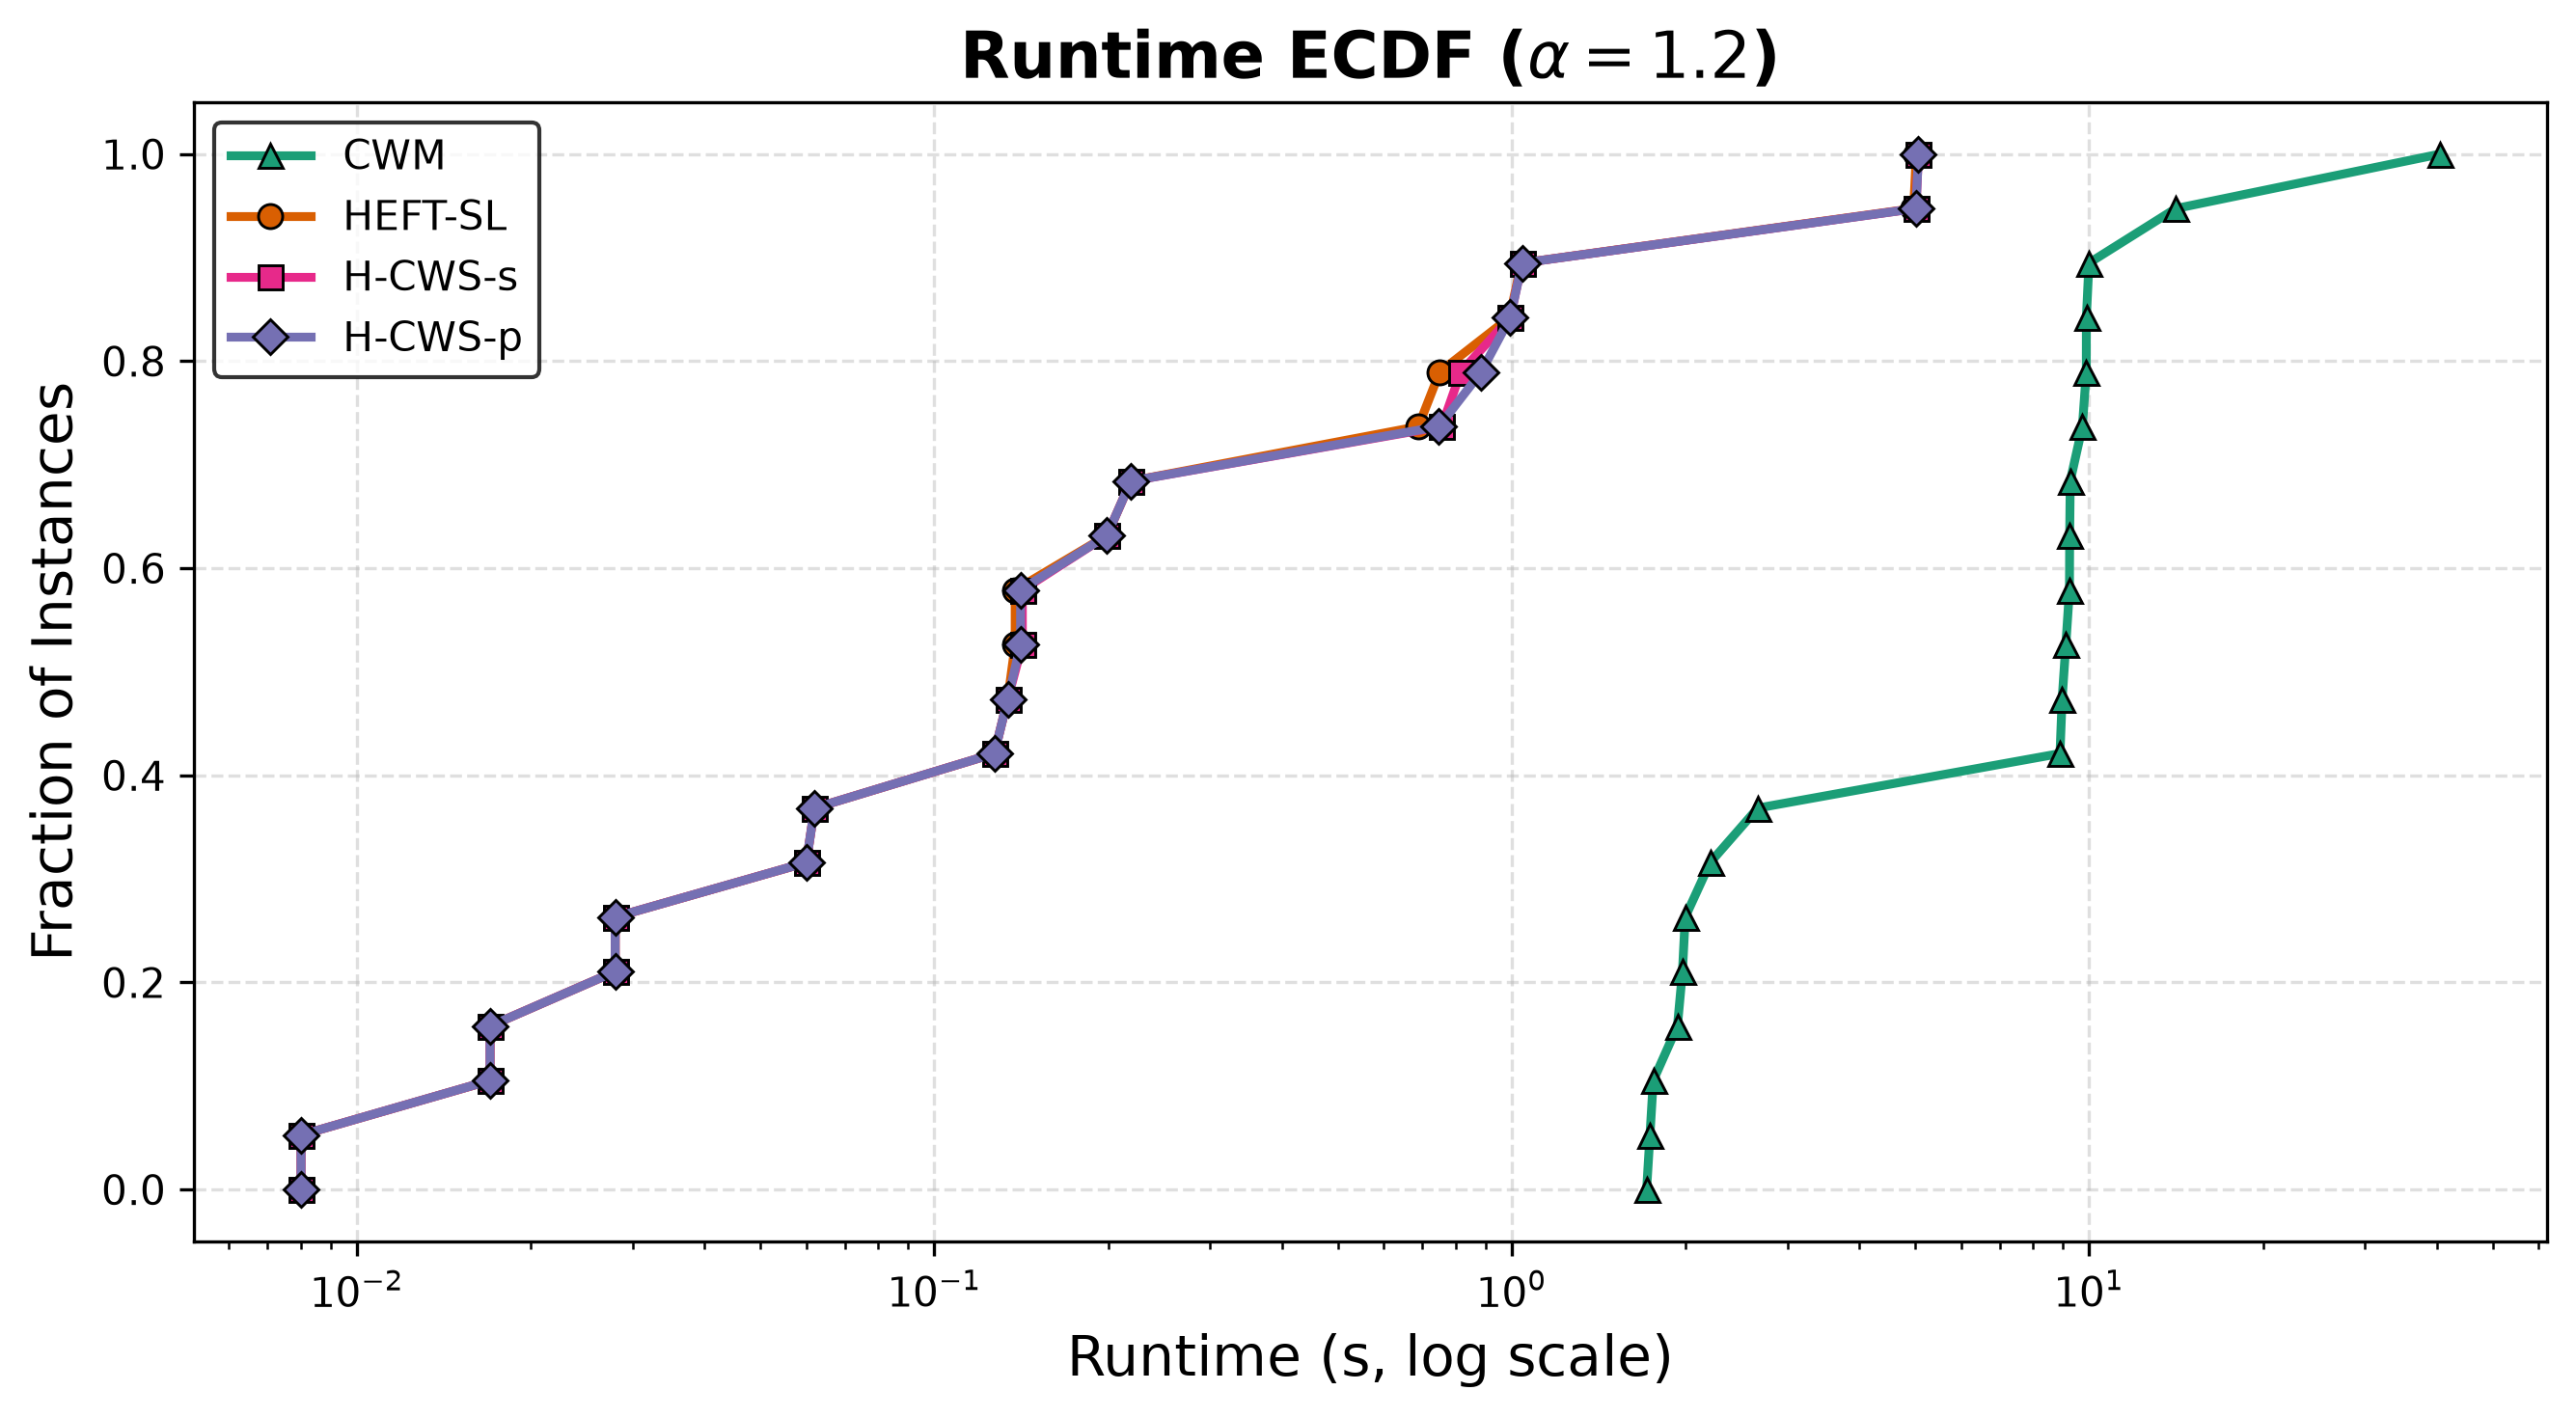

In [25]:
import numpy as np
import matplotlib.pyplot as plt

algos = {
    "CWM":      combined_df_12["time_cwm"],
    "HEFT-SL":  combined_df_12["time_heft"],
    "H-CWS-s":    combined_df_12["time_slack"],
    "H-CWS-p": combined_df_12["time_pressure"]
}

colors = ["#1b9e77", "#d95f02", "#e7298a", "#7570b3"]
markers = ["^", "o", "s", "D"]

plt.figure(figsize=(9,5), dpi=300)

for (name, series), color, marker in zip(algos.items(), colors, markers):

    # Clean
    t = pd.to_numeric(series, errors="coerce").dropna()
    t = np.sort(t)

    y = np.linspace(0, 1, len(t))

    plt.plot(
        t, y,
        label=name,
        color=color,
        marker=marker,
        markevery=max(1, len(t)//40),
        markersize=6,
        linewidth=2.2,
        markeredgecolor="black",
        markeredgewidth=0.7
    )

plt.xscale("log")
plt.xlabel("Runtime (s, log scale)", fontsize=14)
plt.ylabel("Fraction of Instances", fontsize=14)
plt.title(r"Runtime ECDF ($\alpha=1.2$)", fontsize=16, weight="bold")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/ecdf_execution_time_12.png", bbox_inches='tight')
plt.show()

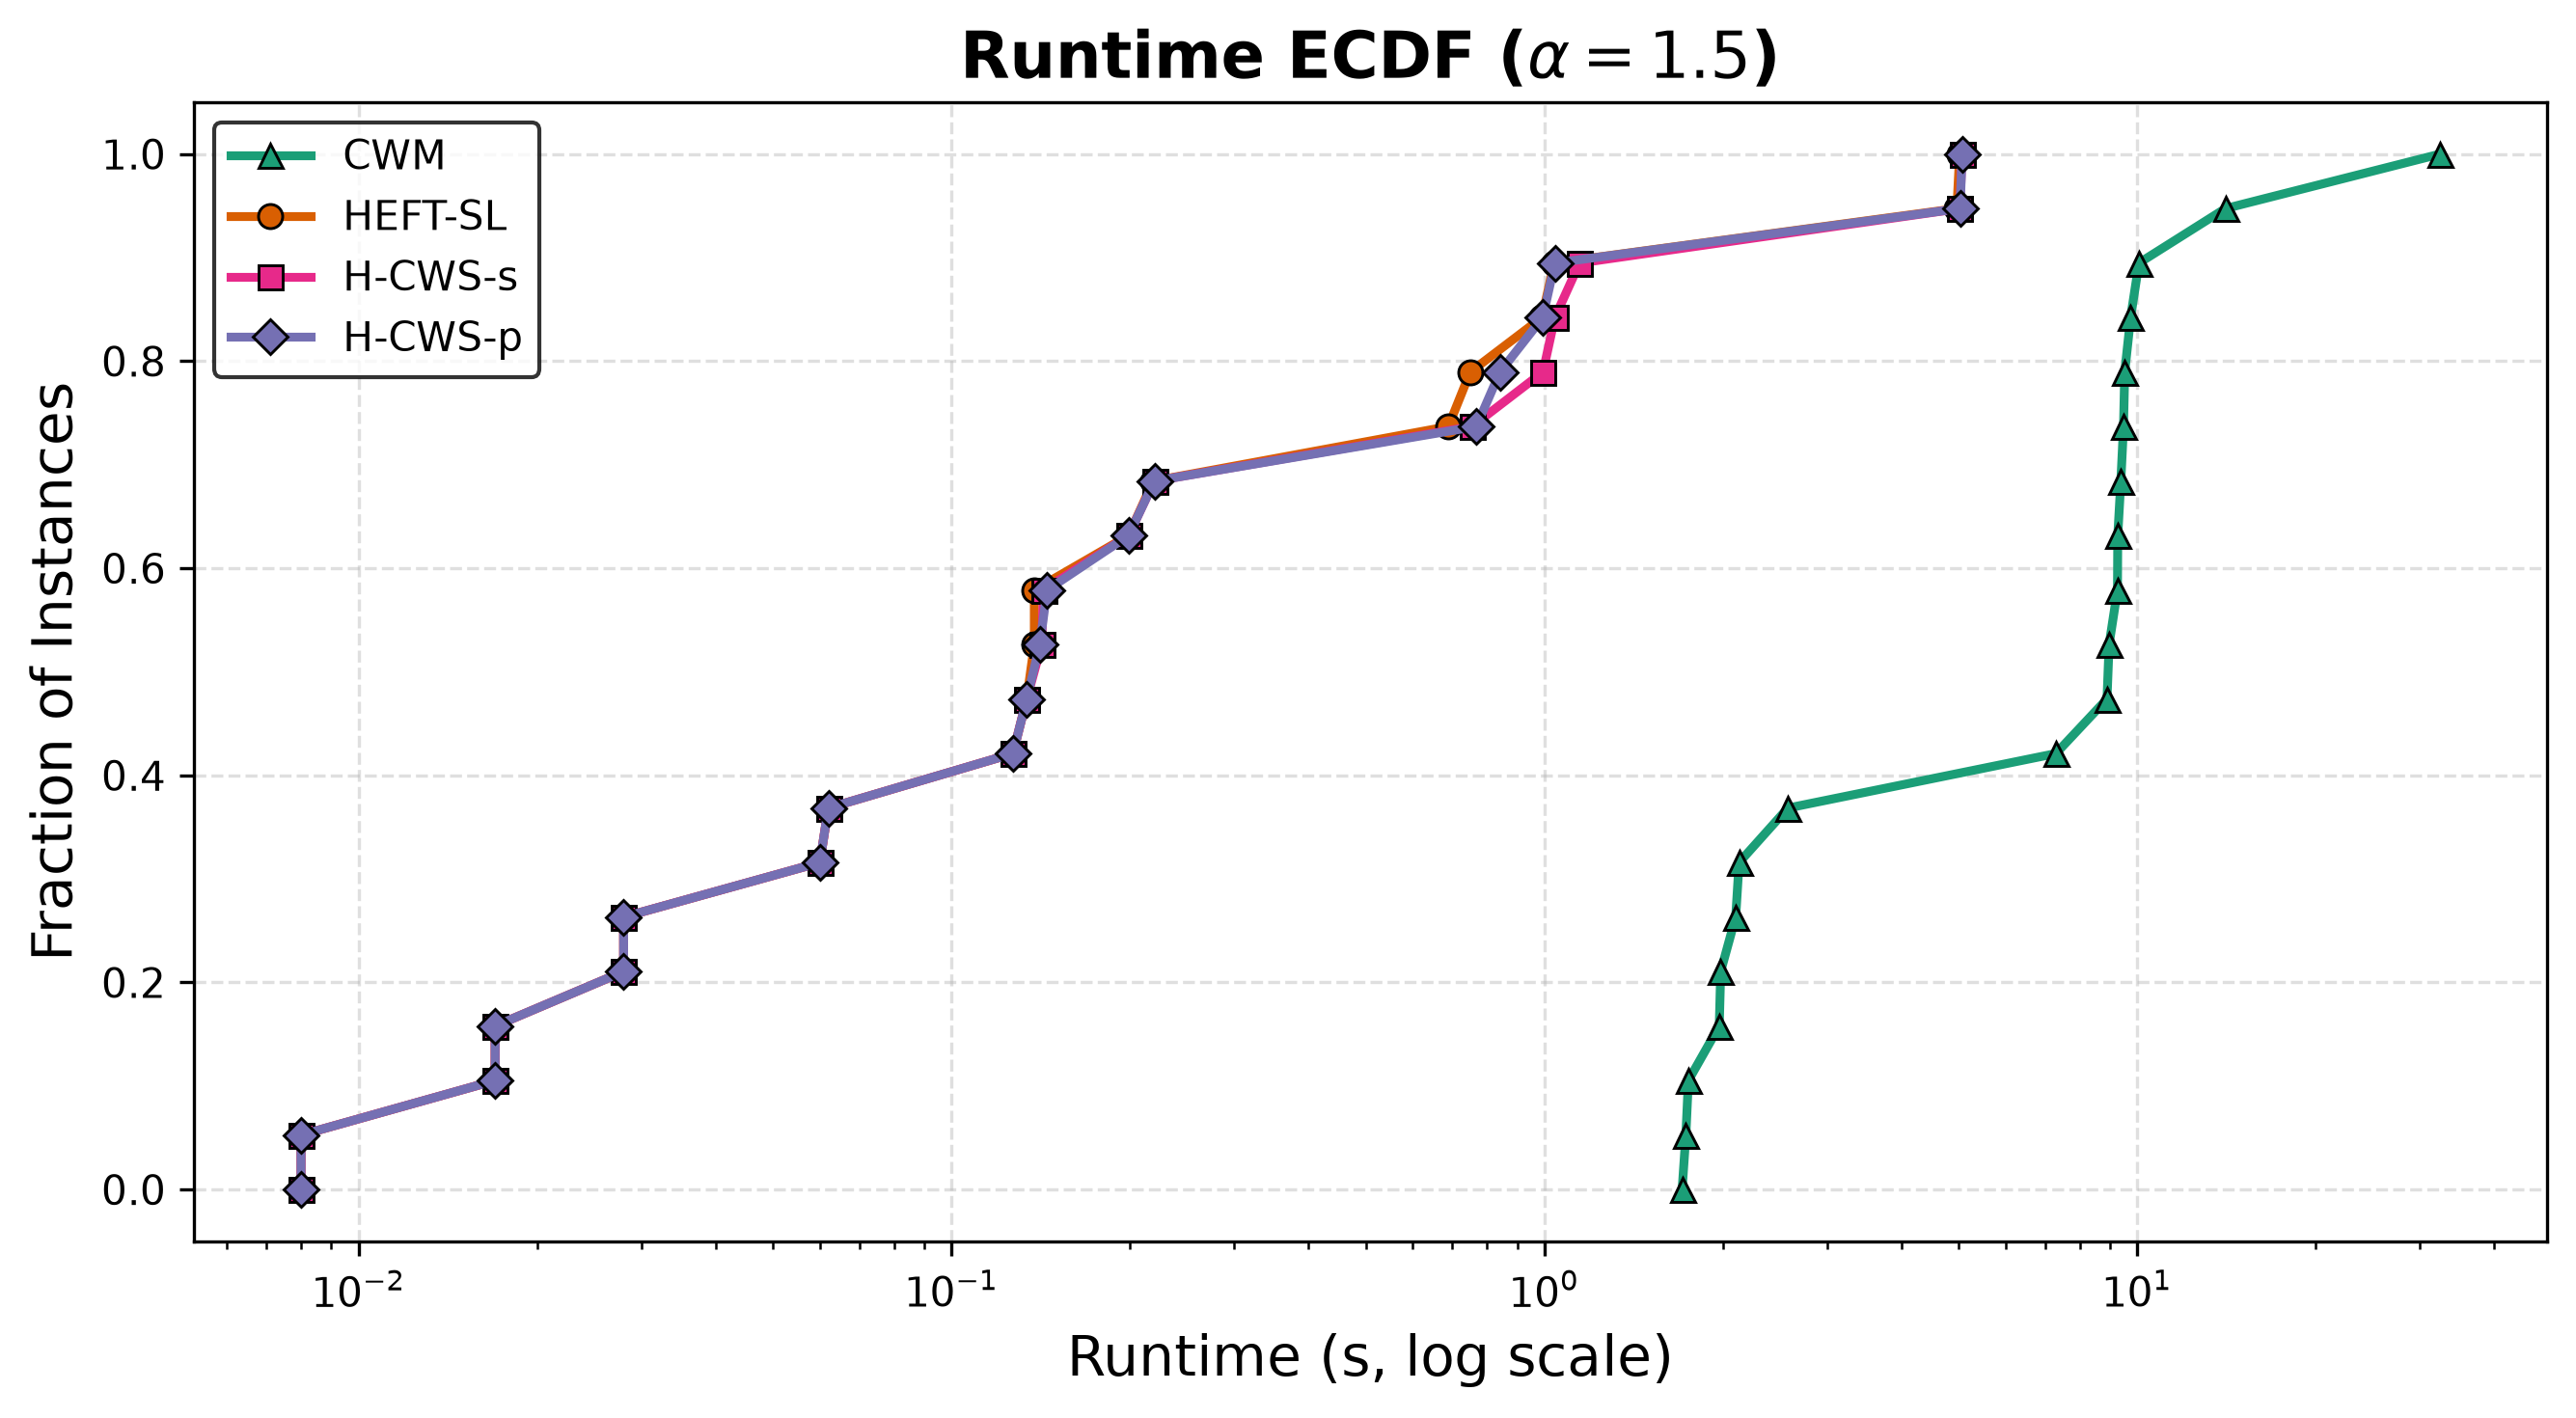

In [26]:
import numpy as np
import matplotlib.pyplot as plt

algos = {
    "CWM":      combined_df_15["time_cwm"],
    "HEFT-SL":  combined_df_15["time_heft"],
    "H-CWS-s":    combined_df_15["time_slack"],
    "H-CWS-p": combined_df_15["time_pressure"]
}

colors = ["#1b9e77", "#d95f02", "#e7298a", "#7570b3"]
markers = ["^", "o", "s", "D"]

plt.figure(figsize=(9,5), dpi=300)

for (name, series), color, marker in zip(algos.items(), colors, markers):

    # Clean
    t = pd.to_numeric(series, errors="coerce").dropna()
    t = np.sort(t)

    y = np.linspace(0, 1, len(t))

    plt.plot(
        t, y,
        label=name,
        color=color,
        marker=marker,
        markevery=max(1, len(t)//40),
        markersize=6,
        linewidth=2.2,
        markeredgecolor="black",
        markeredgewidth=0.7
    )

plt.xscale("log")
plt.xlabel("Runtime (s, log scale)", fontsize=14)
plt.ylabel("Fraction of Instances", fontsize=14)
plt.title(r"Runtime ECDF ($\alpha=1.5$)", fontsize=16, weight="bold")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/ecdf_execution_time_15.png", bbox_inches='tight')
plt.show()

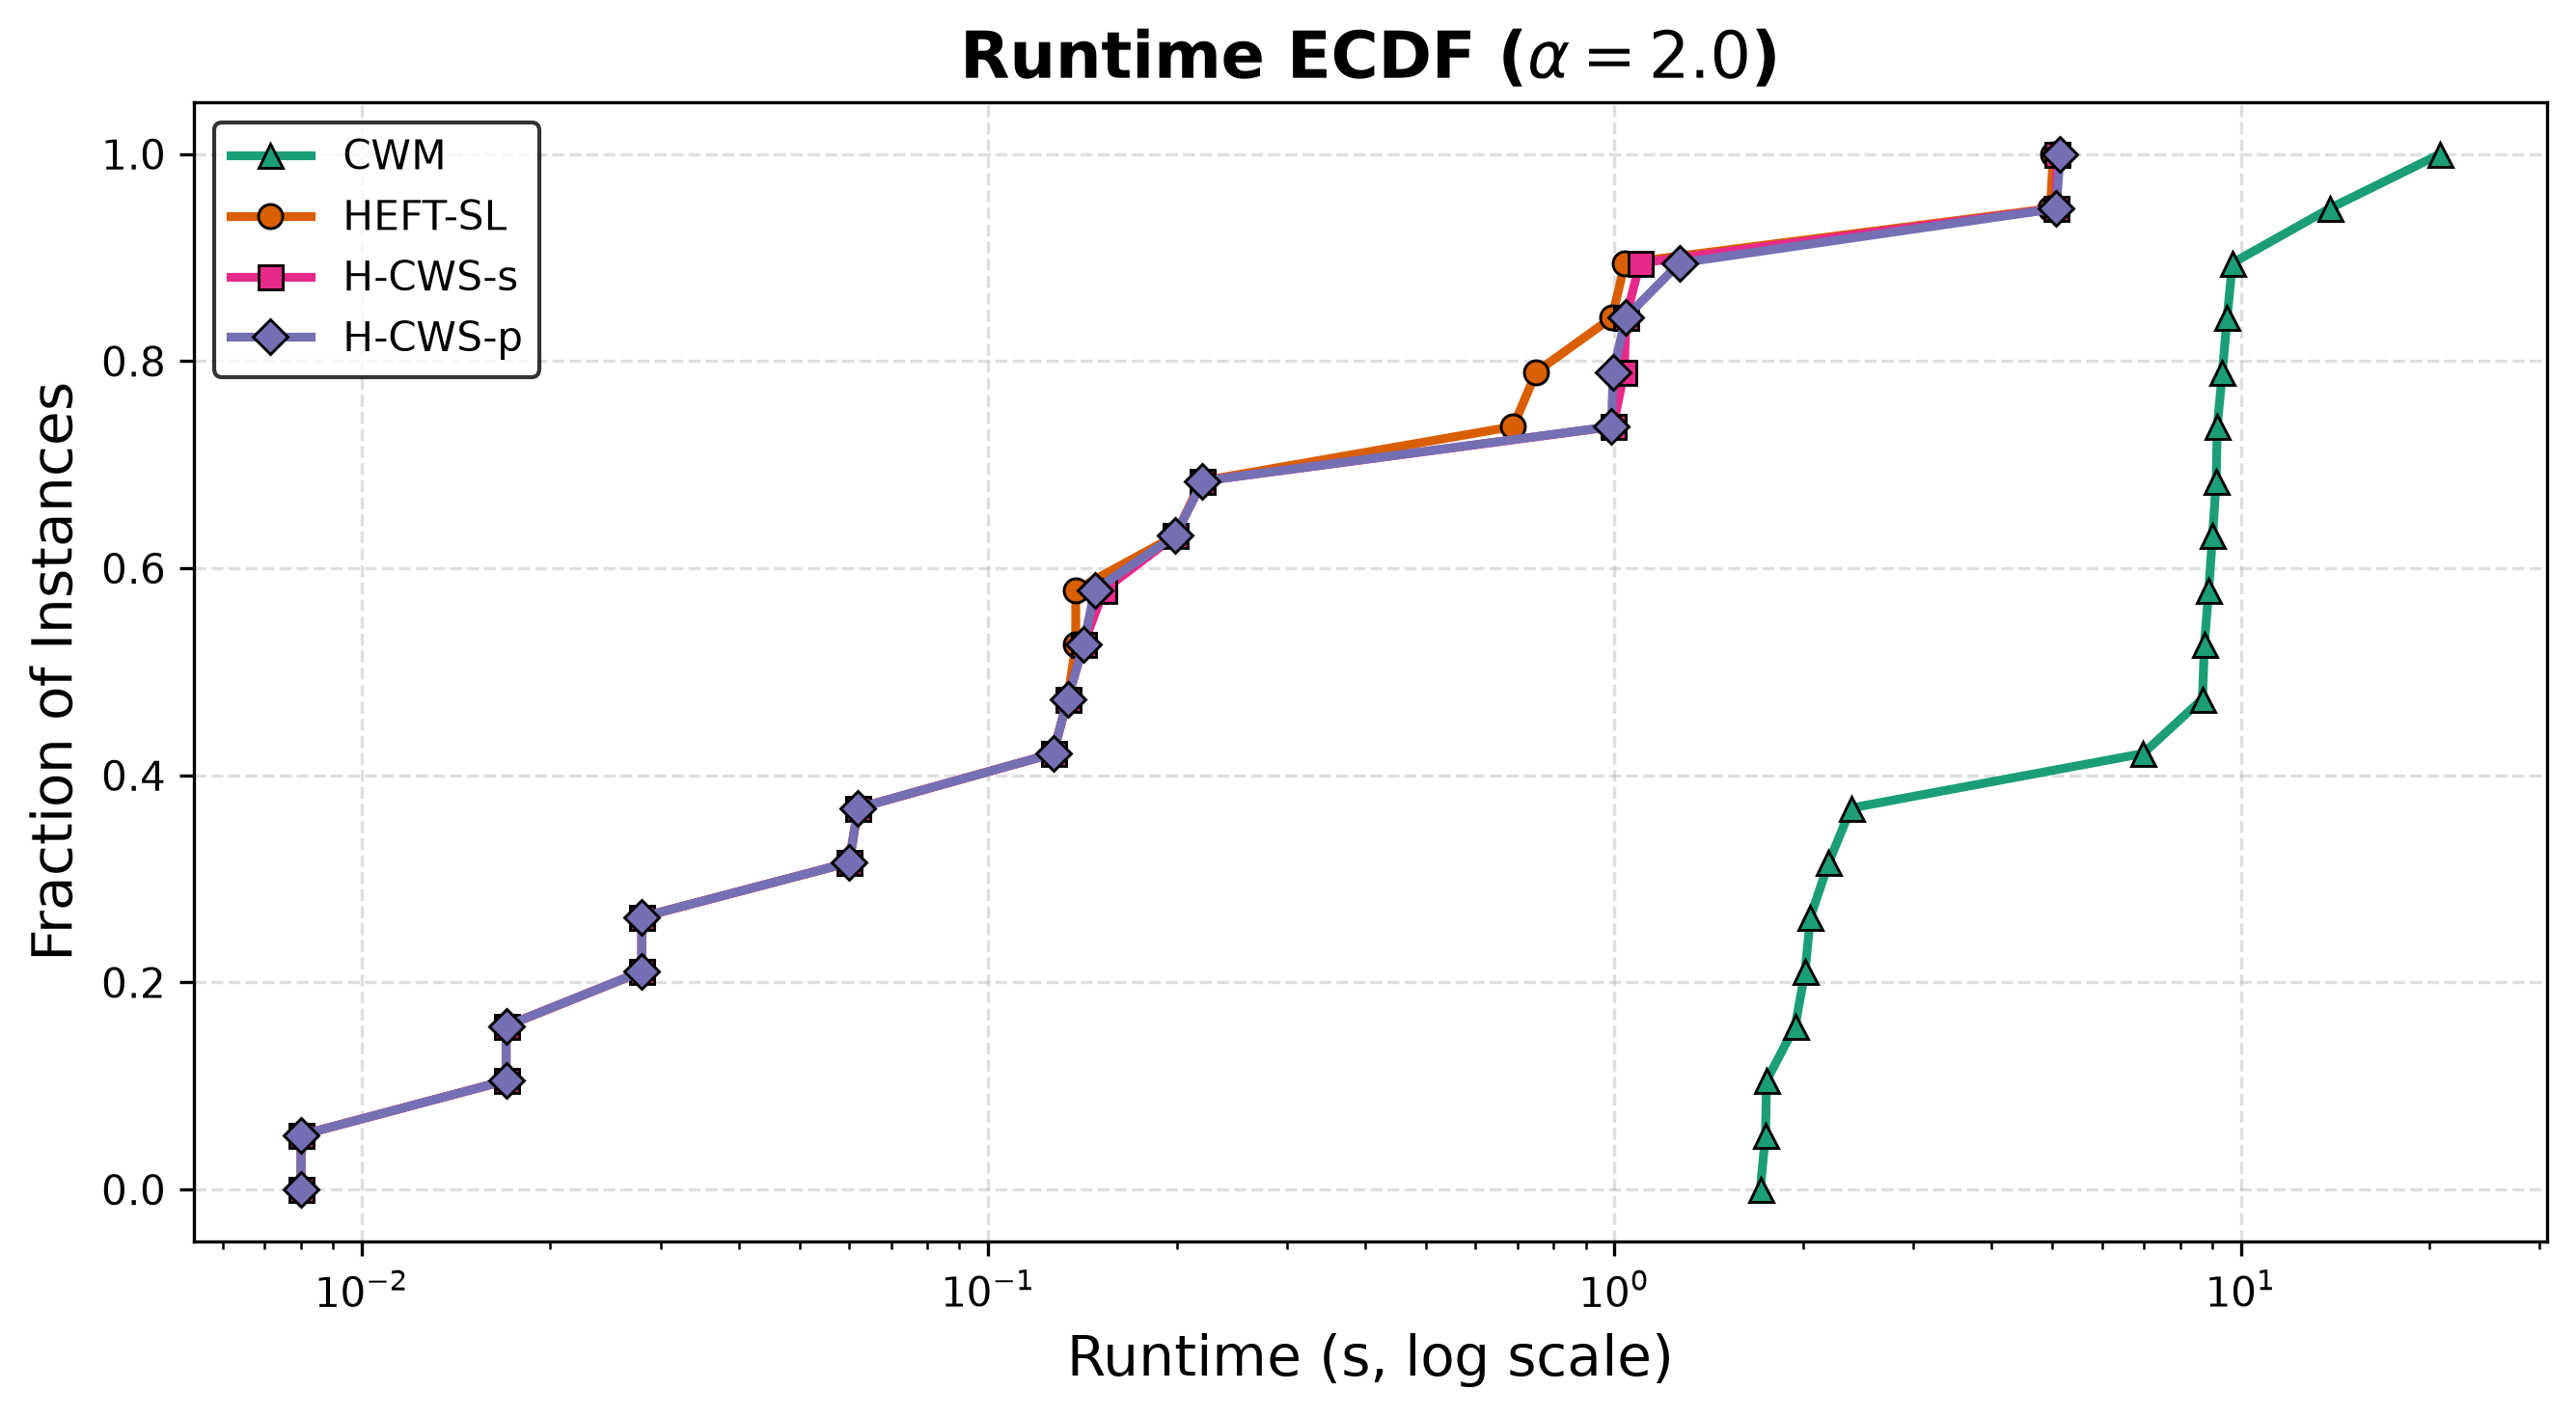

In [27]:
import numpy as np
import matplotlib.pyplot as plt

algos = {
    "CWM":      combined_df_20["time_cwm"],
    "HEFT-SL":  combined_df_20["time_heft"],
    "H-CWS-s":    combined_df_20["time_slack"],
    "H-CWS-p": combined_df_20["time_pressure"]
}

colors = ["#1b9e77", "#d95f02", "#e7298a", "#7570b3"]
markers = ["^", "o", "s", "D"]

plt.figure(figsize=(9,5), dpi=300)

for (name, series), color, marker in zip(algos.items(), colors, markers):

    # Clean
    t = pd.to_numeric(series, errors="coerce").dropna()
    t = np.sort(t)

    y = np.linspace(0, 1, len(t))

    plt.plot(
        t, y,
        label=name,
        color=color,
        marker=marker,
        markevery=max(1, len(t)//40),
        markersize=6,
        linewidth=2.2,
        markeredgecolor="black",
        markeredgewidth=0.7
    )

plt.xscale("log")
plt.xlabel("Runtime (s, log scale)", fontsize=14)
plt.ylabel("Fraction of Instances", fontsize=14)
plt.title(r"Runtime ECDF ($\alpha=2.0$)", fontsize=16, weight="bold")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/ecdf_execution_time_20.png", bbox_inches='tight')
plt.show()

10


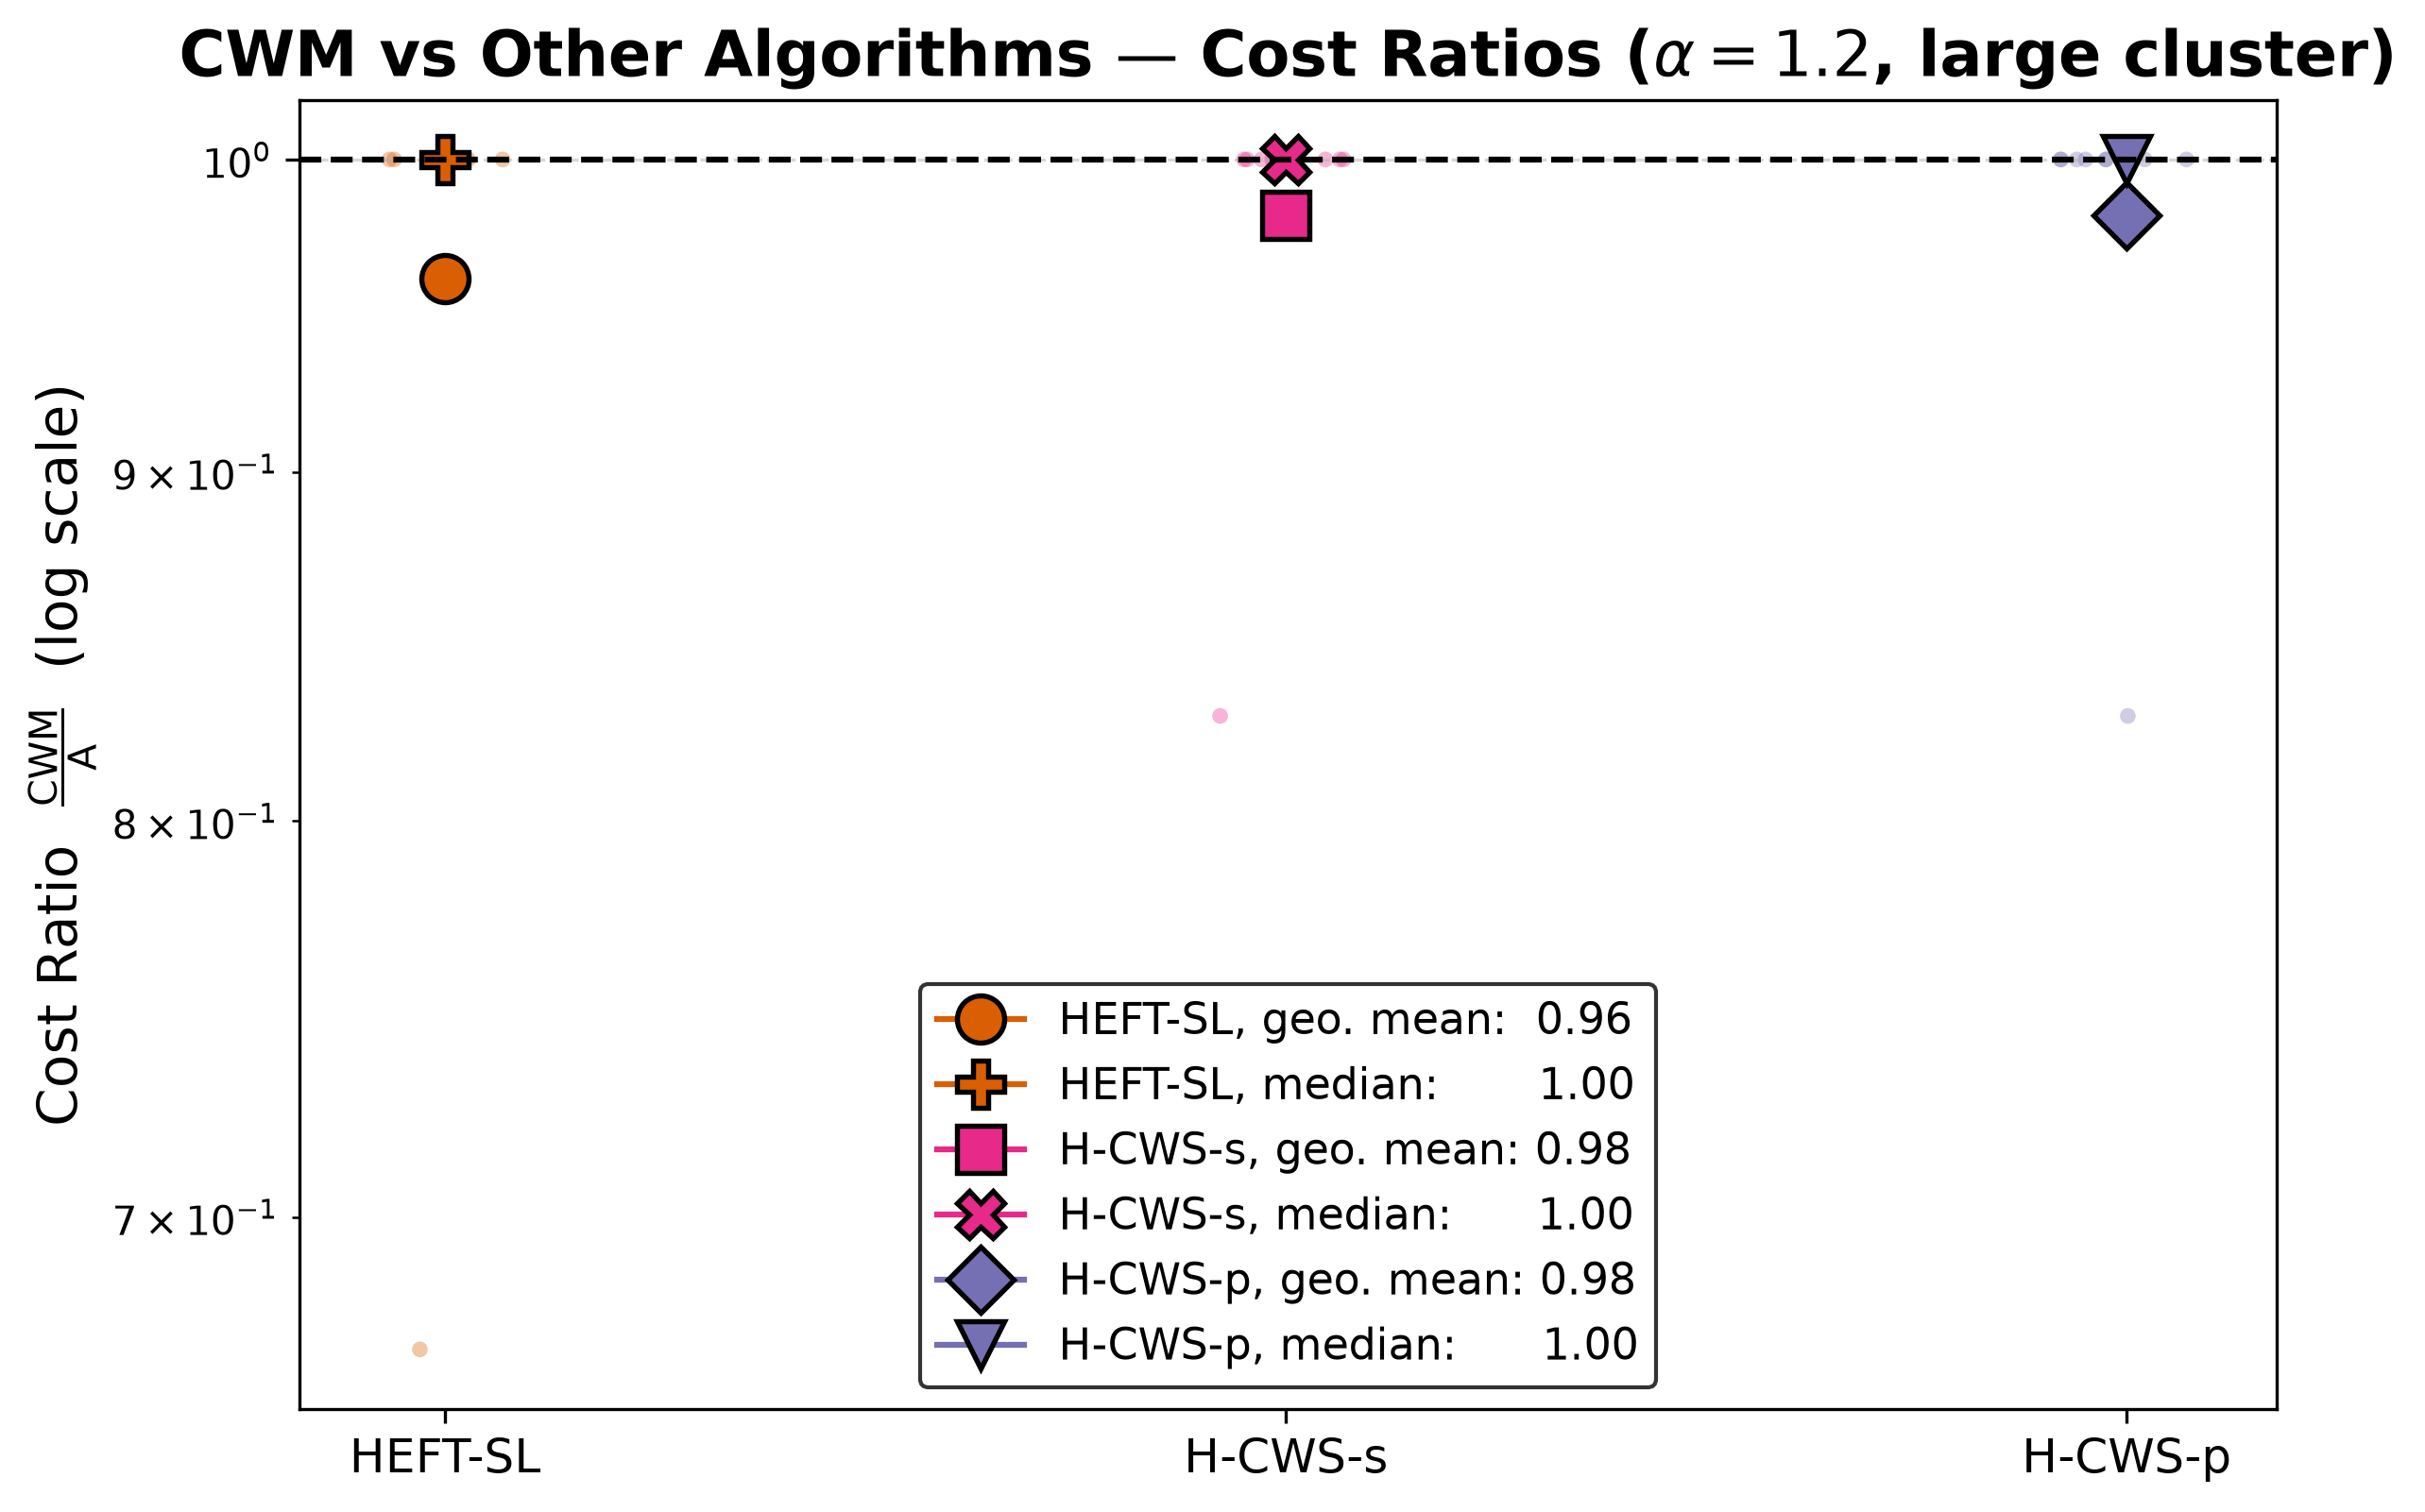

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.table import Table
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

combined_df_12_large = combined_df_12[combined_df_12["experiment_norm"].str.contains("large")].copy()
# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     (combined_df_12_large["cost_cwm"]) / (combined_df_12_large["cost_heft"]),
    "H-CWS-s":    (combined_df_12_large["cost_cwm"]) / (combined_df_12_large["cost_slack"]),
    "H-CWS-p": (combined_df_12_large["cost_cwm"]) / (combined_df_12_large["cost_pressure"]),
}

print(len(combined_df_12_large))

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
median_markers = ["P", "X", "v"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.2$, large cluster)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black", loc="lower center") #bbox_to_anchor=(1.40, 0.45))


# ----------------------------------------------------
# 3. Embedded Zoom Subplot (inside the main plot)
# ----------------------------------------------------
"""
ax_zoom = inset_axes(
    ax,
    width="85%",         # size relative to parent axis
    height="75%",
    bbox_to_anchor=(0.95, 0.01, 0.45, 0.35),
    bbox_transform=ax.transAxes,
    borderpad=0
)

for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.06, 0.06, size=len(r))
    mask = (r >= ZOOM_LOWER) & (r <= ZOOM_UPPER)

    # scatter zoomed points
    ax_zoom.scatter(
        np.full_like(r[mask], x_positions[i]) + jitter[mask],
        r[mask],
        s=20,
        alpha=0.45,
        color=colors[i],
        edgecolors="none"
    )

    # geometric mean (only if inside zoom range)
    gm = geo_means[alg]
    if ZOOM_LOWER <= gm <= ZOOM_UPPER:
        ax_zoom.plot(
            x_positions[i],
            gm,
            marker=markers[i],
            markersize=9,
            markeredgewidth=1.1,
            markeredgecolor="black",
            color=colors[i]
        )

ax_zoom.axhline(1.0, linestyle="--", color="black")
ax_zoom.set_ylim(ZOOM_LOWER, ZOOM_UPPER)

ax_zoom.set_xticks(x_positions)
ax_zoom.set_xticklabels([])  # clean look
ax_zoom.set_yticks([])

#ax_zoom.set_title("Zoom", fontsize=10)
"""

#plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_12_largeCluster.png", bbox_inches='tight')
plt.show()

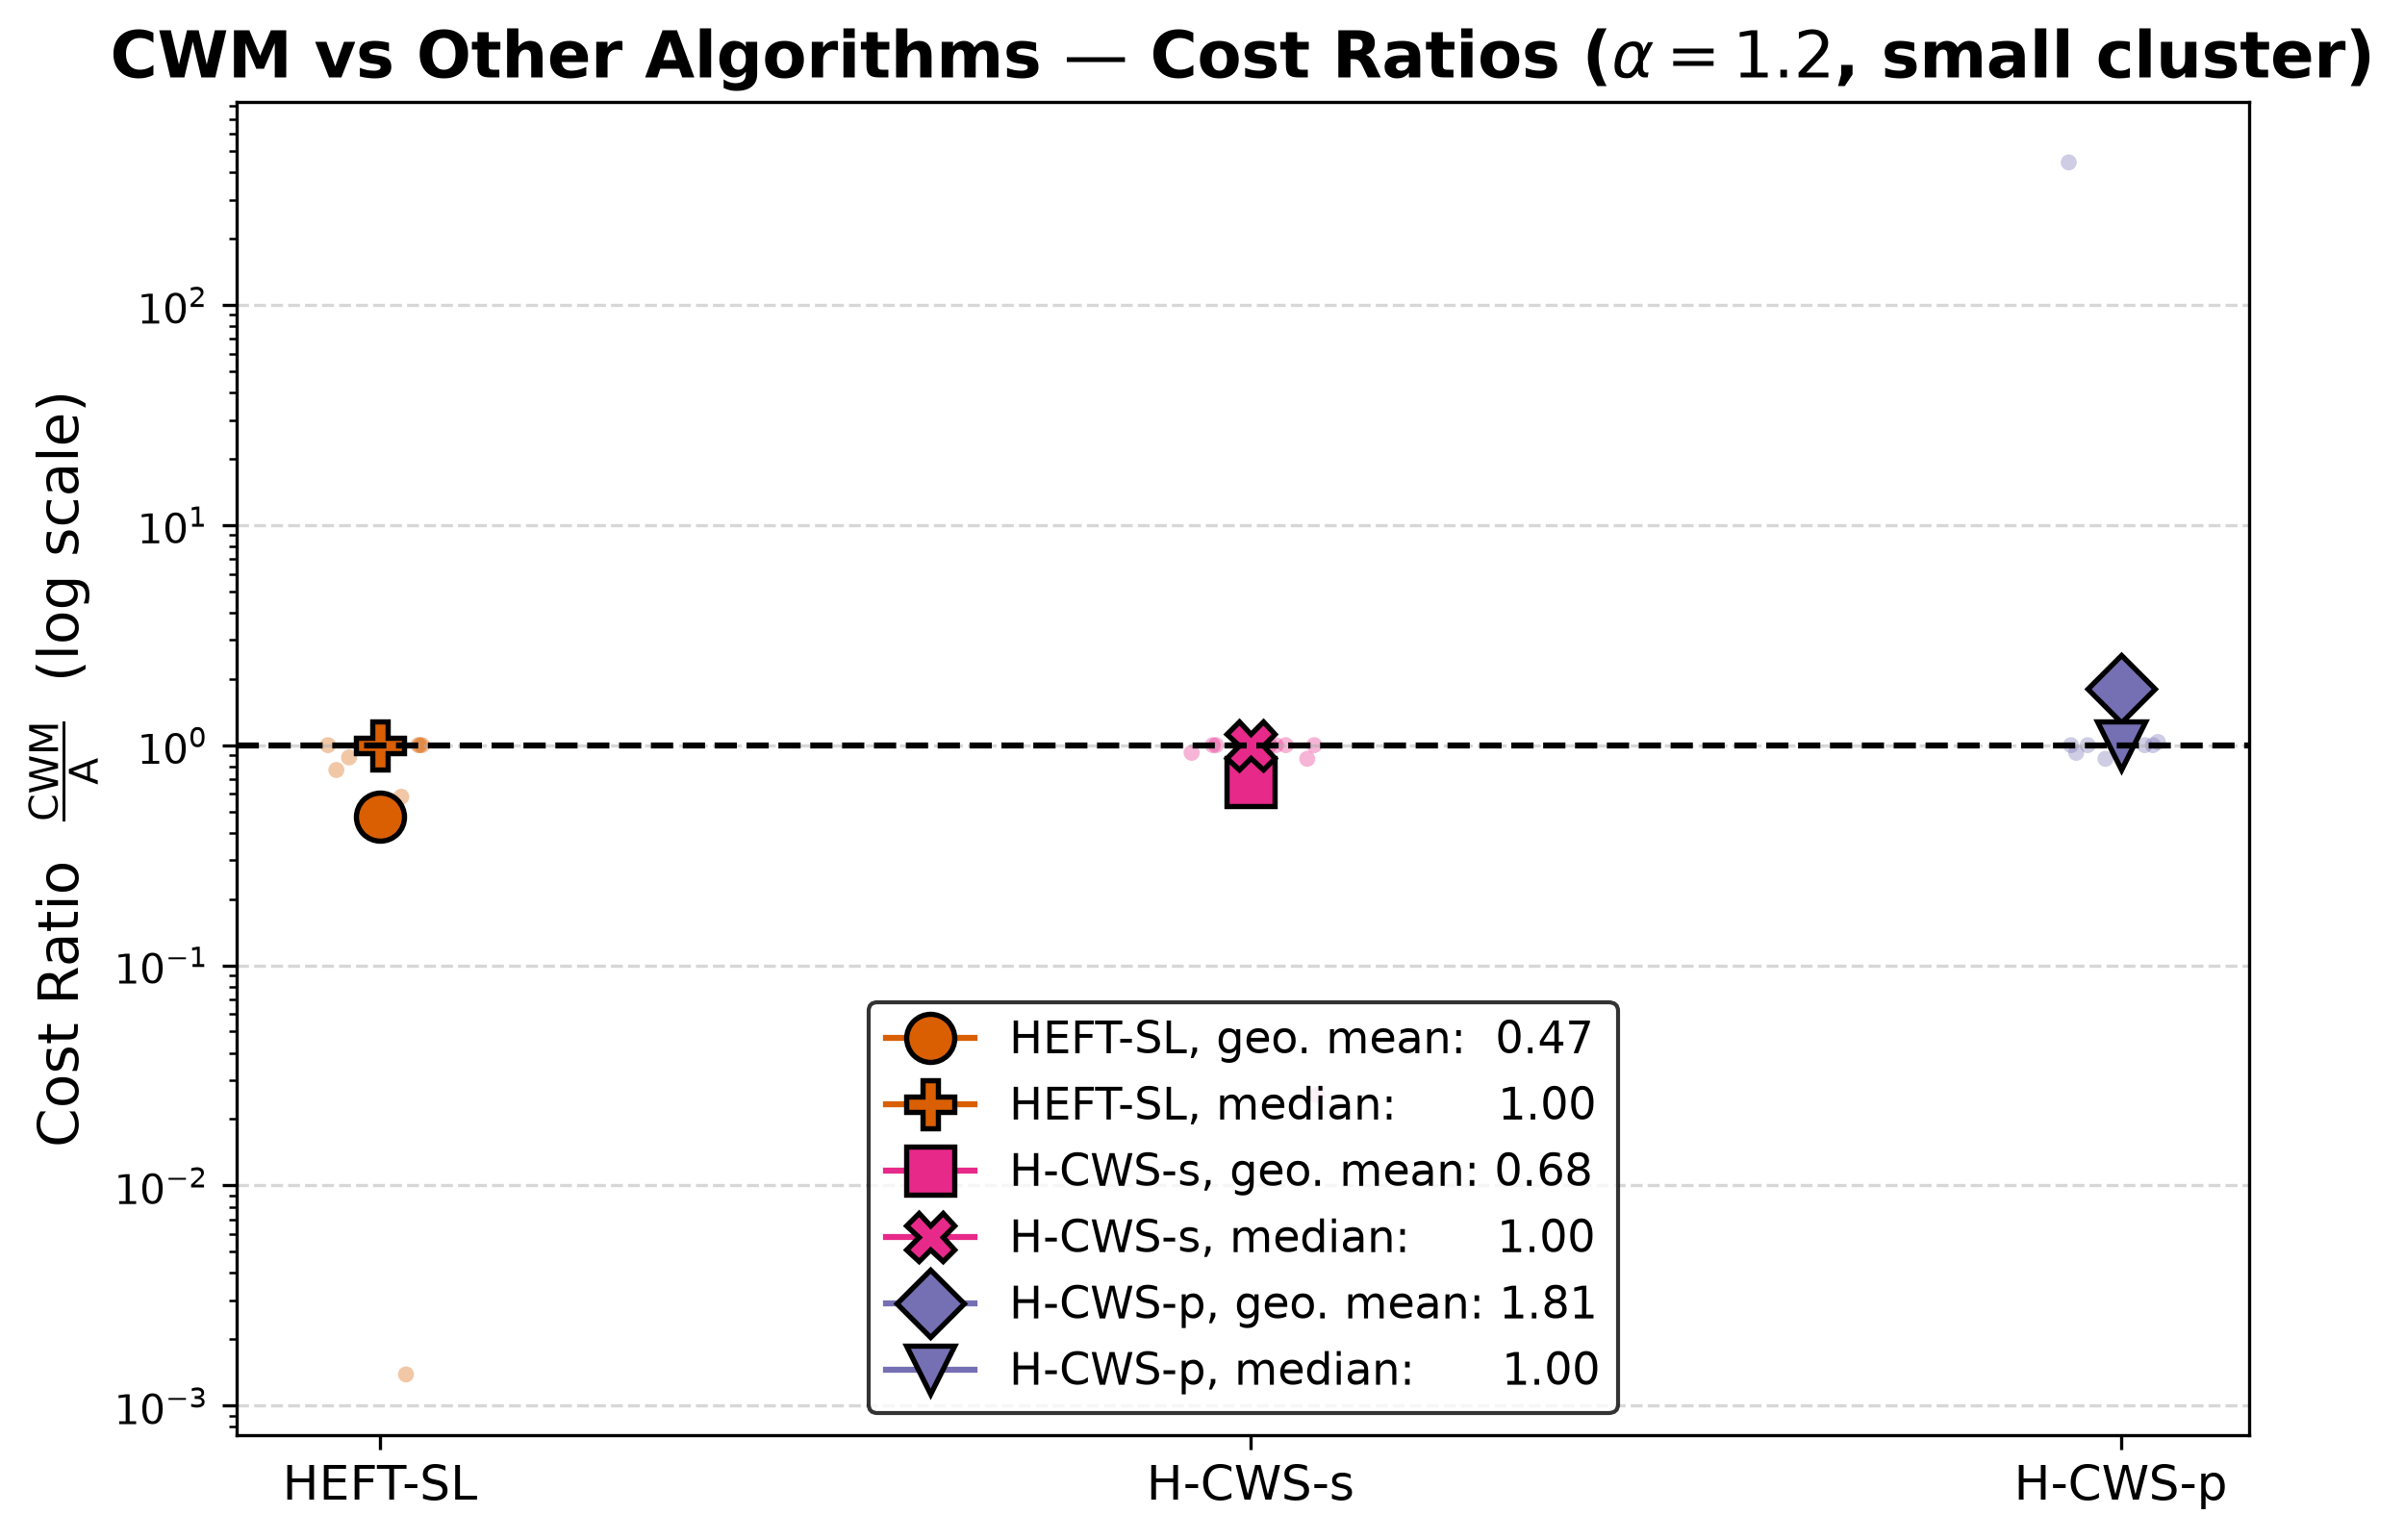

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.table import Table
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

combined_df_12_small = combined_df_12[combined_df_12["experiment_norm"].str.contains("small")].copy()
# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     (combined_df_12_small["cost_cwm"]) / (combined_df_12_small["cost_heft"]),
    "H-CWS-s":    (combined_df_12_small["cost_cwm"]) / (combined_df_12_small["cost_slack"]),
    "H-CWS-p": (combined_df_12_small["cost_cwm"]) / (combined_df_12_small["cost_pressure"]),
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
median_markers = ["P", "X", "v"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.2$, small cluster)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black", loc="lower center")#, bbox_to_anchor=(1.40, 0.45))


# ----------------------------------------------------
# 3. Embedded Zoom Subplot (inside the main plot)
# ----------------------------------------------------
"""
ax_zoom = inset_axes(
    ax,
    width="85%",         # size relative to parent axis
    height="75%",
    bbox_to_anchor=(0.95, 0.01, 0.45, 0.35),
    bbox_transform=ax.transAxes,
    borderpad=0
)

for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.06, 0.06, size=len(r))
    mask = (r >= ZOOM_LOWER) & (r <= ZOOM_UPPER)

    # scatter zoomed points
    ax_zoom.scatter(
        np.full_like(r[mask], x_positions[i]) + jitter[mask],
        r[mask],
        s=20,
        alpha=0.45,
        color=colors[i],
        edgecolors="none"
    )

    # geometric mean (only if inside zoom range)
    gm = geo_means[alg]
    if ZOOM_LOWER <= gm <= ZOOM_UPPER:
        ax_zoom.plot(
            x_positions[i],
            gm,
            marker=markers[i],
            markersize=9,
            markeredgewidth=1.1,
            markeredgecolor="black",
            color=colors[i]
        )

ax_zoom.axhline(1.0, linestyle="--", color="black")
ax_zoom.set_ylim(ZOOM_LOWER, ZOOM_UPPER)

ax_zoom.set_xticks(x_positions)
ax_zoom.set_xticklabels([])  # clean look
ax_zoom.set_yticks([])

#ax_zoom.set_title("Zoom", fontsize=10)
"""
#plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_12_smallCluster.png", bbox_inches='tight')
plt.show()

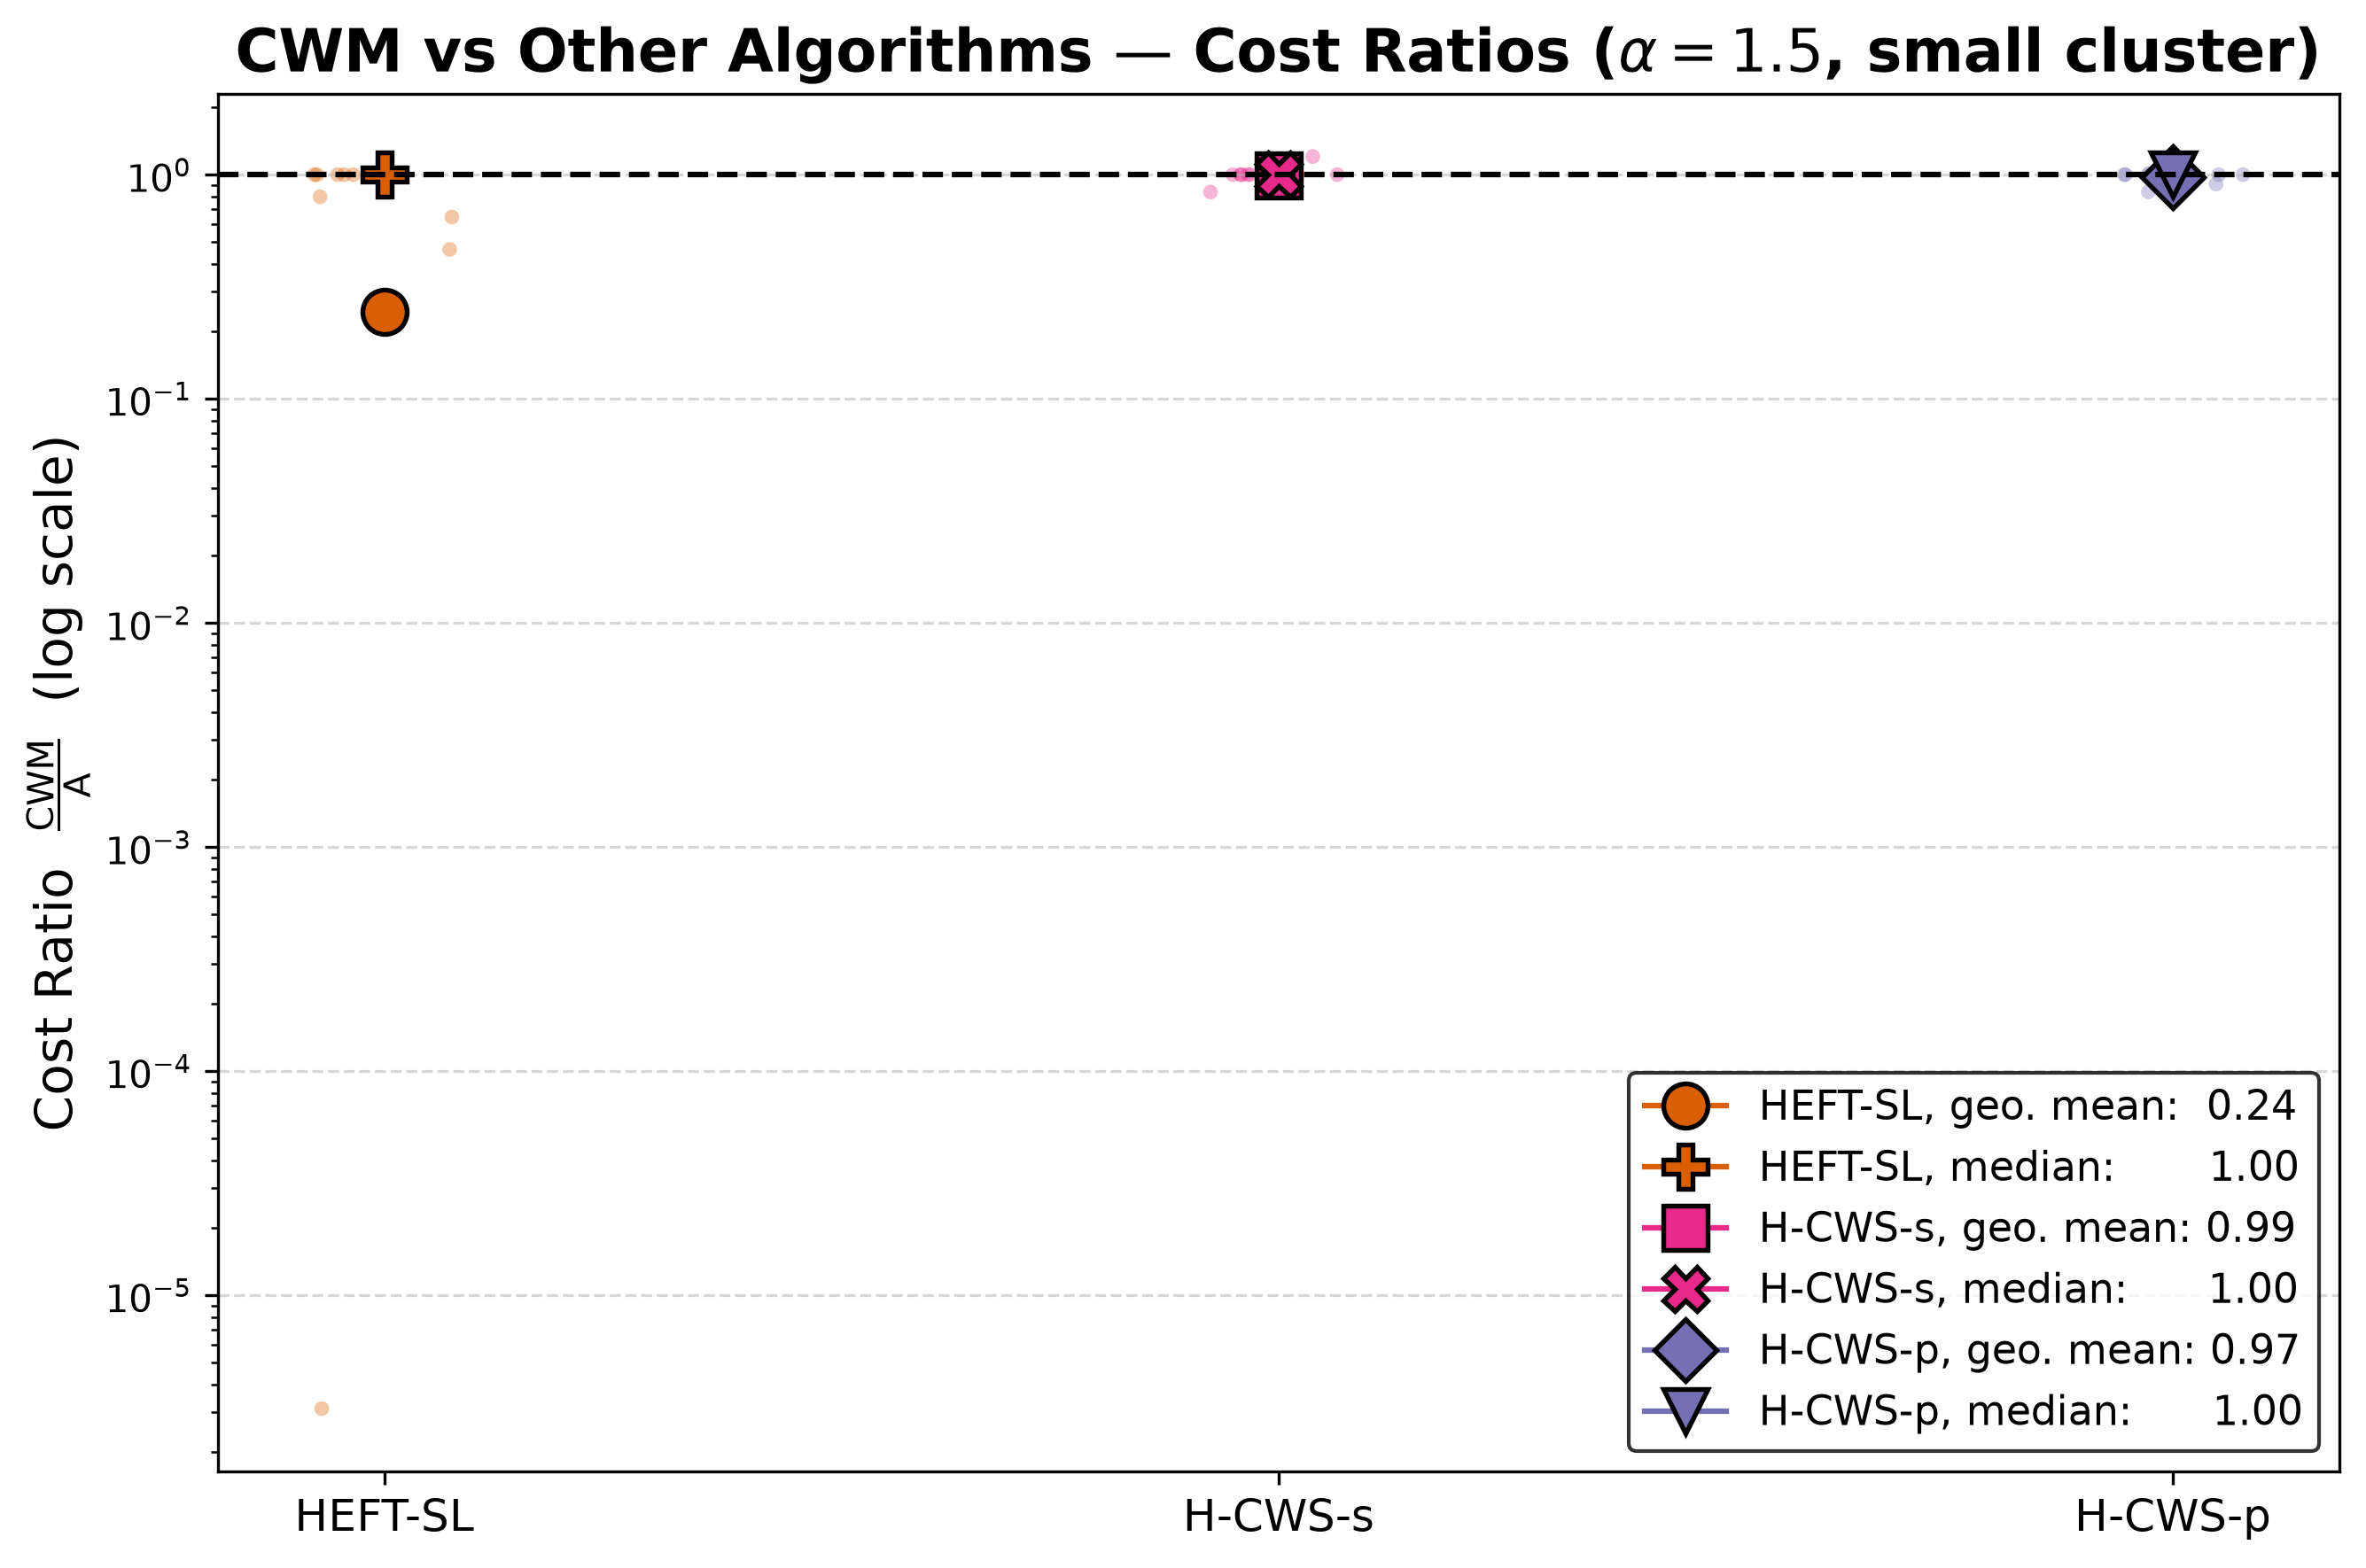

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

combined_df_15_small = combined_df_15[combined_df_15["experiment_norm"].str.contains("small")].copy()

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_15_small["cost_cwm"] / combined_df_15_small["cost_heft"],
    "H-CWS-s":    combined_df_15_small["cost_cwm"] / combined_df_15_small["cost_slack"],
    "H-CWS-p": combined_df_15_small["cost_cwm"] / combined_df_15_small["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )



ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.5$, small cluster)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")


plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_15_smallCluster.png", bbox_inches='tight')
plt.show()

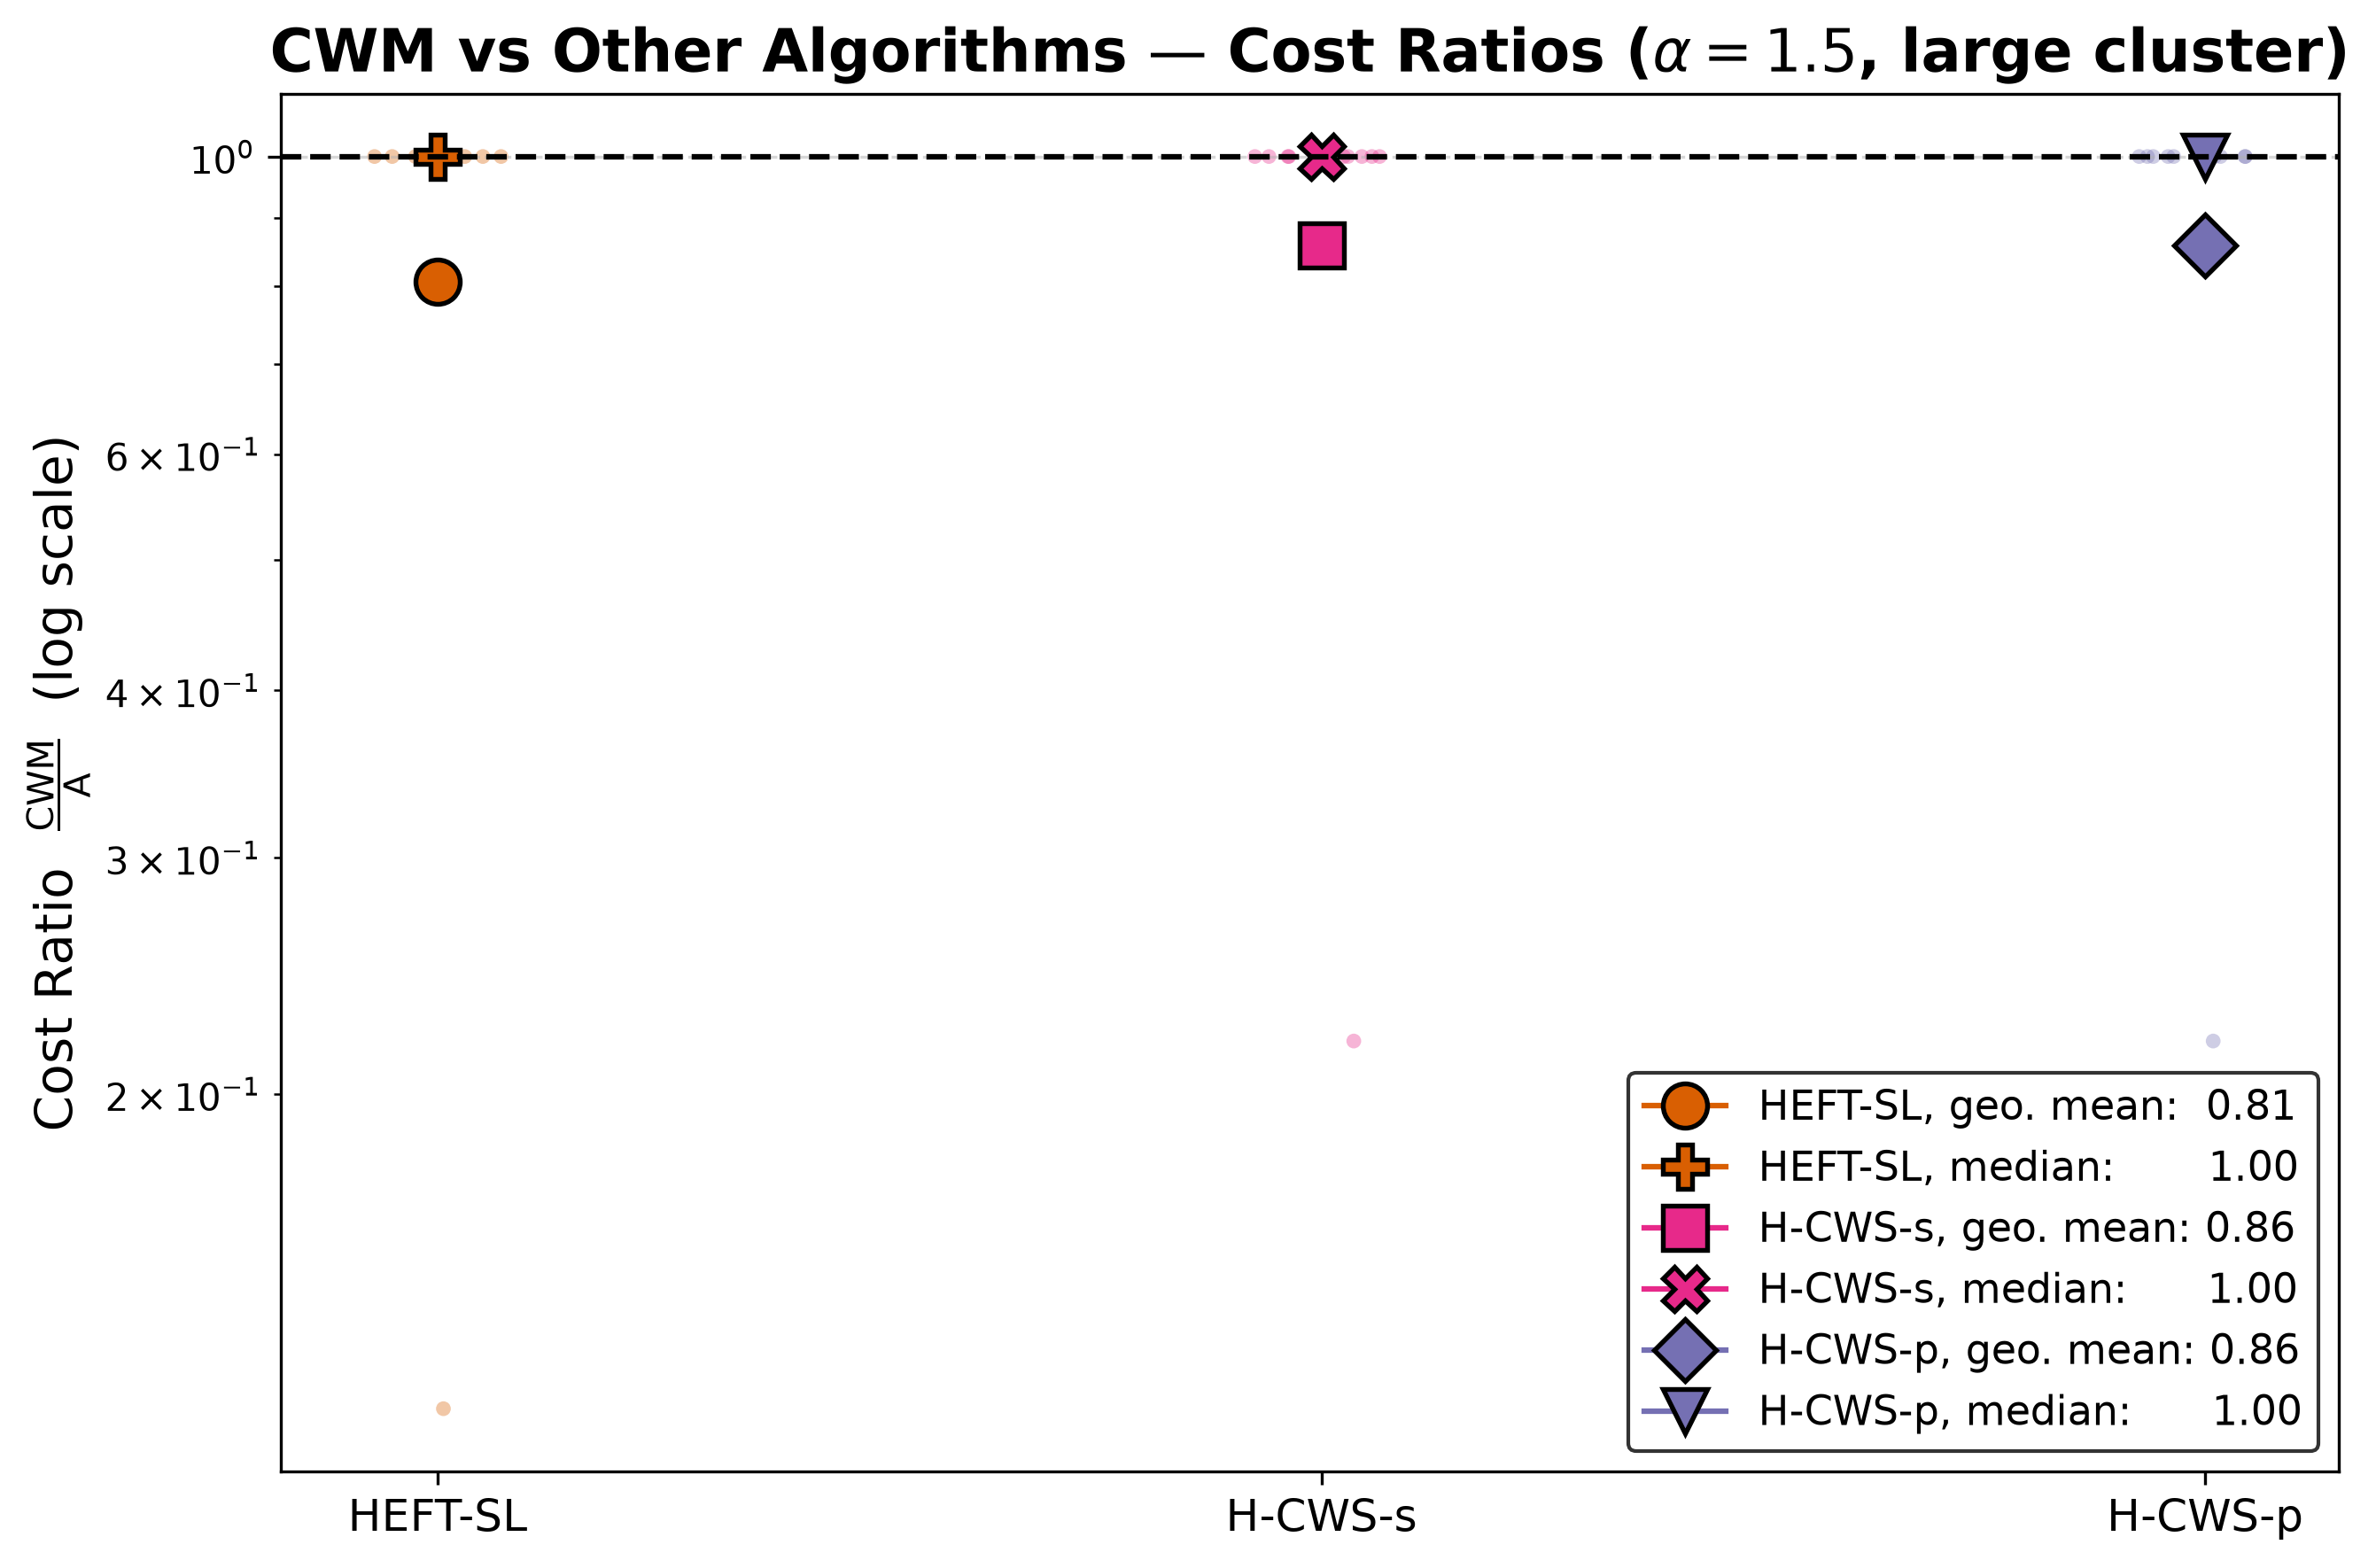

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

combined_df_15_large = combined_df_15[combined_df_15["experiment_norm"].str.contains("large")].copy()

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_15_large["cost_cwm"] / combined_df_15_large["cost_heft"],
    "H-CWS-s":    combined_df_15_large["cost_cwm"] / combined_df_15_large["cost_slack"],
    "H-CWS-p": combined_df_15_large["cost_cwm"] / combined_df_15_large["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )



ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.5$, large cluster)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")


plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_15_largeCluster.png", bbox_inches='tight')
plt.show()

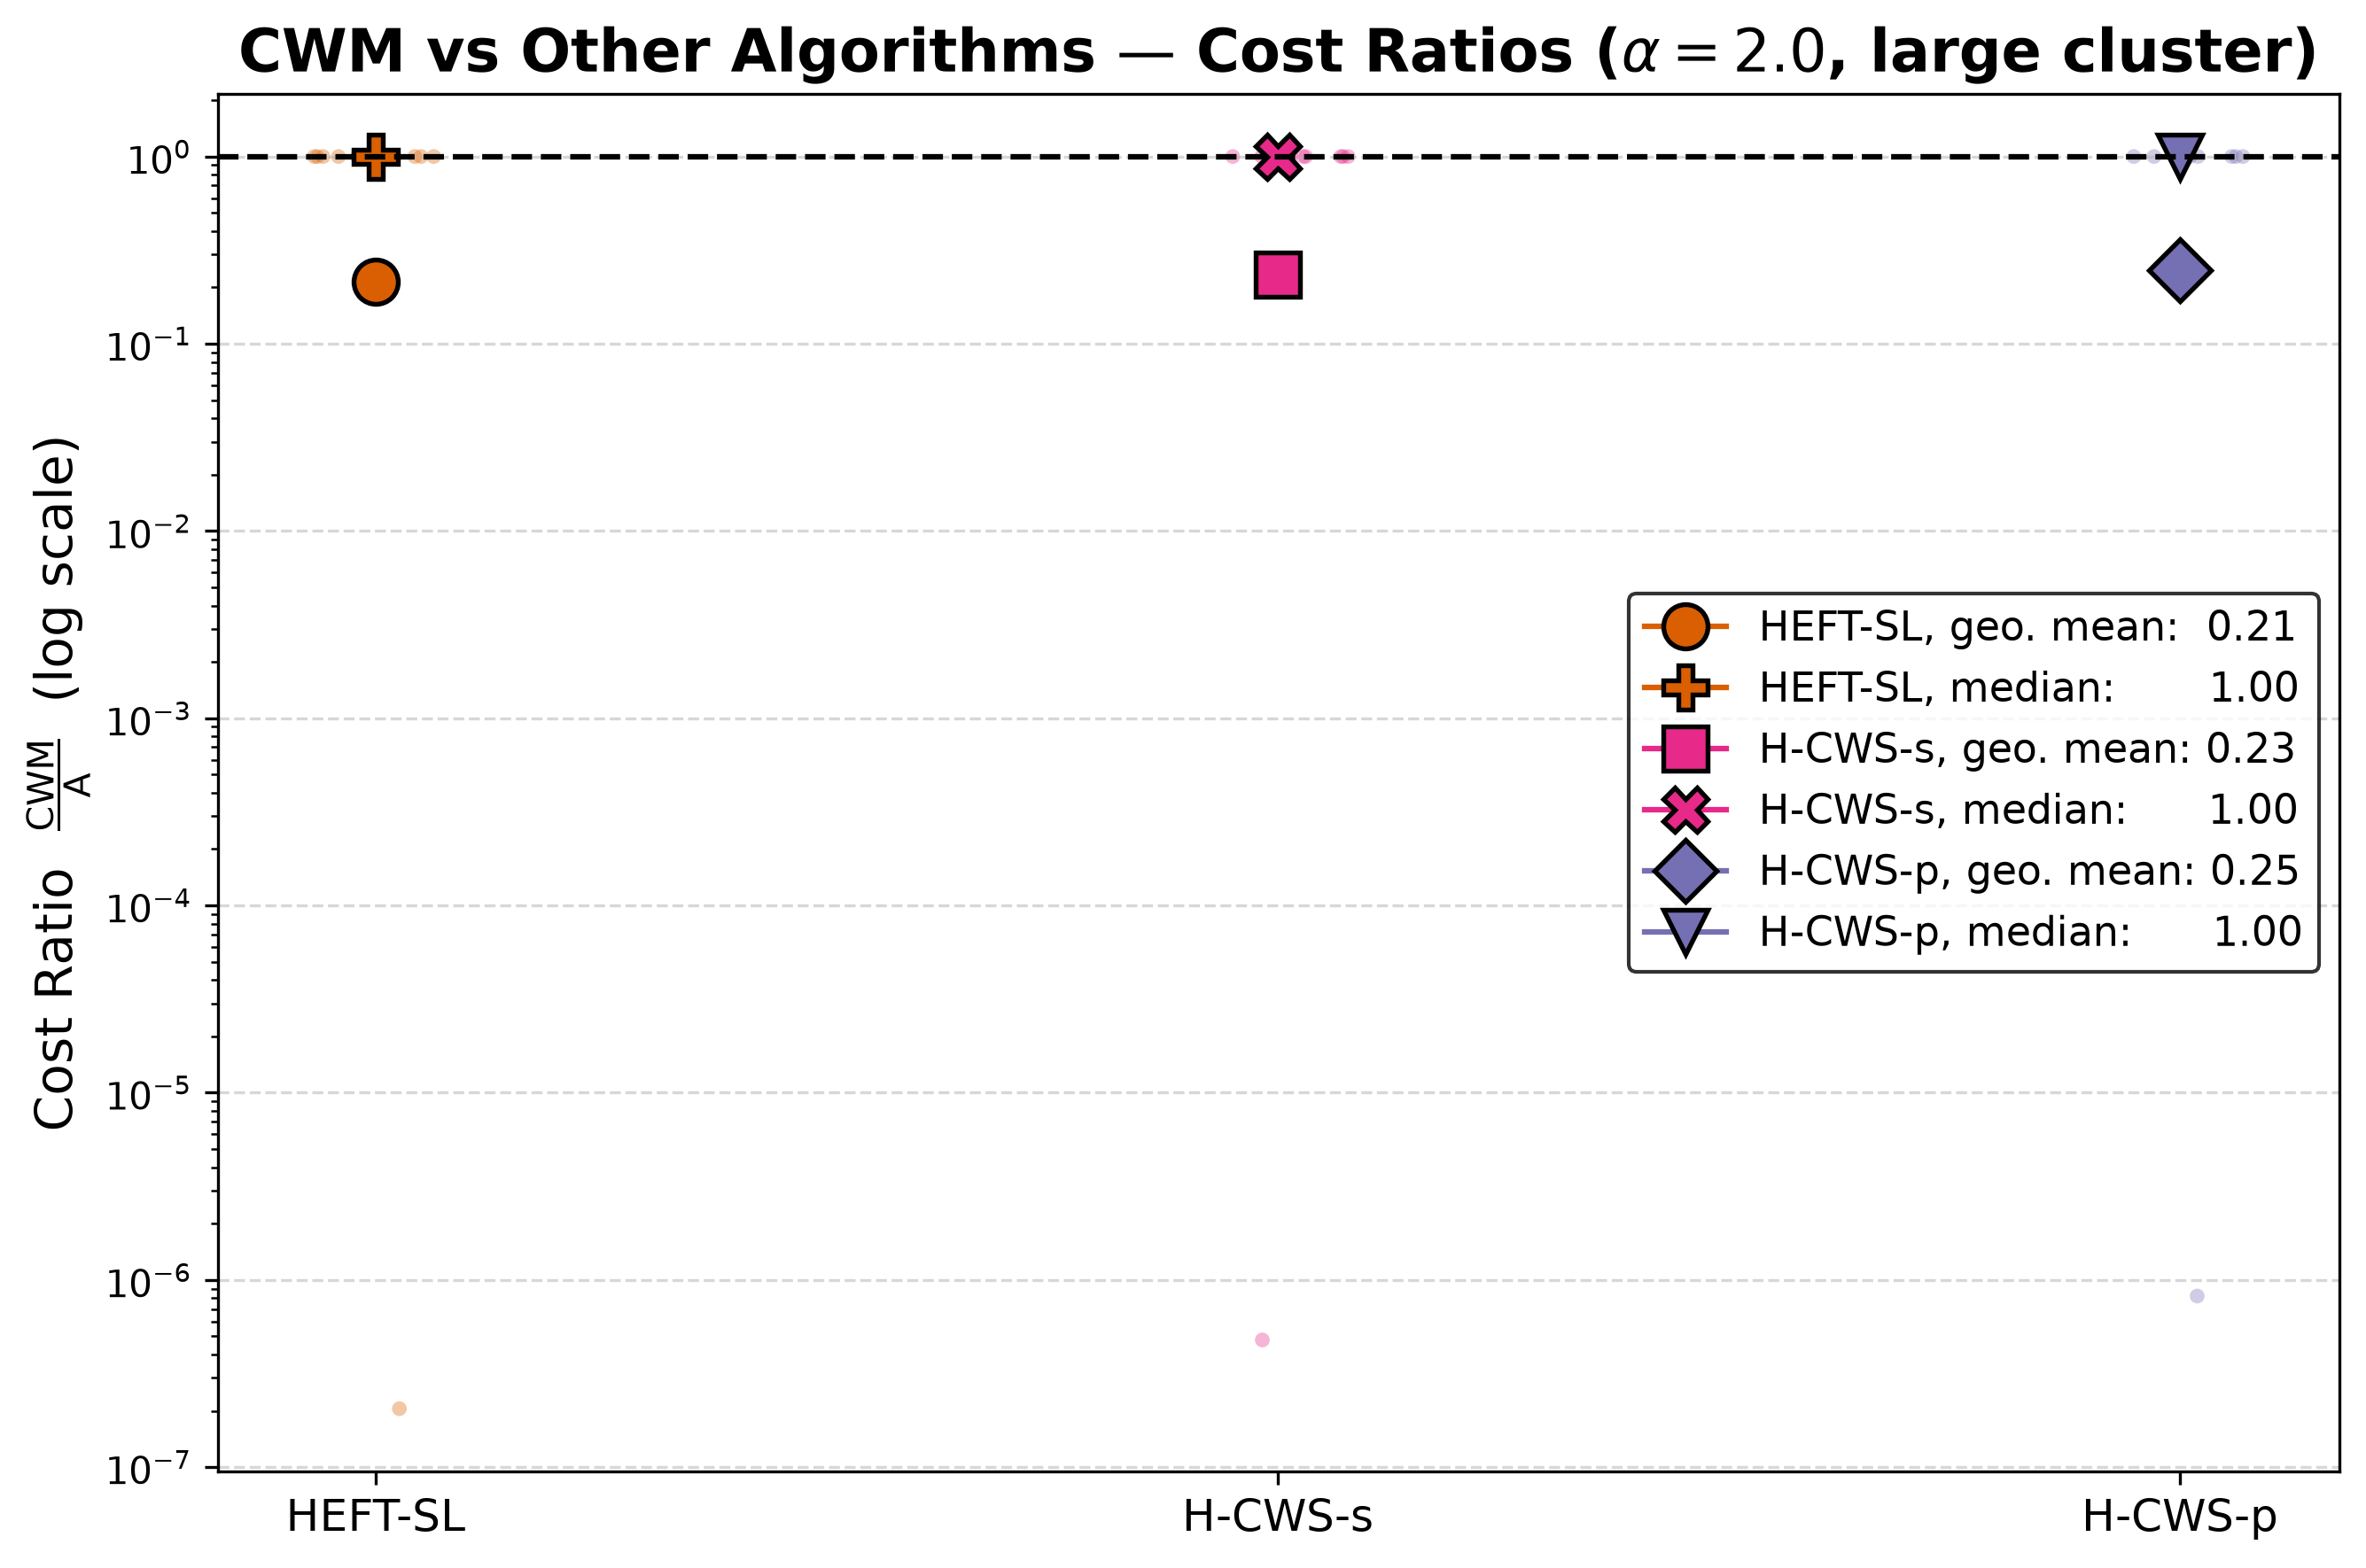

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

combined_df_20_large = combined_df_20[combined_df_20["experiment_norm"].str.contains("large")].copy()

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_20_large["cost_cwm"] / combined_df_20_large["cost_heft"],
    "H-CWS-s":    combined_df_20_large["cost_cwm"] / combined_df_20_large["cost_slack"],
    "H-CWS-p": combined_df_20_large["cost_cwm"] / combined_df_20_large["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}
# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}


algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=2.0$, large cluster)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_20_largeCluster.png", bbox_inches='tight')
plt.show()

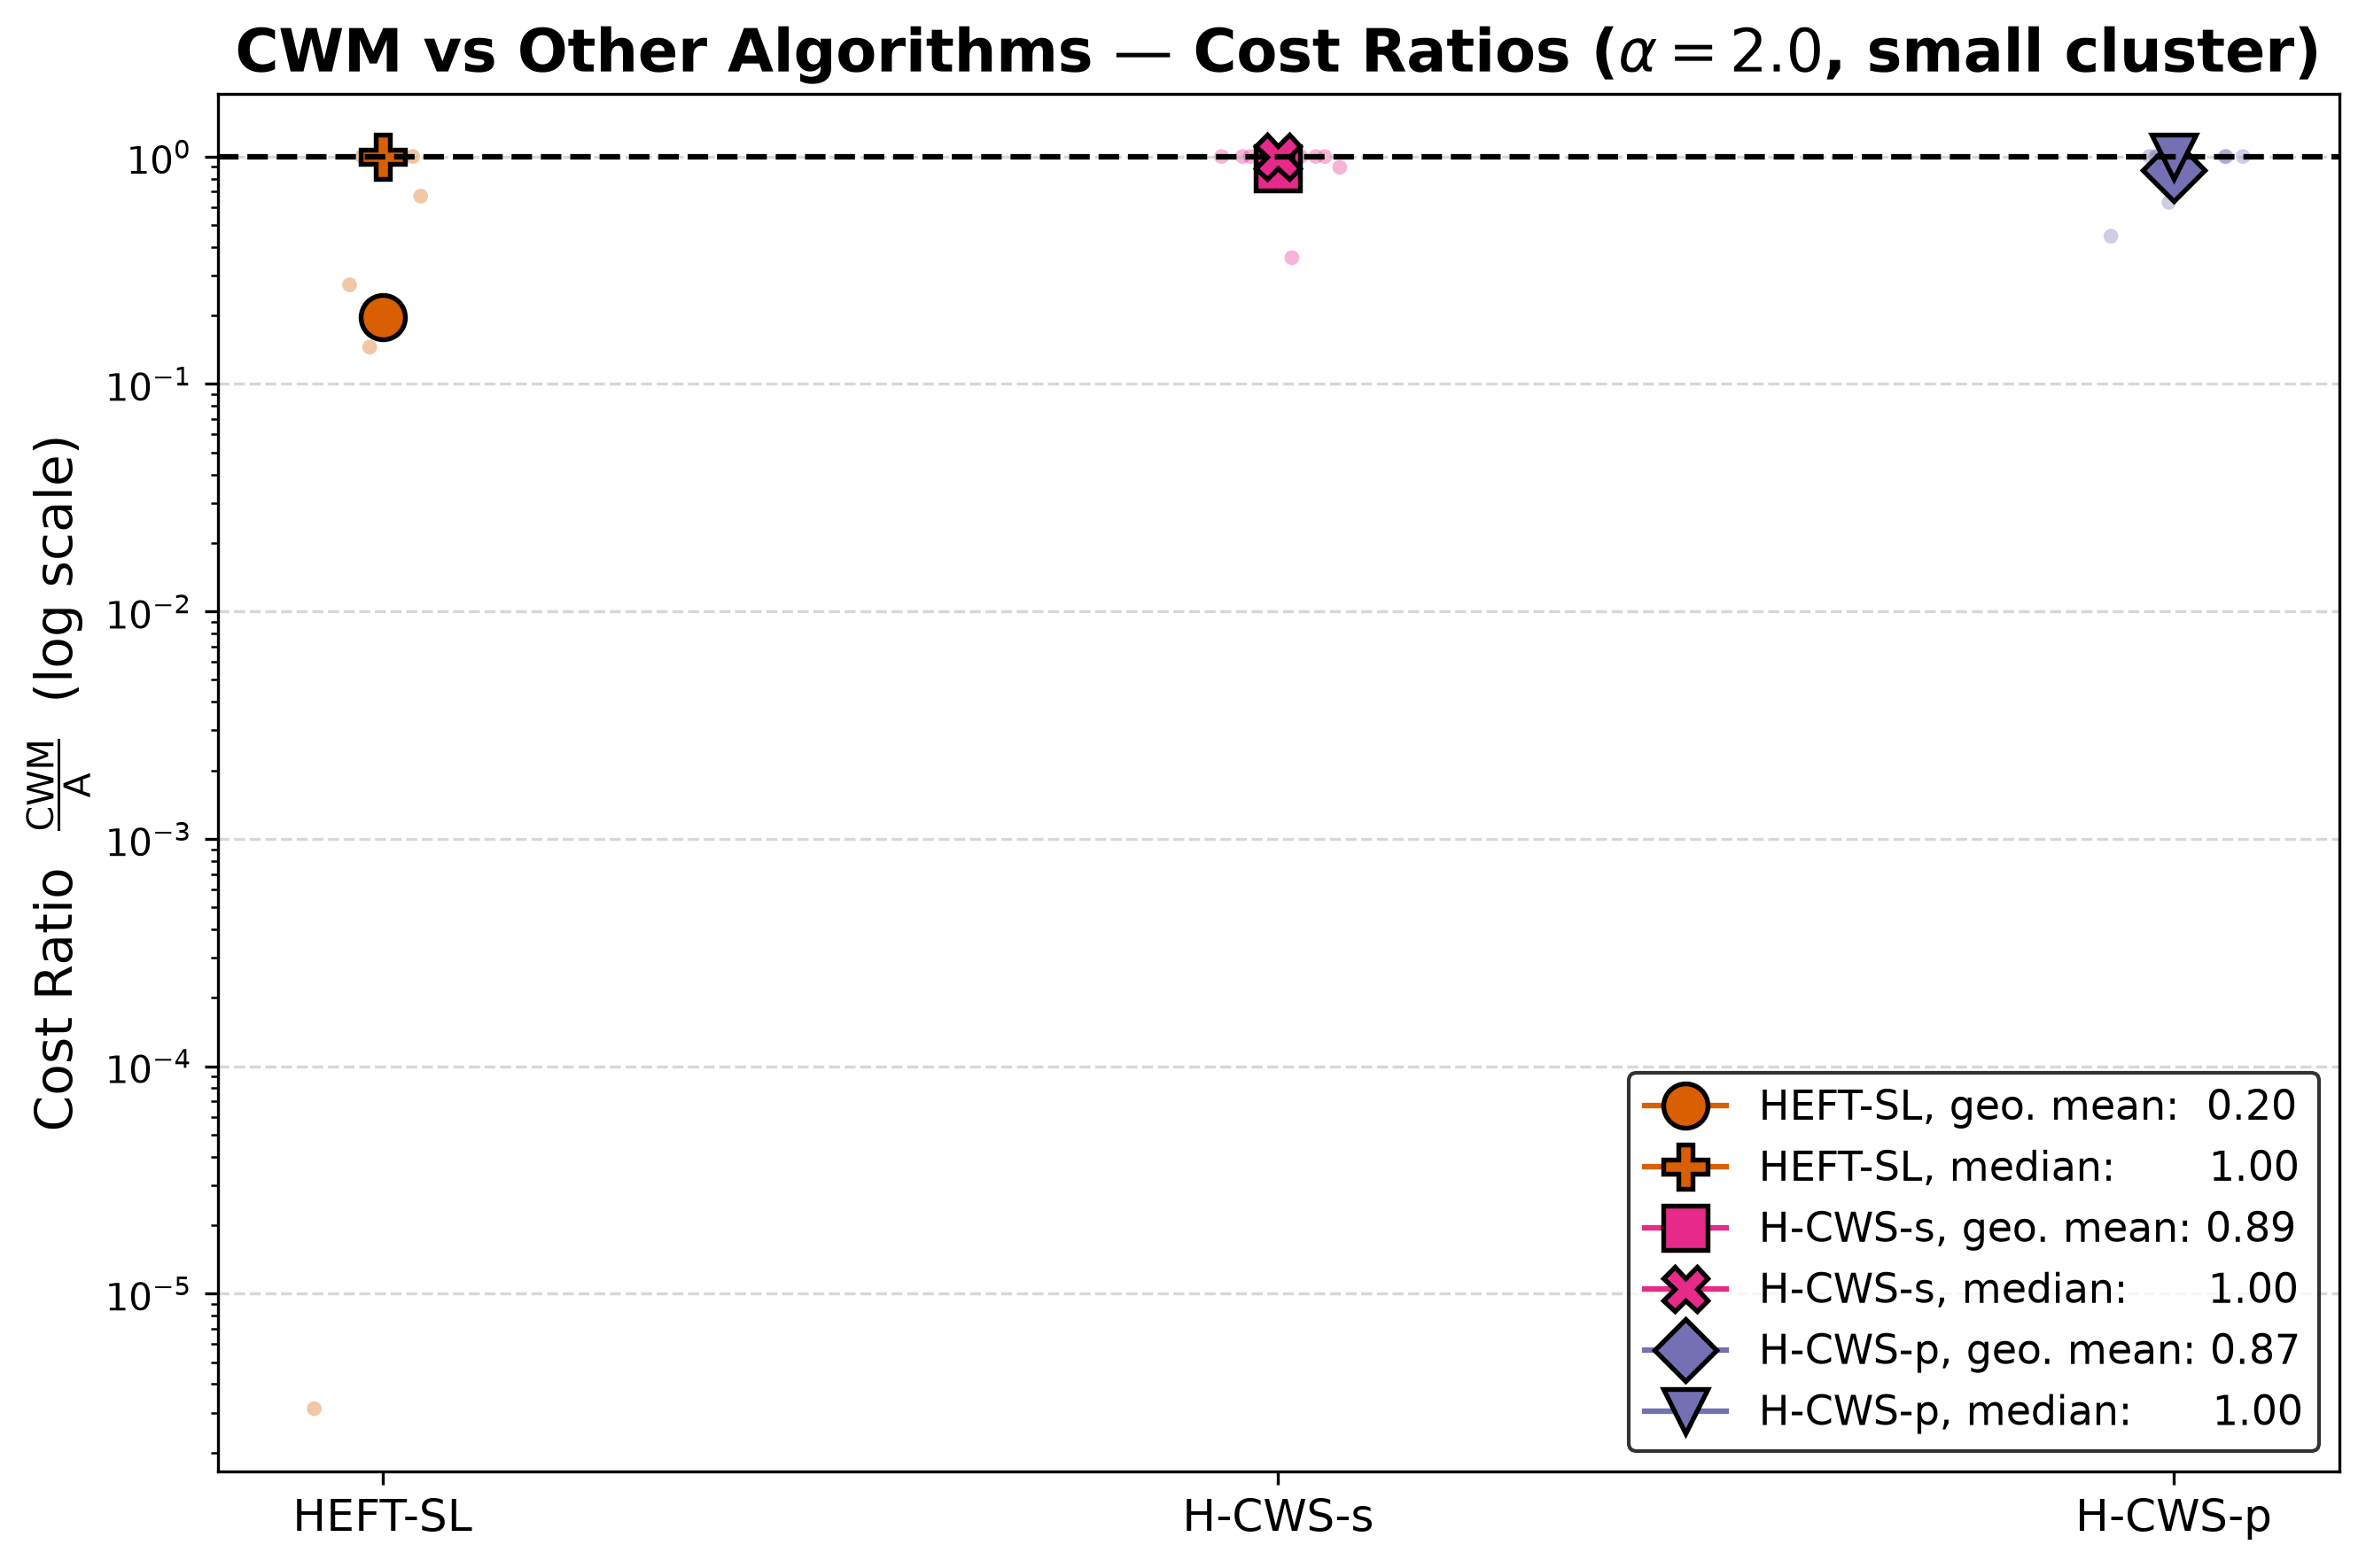

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

combined_df_20_small = combined_df_20[combined_df_20["experiment_norm"].str.contains("small")].copy()

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_20_small["cost_cwm"] / combined_df_20_small["cost_heft"],
    "H-CWS-s":    combined_df_20_small["cost_cwm"] / combined_df_20_small["cost_slack"],
    "H-CWS-p": combined_df_20_small["cost_cwm"] / combined_df_20_small["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}
# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}


algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=2.0$, small cluster)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")

plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_20_smallCluster.png", bbox_inches='tight')
plt.show()

10


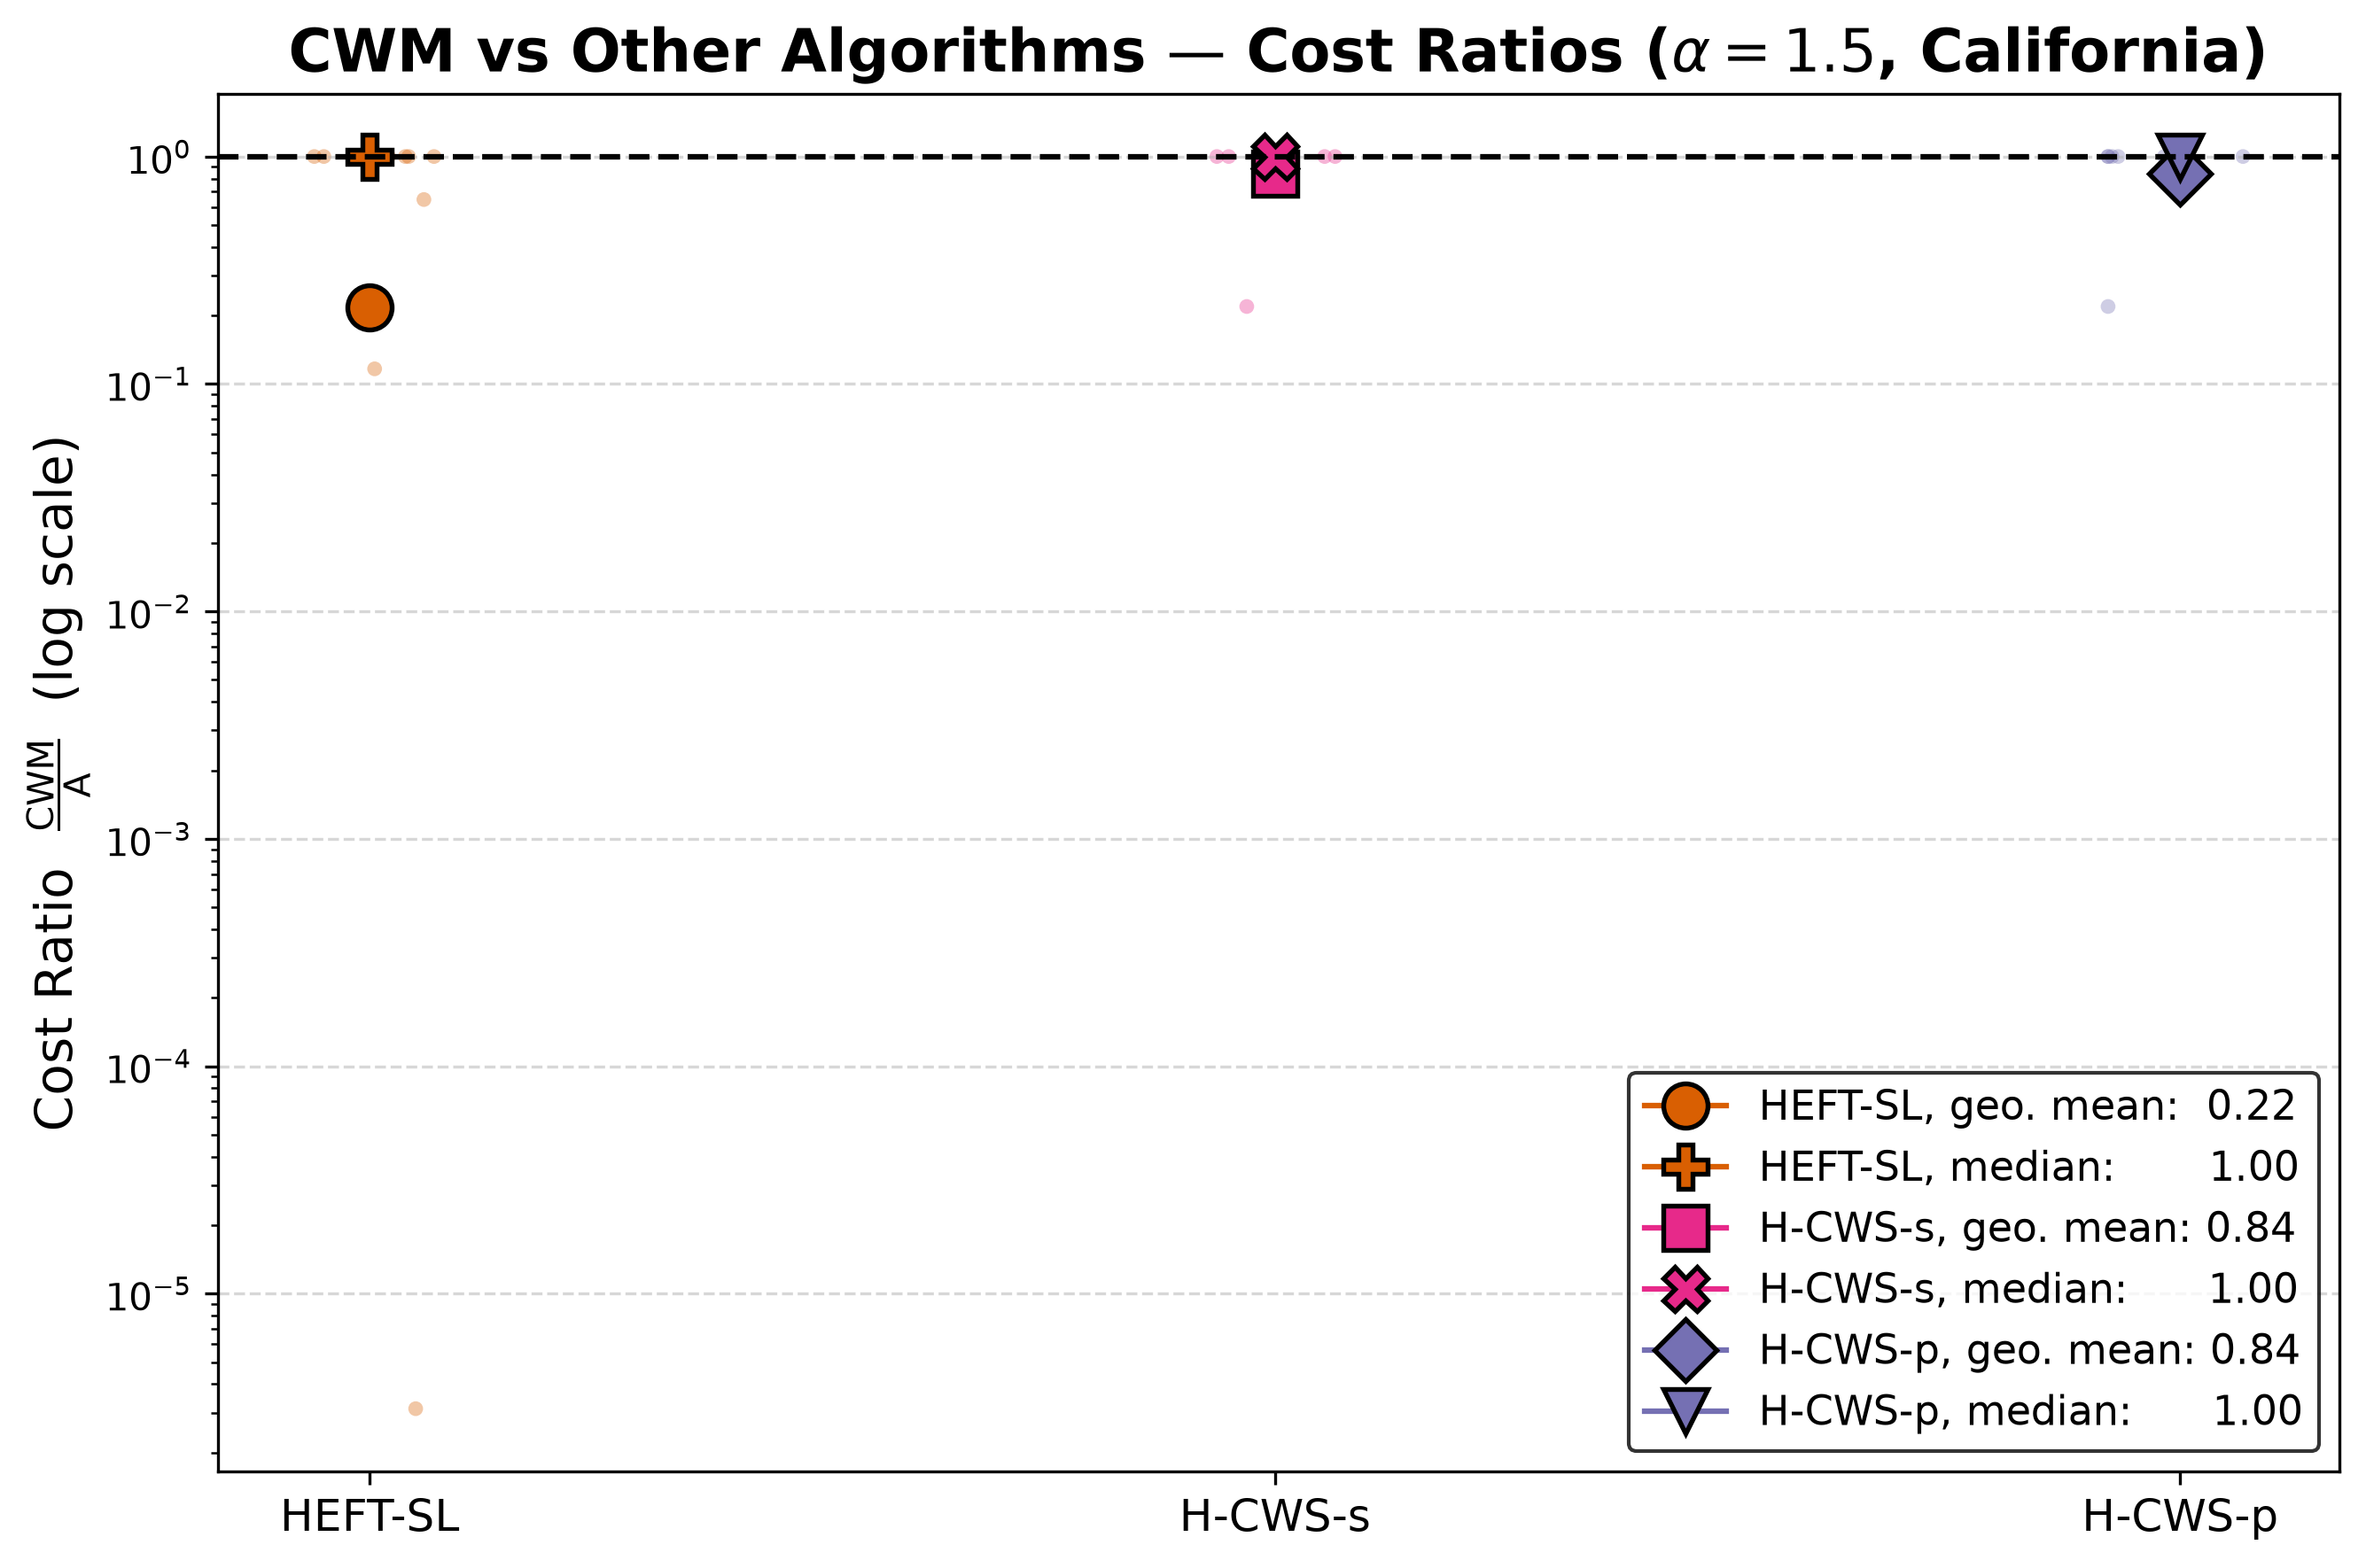

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

combined_df_15_LA = combined_df_15[combined_df_15["experiment_norm"].str.contains("LA", case=True)].copy()
print(len(combined_df_15_LA))
# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_15_LA["cost_cwm"] / combined_df_15_LA["cost_heft"],
    "H-CWS-s":    combined_df_15_LA["cost_cwm"] / combined_df_15_LA["cost_slack"],
    "H-CWS-p": combined_df_15_LA["cost_cwm"] / combined_df_15_LA["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )



ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.5$, California)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")


plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_15_california.png", bbox_inches='tight')
plt.show()

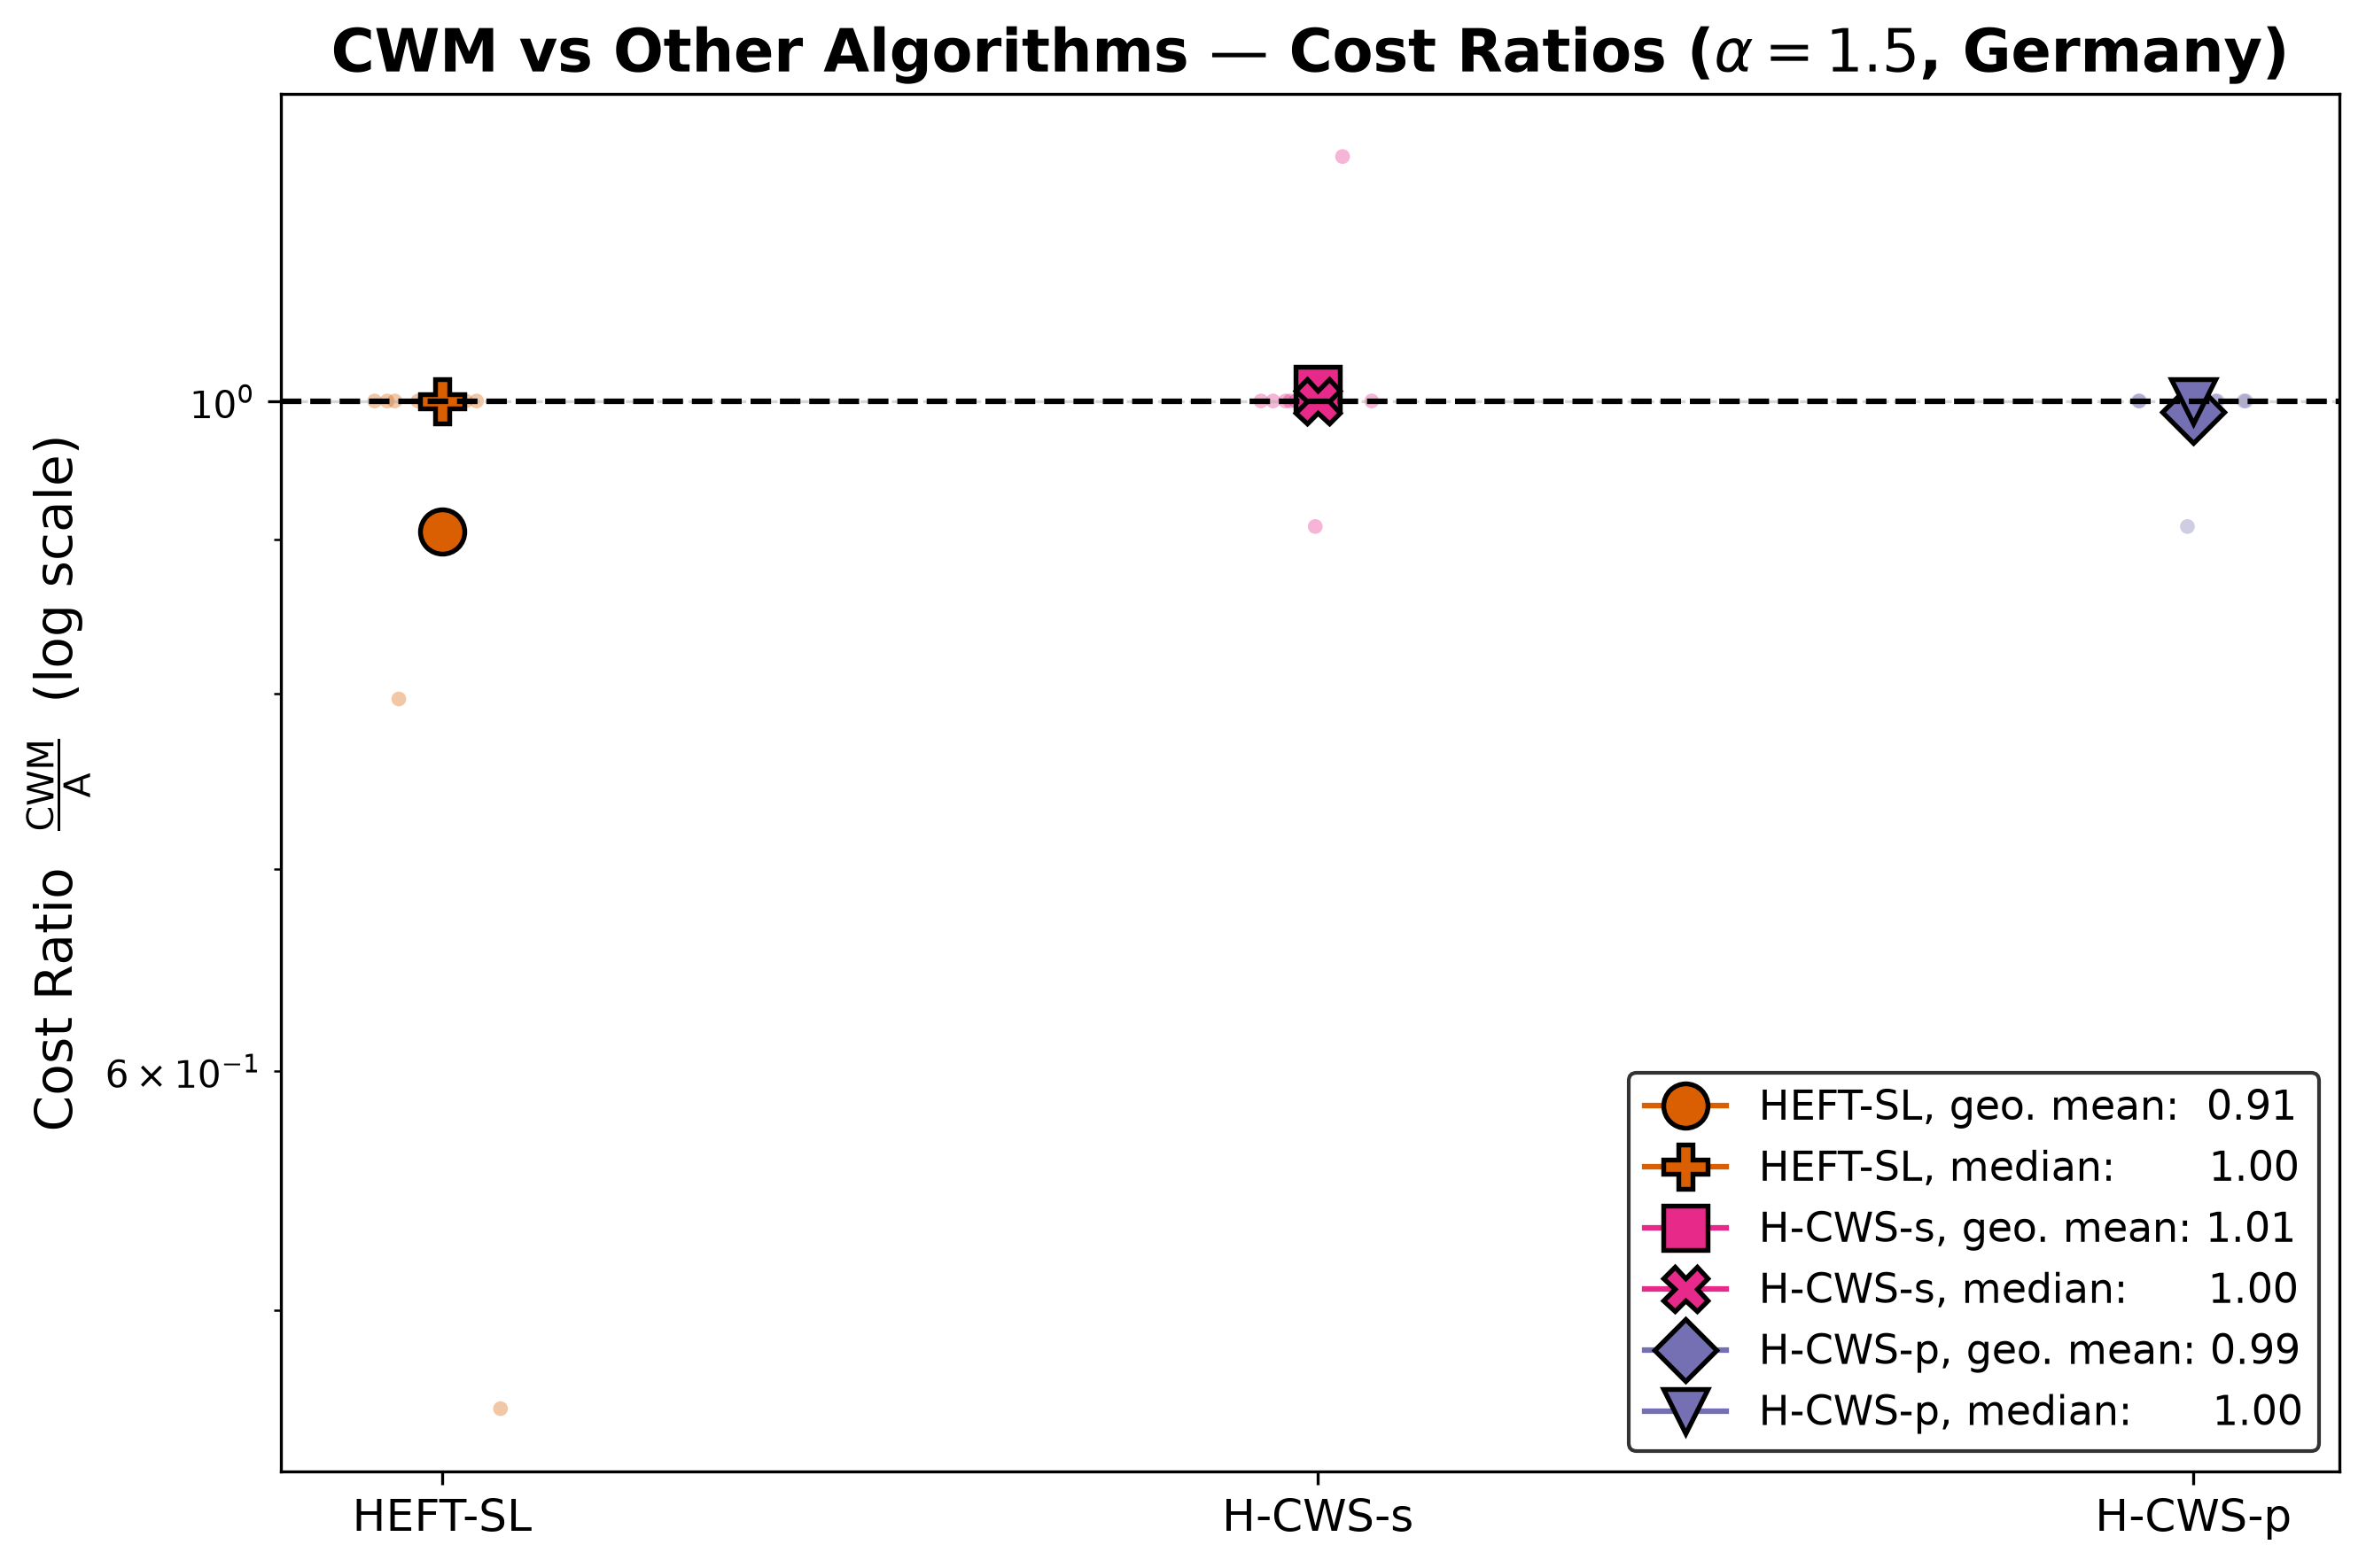

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

combined_df_15_DE = combined_df_15[combined_df_15["experiment_norm"].str.contains("DE", case=True)].copy()

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_15_DE["cost_cwm"] / combined_df_15_DE["cost_heft"],
    "H-CWS-s":    combined_df_15_DE["cost_cwm"] / combined_df_15_DE["cost_slack"],
    "H-CWS-p": combined_df_15_DE["cost_cwm"] / combined_df_15_DE["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )



ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.5$, Germany)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")


plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_15_germany.png", bbox_inches='tight')
plt.show()

12


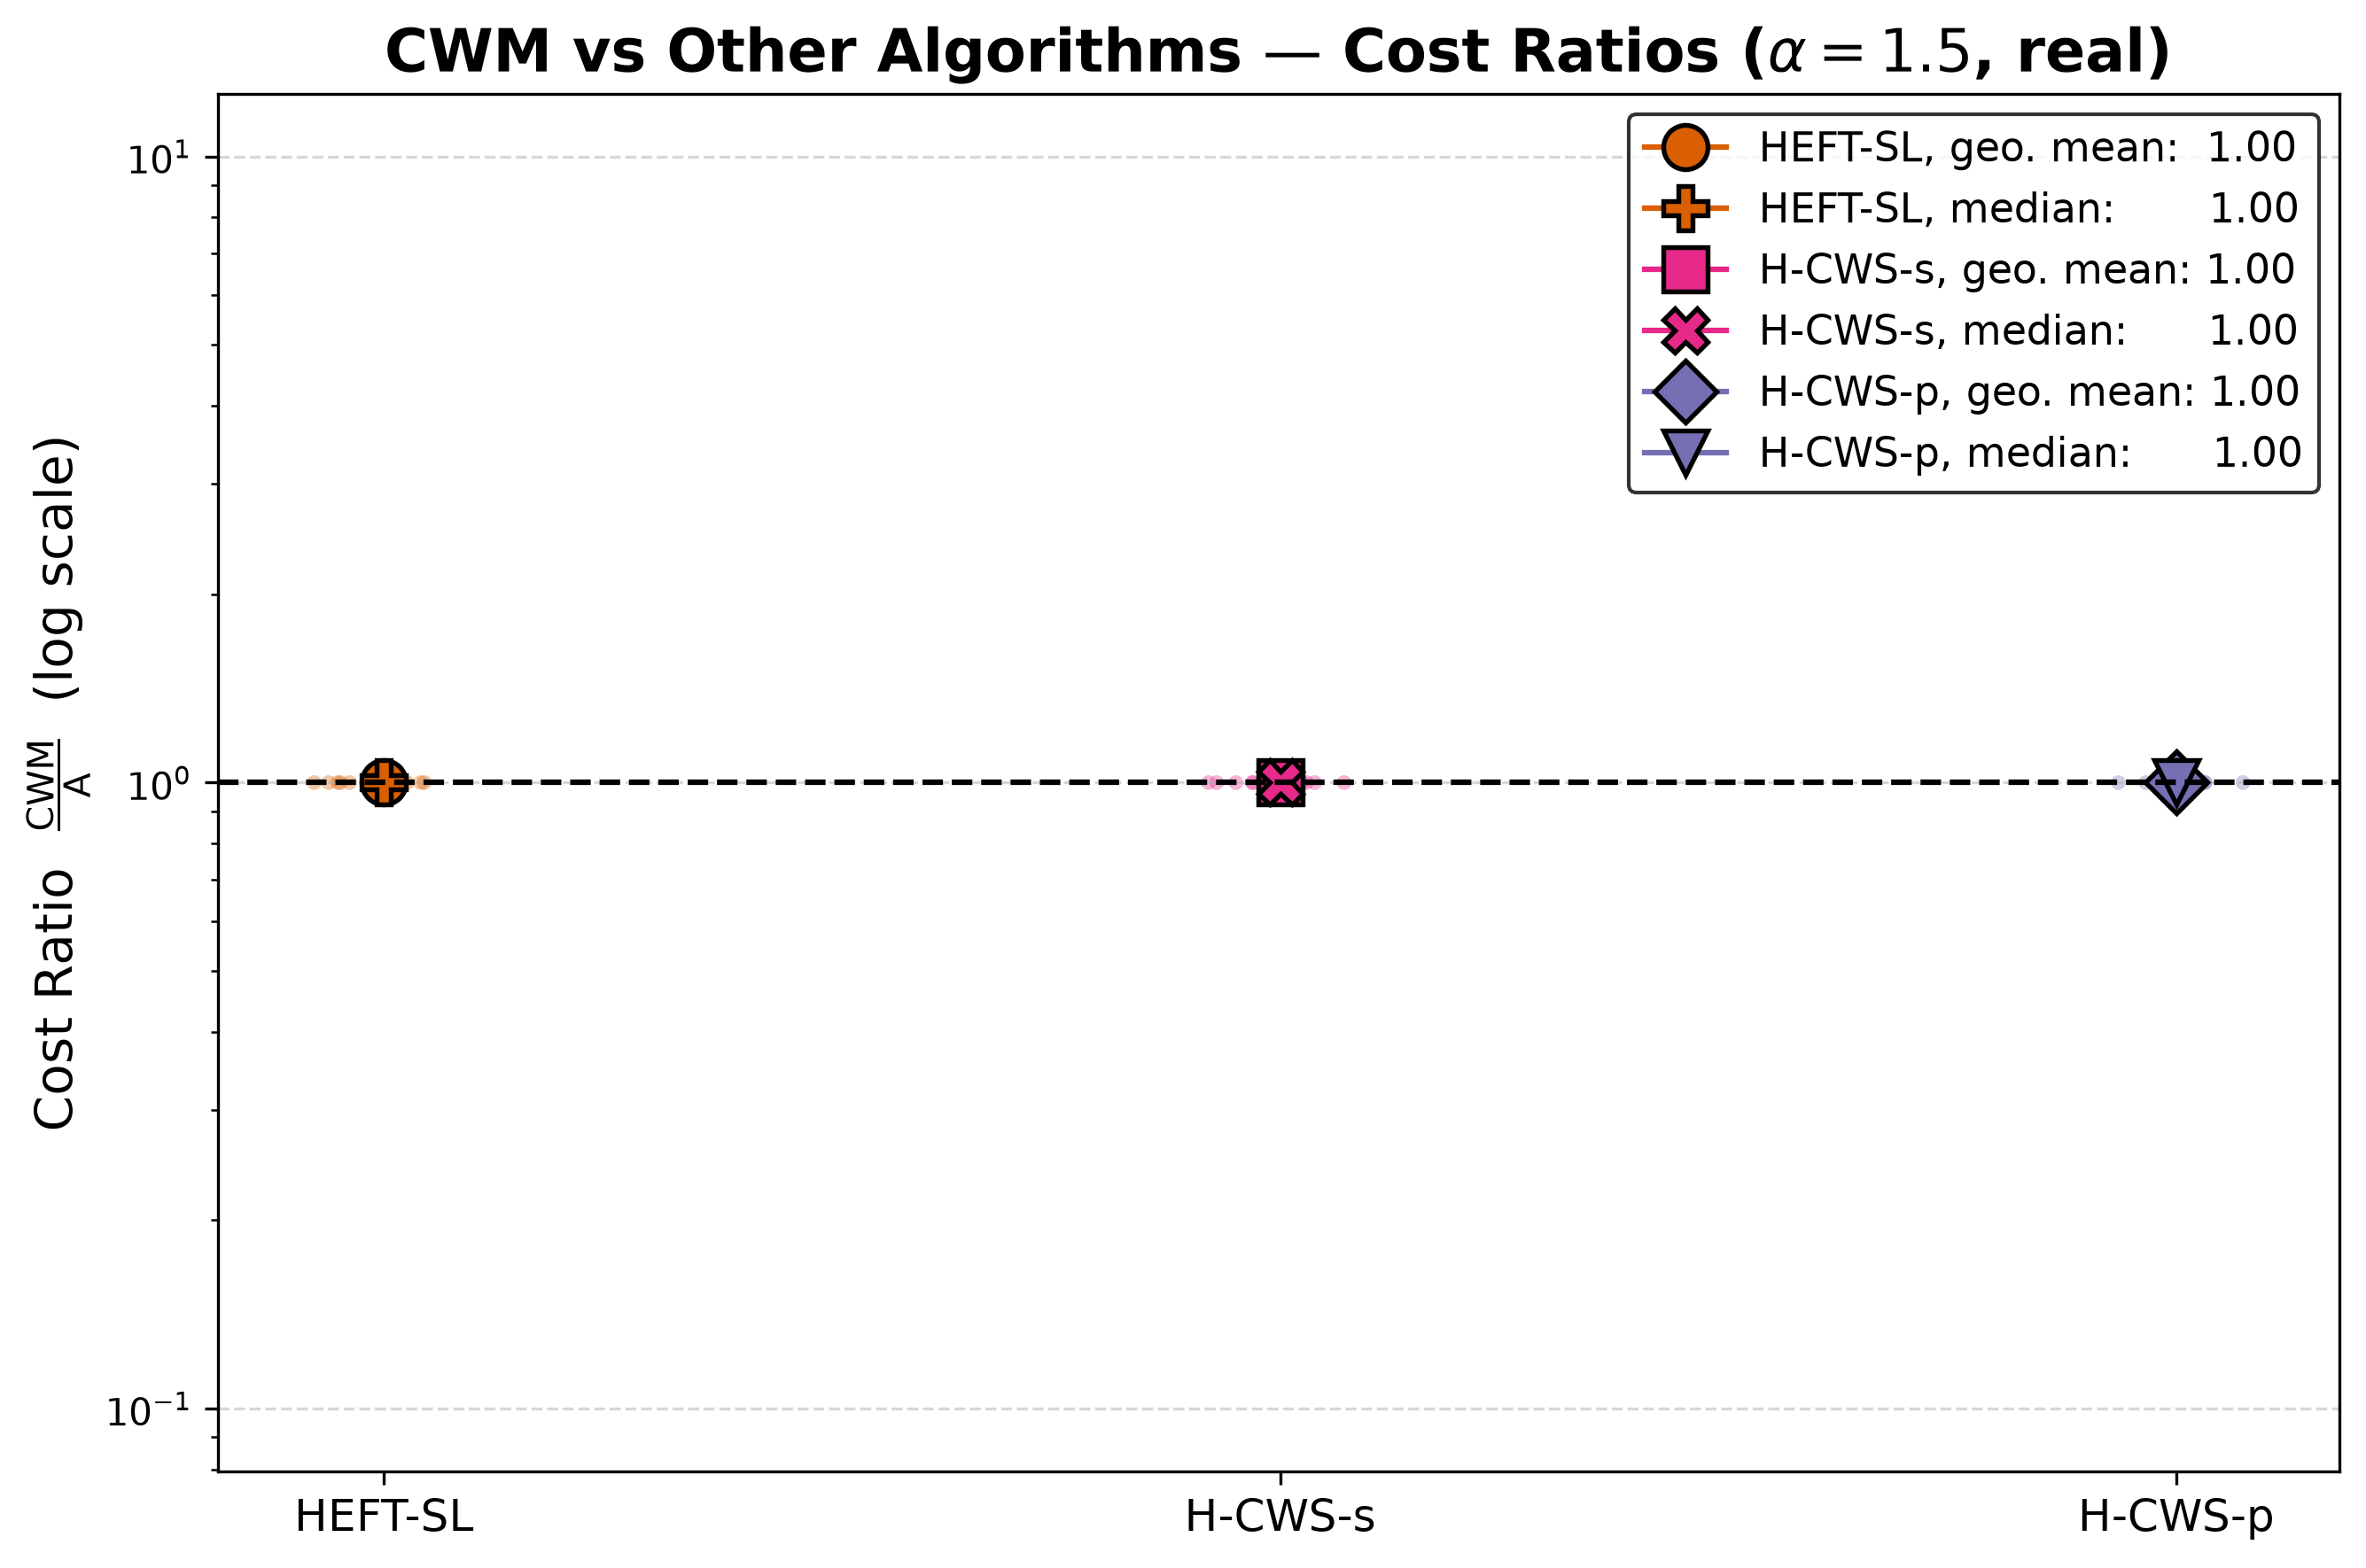

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# these graphs should be shown
sizes_to_consider = ["atacseq", "chipseq", "eager", "bacass"]

combined_df_15_realWorld = combined_df_15[combined_df_15["instance"].isin(sizes_to_consider)].copy()
print(len(combined_df_15_realWorld))
# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_15_realWorld["cost_cwm"] / combined_df_15_realWorld["cost_heft"],
    "H-CWS-s":    combined_df_15_realWorld["cost_cwm"] / combined_df_15_realWorld["cost_slack"],
    "H-CWS-p": combined_df_15_realWorld["cost_cwm"] / combined_df_15_realWorld["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )



ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.5$, real)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")


plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_15_realWorld.png", bbox_inches='tight')
plt.show()

8


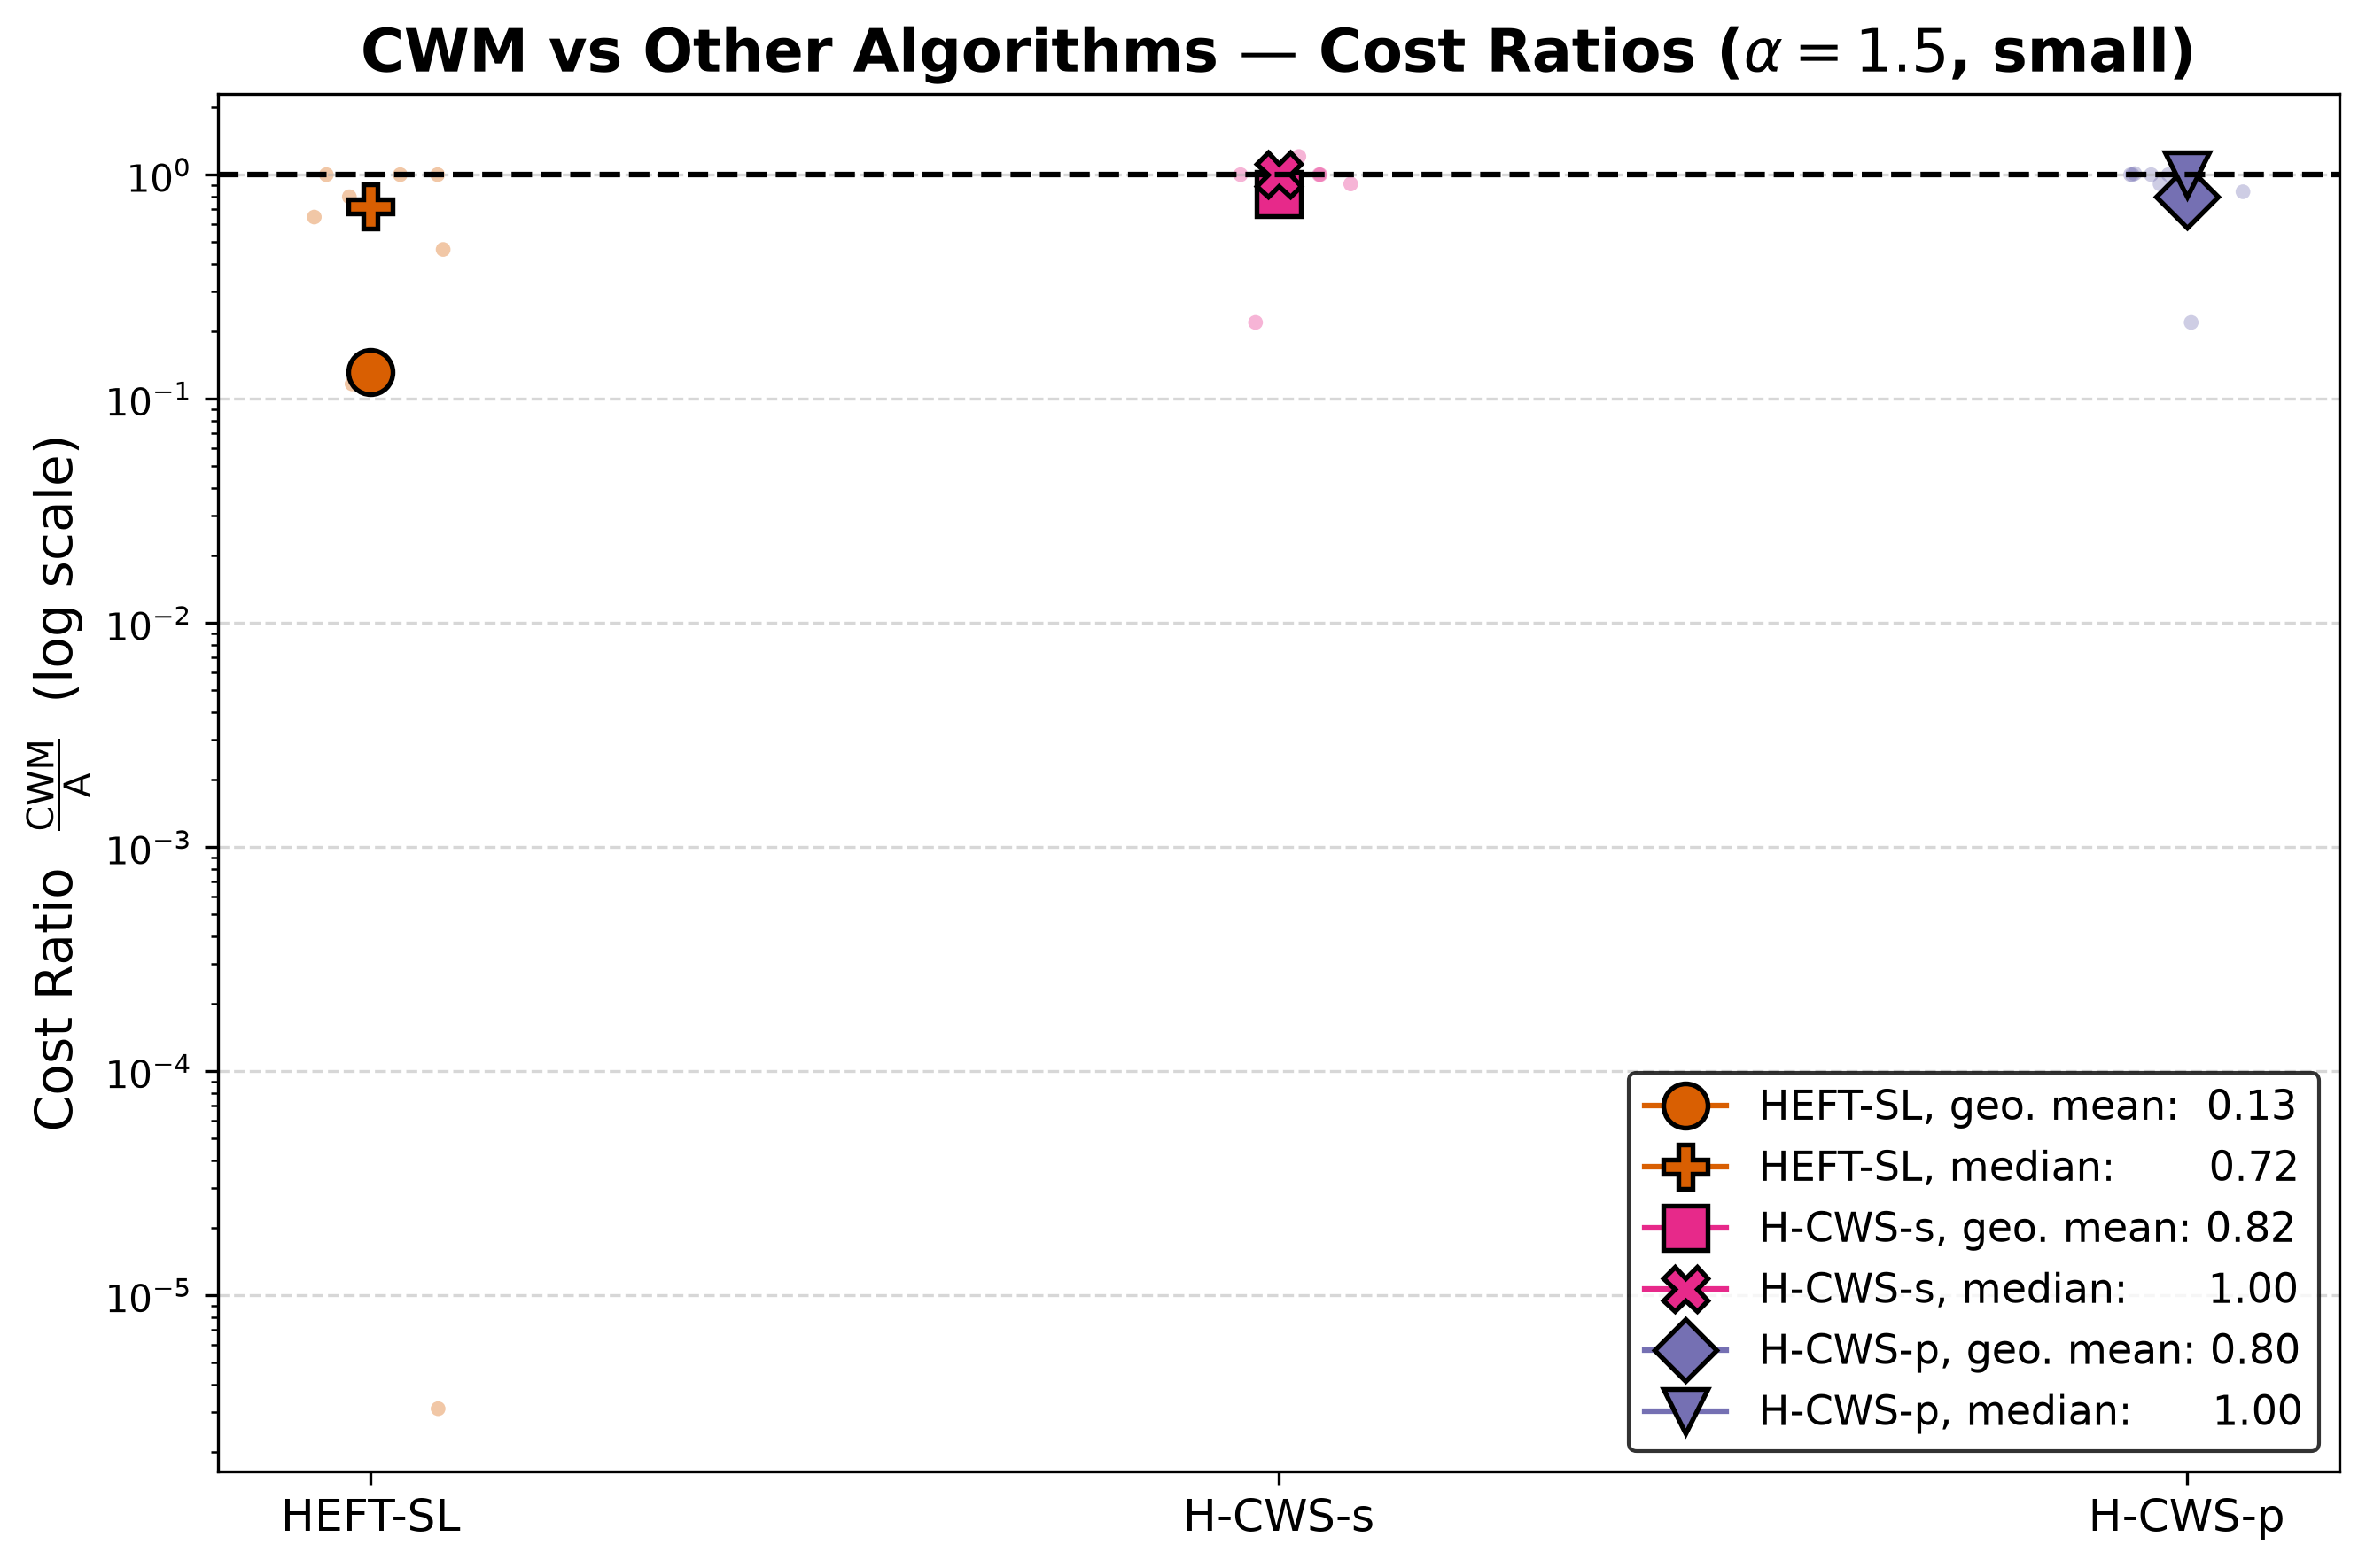

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# these graphs should be shown
sizes_to_consider = ["atacseq200", "atacseq1000", "atacseq2000", "atacseq4000", "chipseq200", "chipseq1000", "chipseq2000", "chipseq4000", "eager200", "eager1000", "eager2000", "eager4000", "methylseq200", "methylseq1000", "methylseq2000", "methylseq4000"]

combined_df_15_small = combined_df_15[combined_df_15["instance"].isin(sizes_to_consider)].copy()
print(len(combined_df_15_small))
# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_15_small["cost_cwm"] / combined_df_15_small["cost_heft"],
    "H-CWS-s":    combined_df_15_small["cost_cwm"] / combined_df_15_small["cost_slack"],
    "H-CWS-p": combined_df_15_small["cost_cwm"] / combined_df_15_small["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )



ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.5$, small)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")


plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_15_small.png", bbox_inches='tight')
plt.show()

/Users/tuhinaagarwal/Downloads/submission/.venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/tuhinaagarwal/Downloads/submission/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


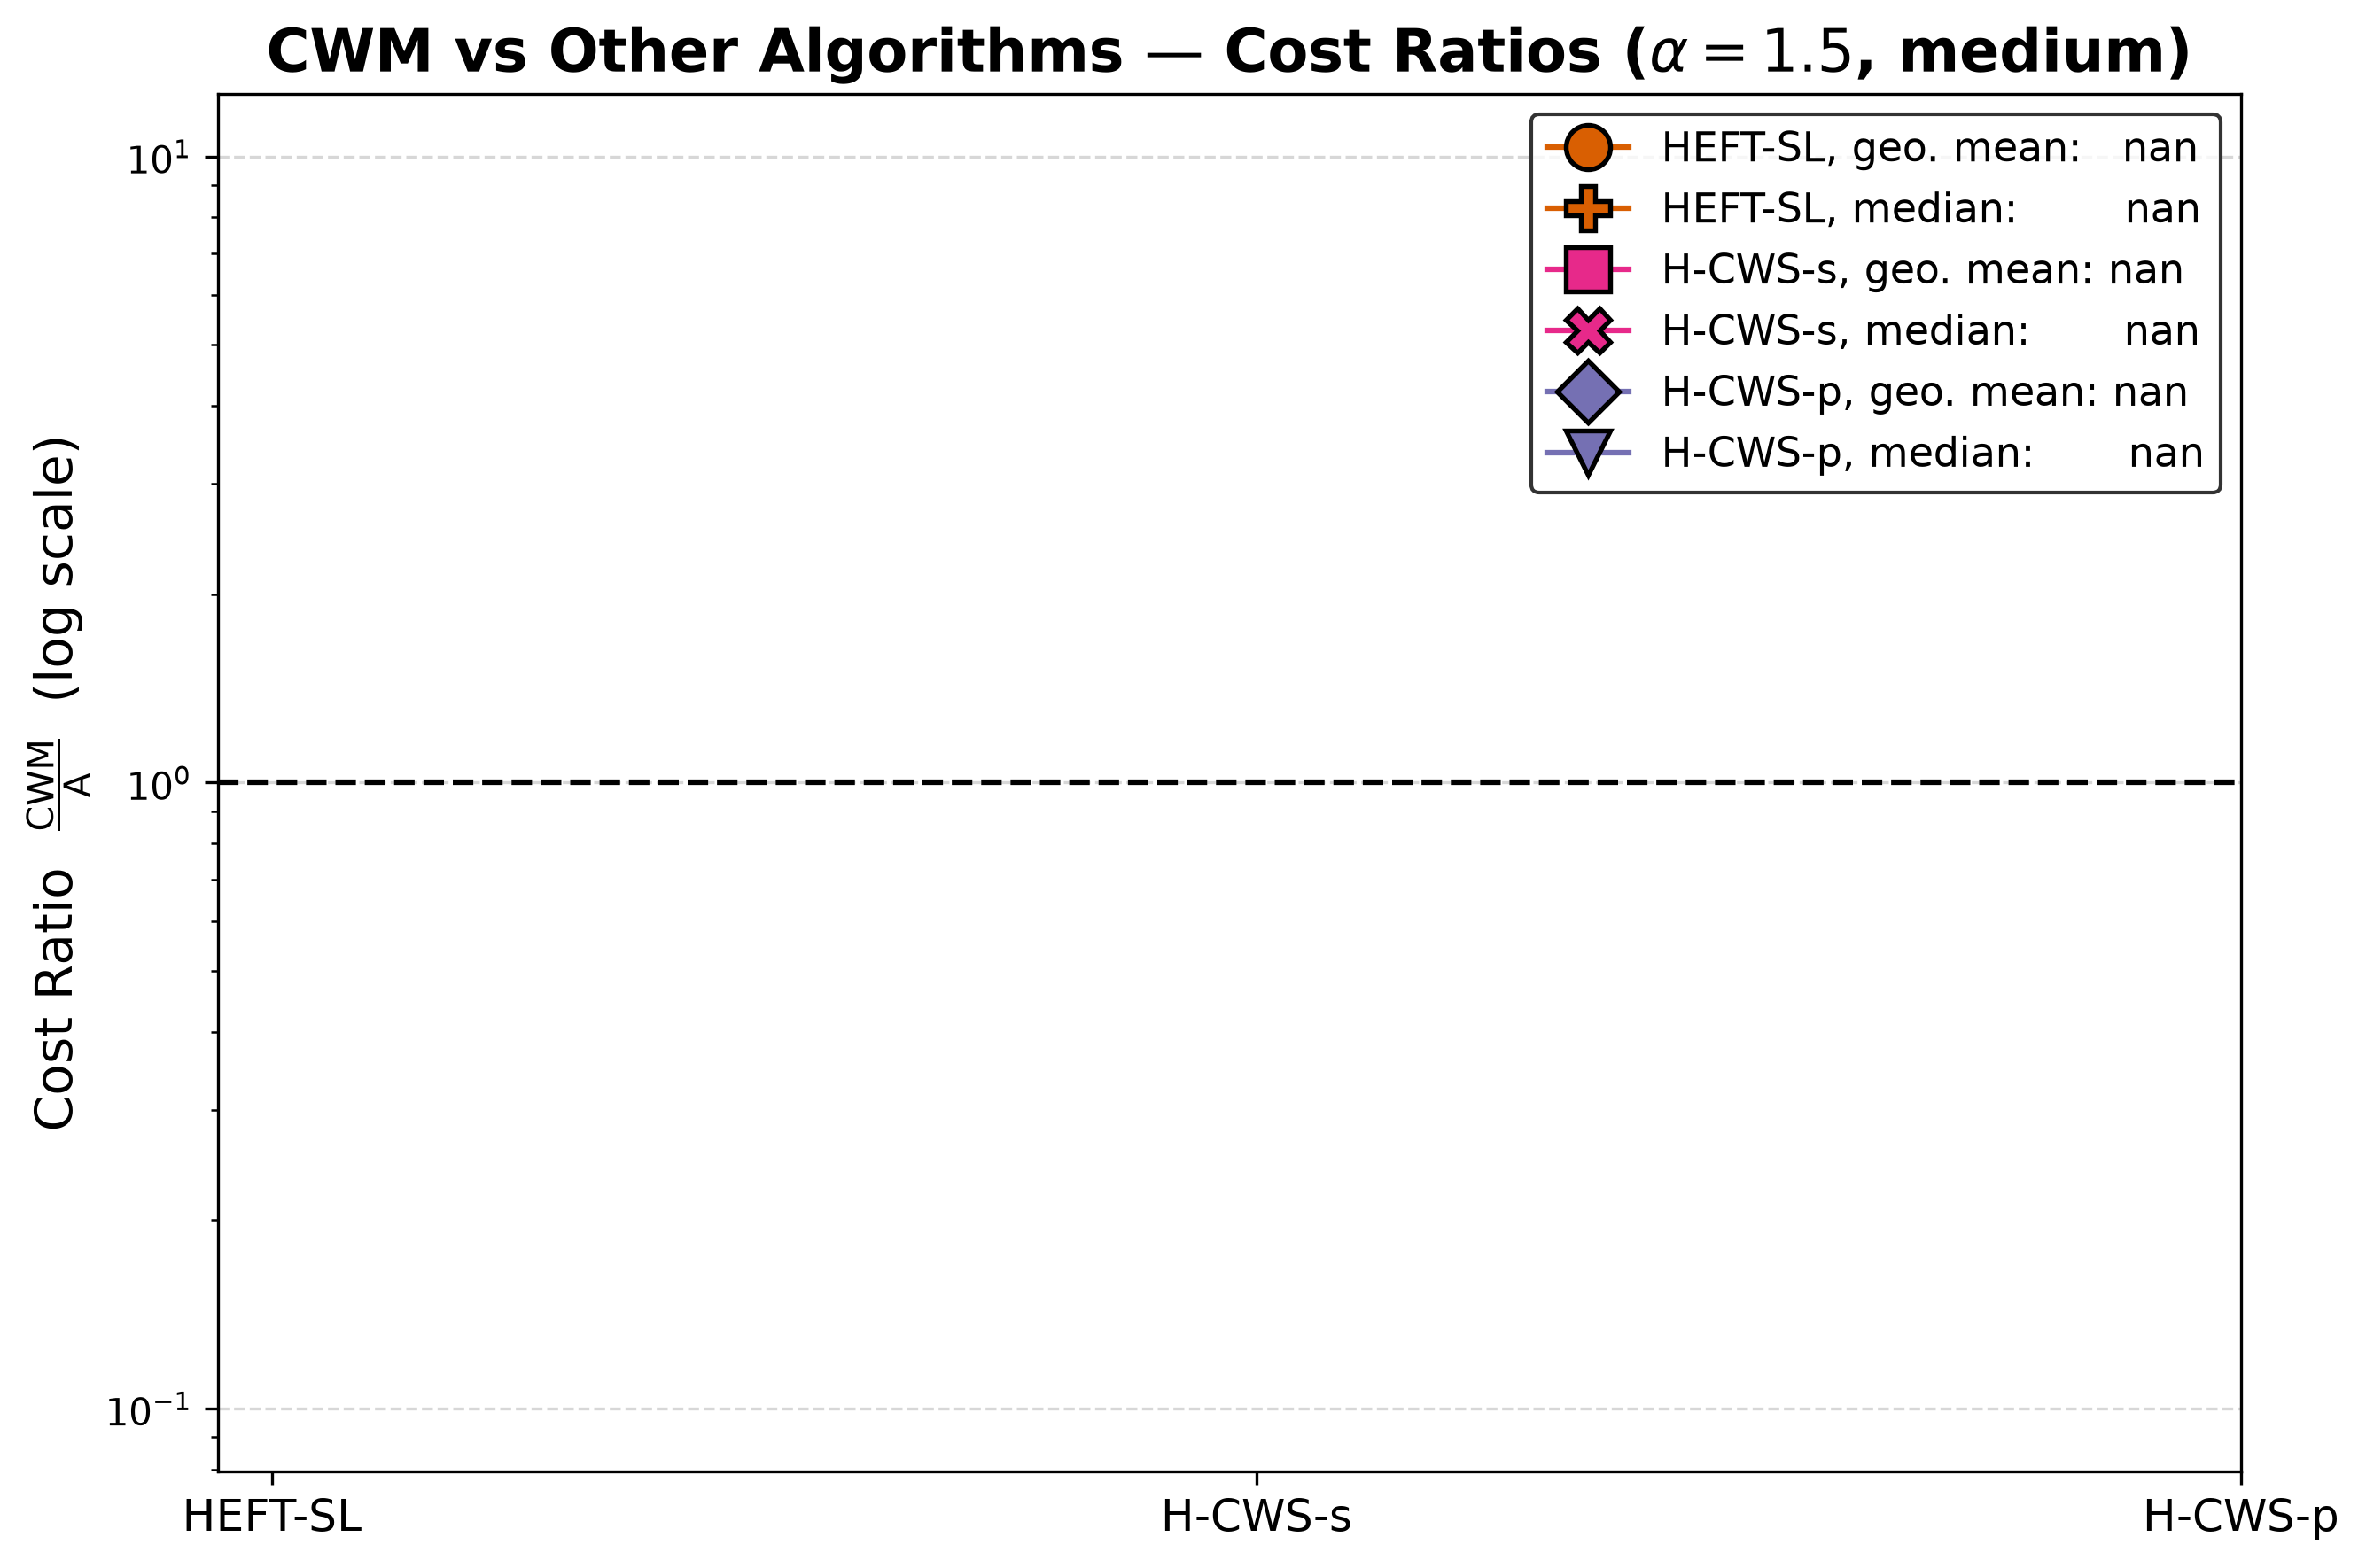

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# these graphs should be shown
sizes_to_consider = ["atacseq8000", "atacseq10000", "atacseq15000", "chipseq8000", "chipseq10000", "chipseq15000", "eager8000", "eager10000", "eager15000", "methylseq8000", "methylseq10000", "methylseq15000"]

combined_df_15_medium = combined_df_15[combined_df_15["instance"].isin(sizes_to_consider)].copy()

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_15_medium["cost_cwm"] / combined_df_15_medium["cost_heft"],
    "H-CWS-s":    combined_df_15_medium["cost_cwm"] / combined_df_15_medium["cost_slack"],
    "H-CWS-p": combined_df_15_medium["cost_cwm"] / combined_df_15_medium["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )



ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.5$, medium)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")


plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_15_medium.png", bbox_inches='tight')
plt.show()

/Users/tuhinaagarwal/Downloads/submission/.venv/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/tuhinaagarwal/Downloads/submission/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


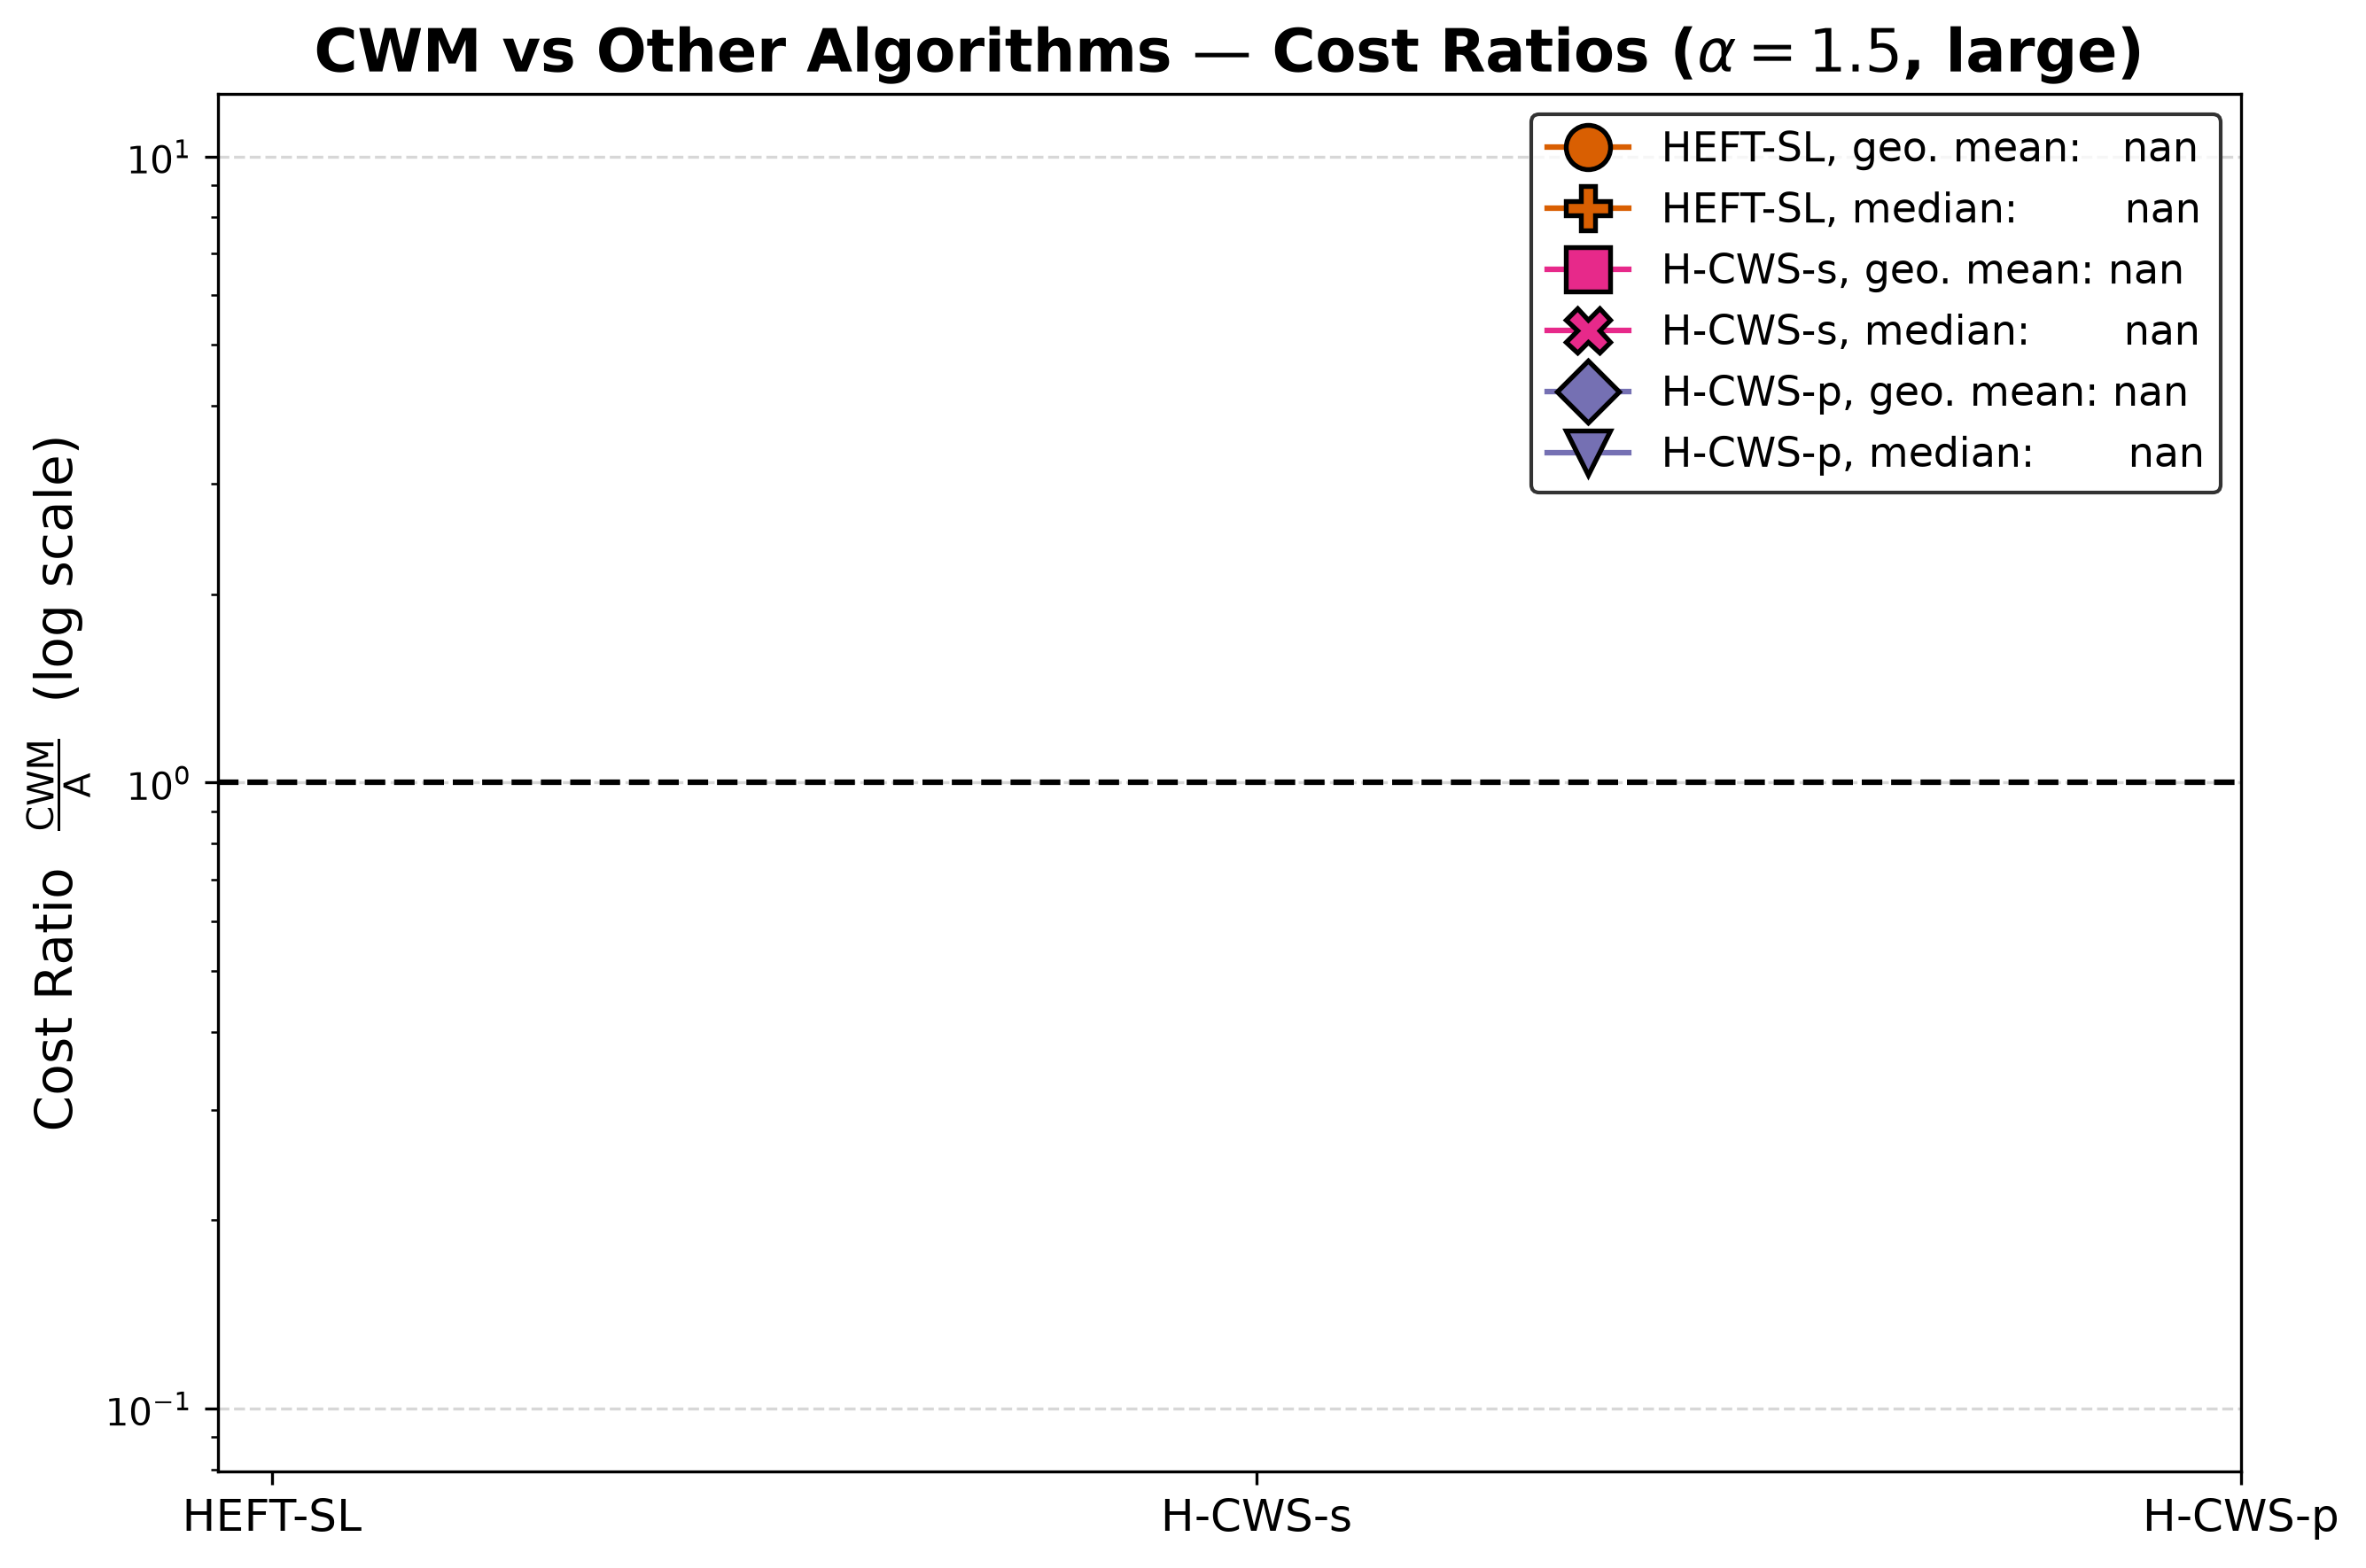

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# these graphs should be shown
sizes_to_consider = ["atacseq20000", "atacseq25000", "atacseq30000", "chipseq20000", "chipseq25000", "chipseq30000", "eager20000", "eager25000", "eager30000", "methylseq20000", "methylseq25000", "methylseq30000"]

combined_df_15_large = combined_df_15[combined_df_15["instance"].isin(sizes_to_consider)].copy()

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_15_large["cost_cwm"] / combined_df_15_large["cost_heft"],
    "H-CWS-s":    combined_df_15_large["cost_cwm"] / combined_df_15_large["cost_slack"],
    "H-CWS-p": combined_df_15_large["cost_cwm"] / combined_df_15_large["cost_pressure"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}

# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}

algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )



ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=1.5$, large)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")


plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_15_large.png", bbox_inches='tight')
plt.show()

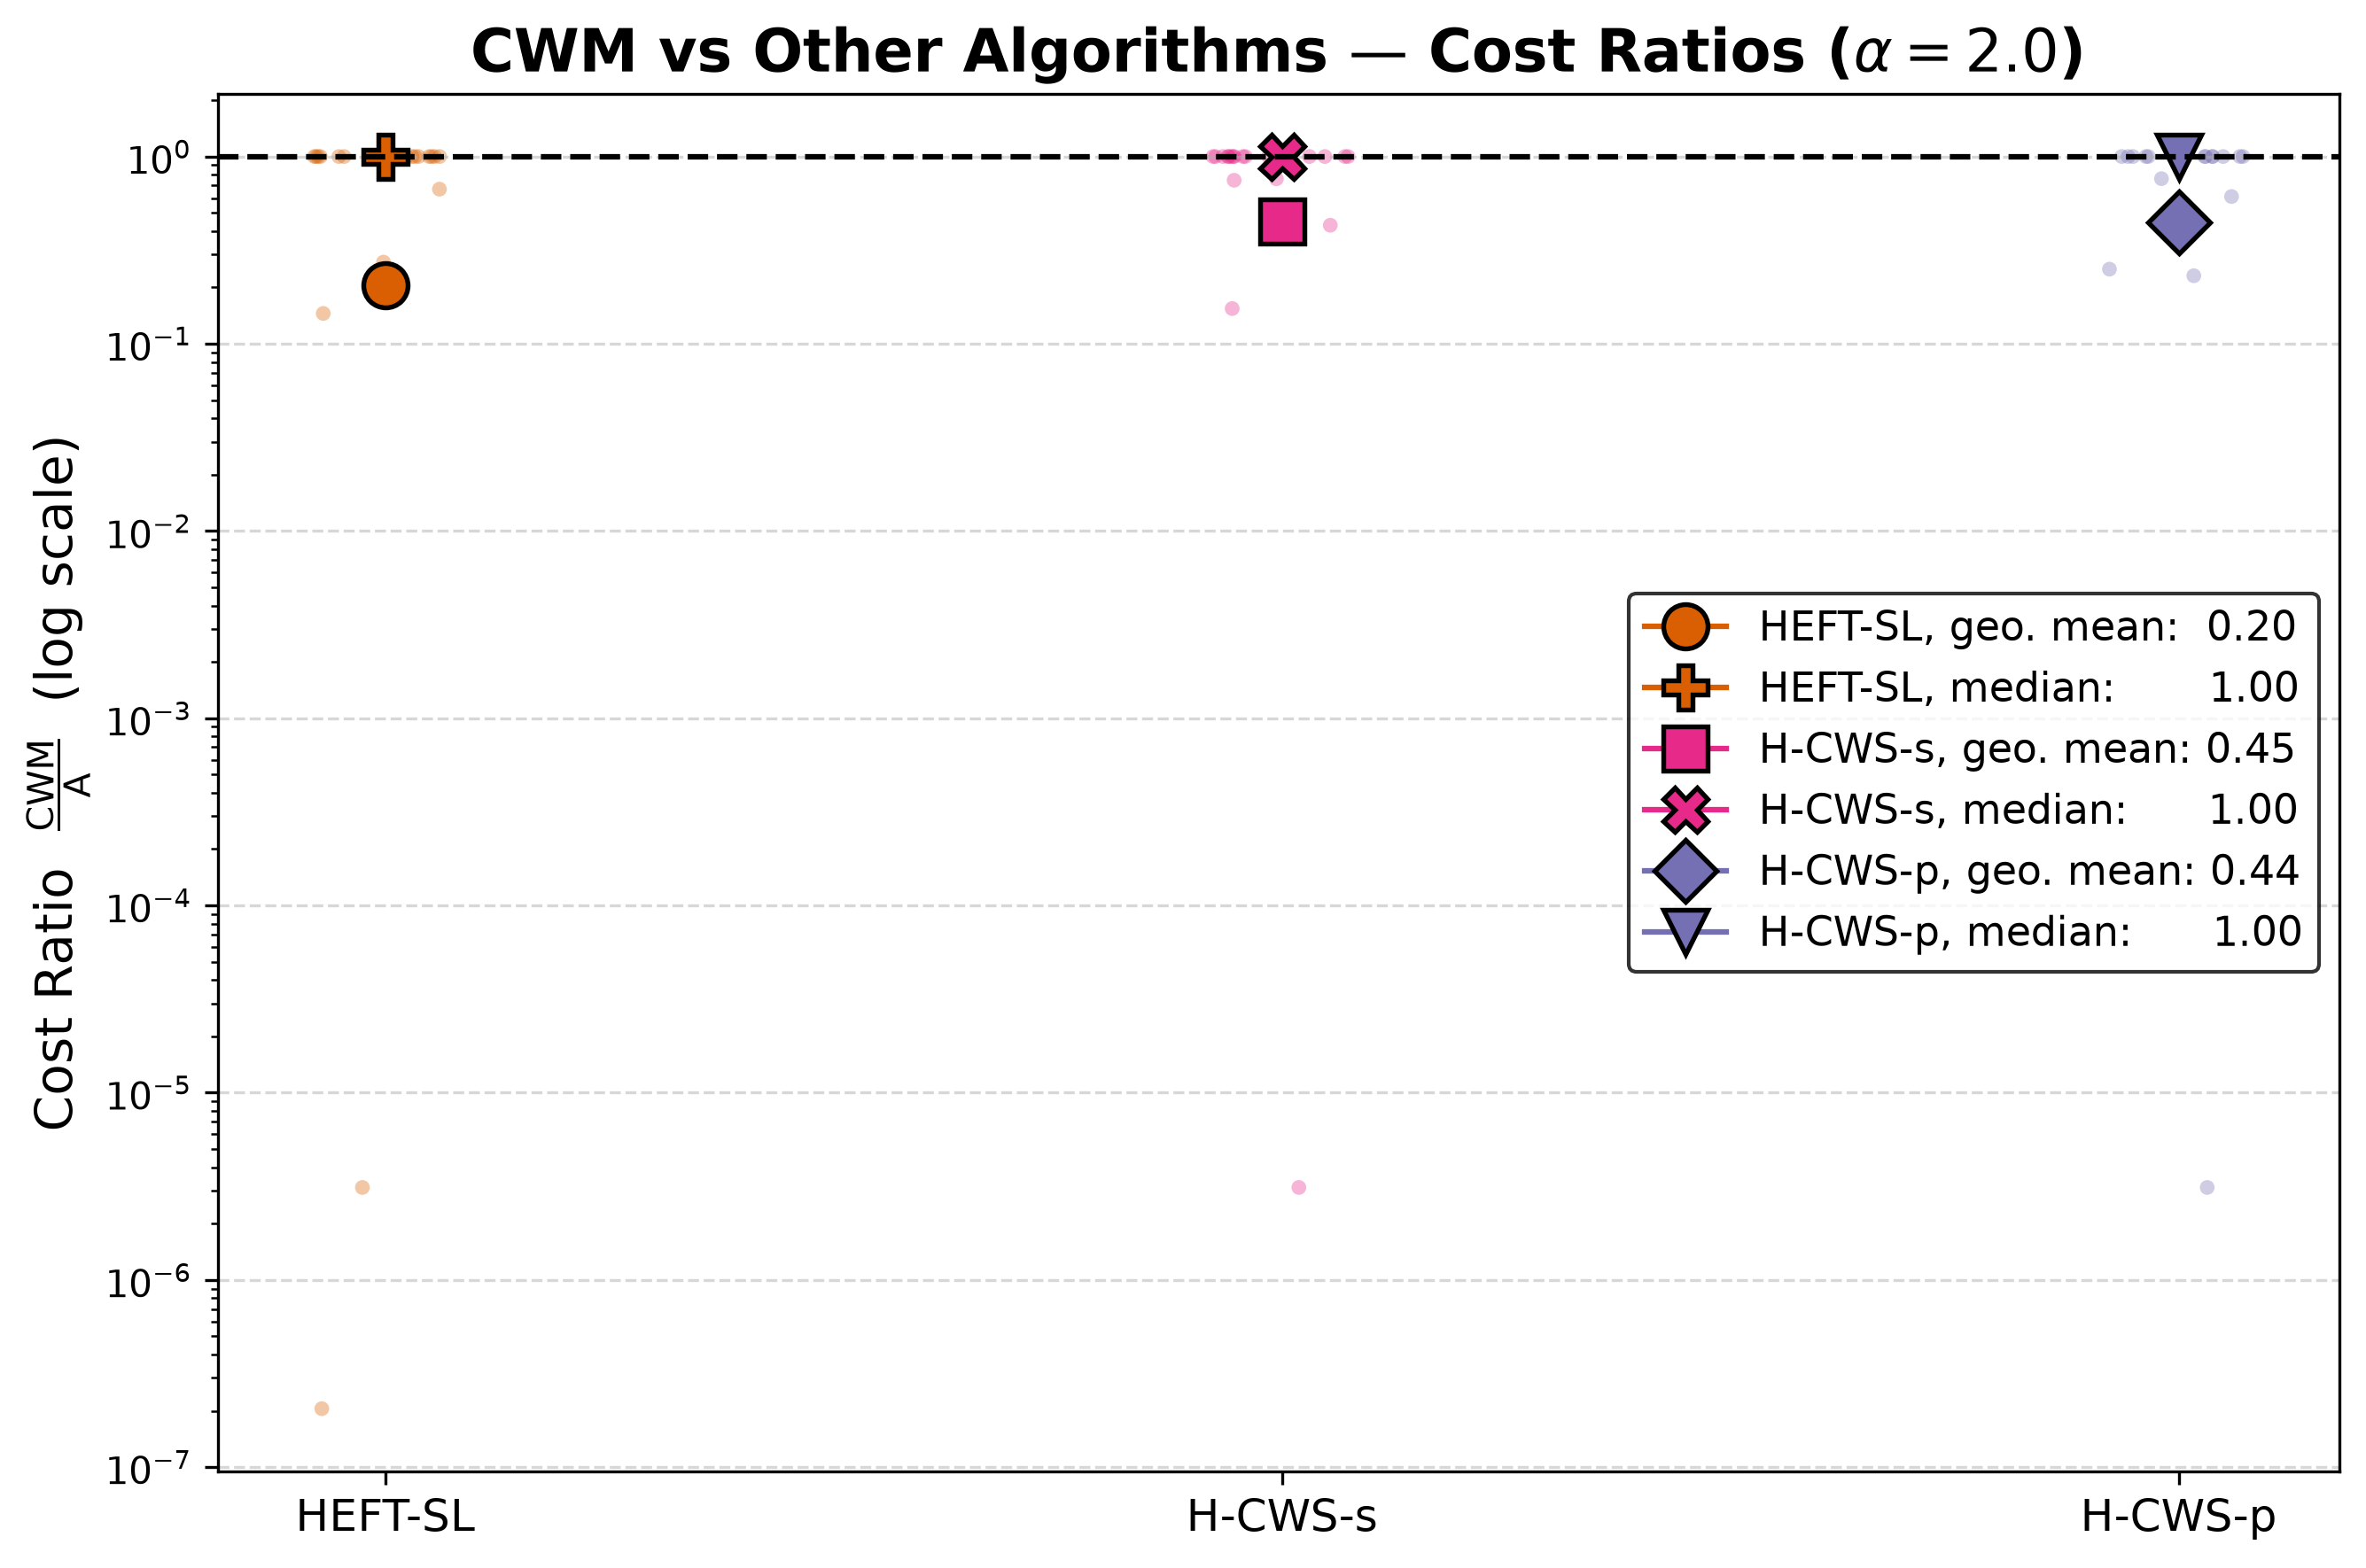

In [40]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ----------------------------------------------------
# 1. Compute ratios (CWM / X)
# ----------------------------------------------------
ratio_dict = {
    "HEFT-SL":     combined_df_20["cost_cwm"] / combined_df_20["cost_heft"],
    "H-CWS-s":    combined_df_20["cost_slack"] / combined_df_20["cost_heft"],
    "H-CWS-p": combined_df_20["cost_pressure"] / combined_df_20["cost_heft"],
}

# Clean invalid values
for k in ratio_dict:
    ratio_dict[k] = pd.to_numeric(ratio_dict[k], errors="coerce")
    ratio_dict[k] = ratio_dict[k].replace([np.inf, -np.inf], np.nan).dropna()

# Geometric means
geo_means = {k: np.exp(np.mean(np.log(v))) for k, v in ratio_dict.items()}
# also have the medians
median_ratios = {k: np.median(v) for k, v in ratio_dict.items()}


algos = list(ratio_dict.keys())
colors = ["#d95f02", "#e7298a", "#7570b3"]
markers = ["o", "s", "D"]
x_positions = np.arange(len(algos))

ZOOM_LOWER = 0.1
ZOOM_UPPER = 2.0

# ----------------------------------------------------
# 2. Main figure
# ----------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# -------- MAIN PLOT --------
for i, alg in enumerate(algos):
    r = ratio_dict[alg].values
    jitter = np.random.uniform(-0.08, 0.08, size=len(r))

    ax.scatter(
        np.full_like(r, x_positions[i]) + jitter,
        r,
        s=16,
        alpha=0.35,
        color=colors[i],
        edgecolors="none"
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, geo. mean: {geo_means[alg]:5.2f}"
    else:
      label_text = f"{alg}, geo. mean: {geo_means[alg]:.2f}"
    ax.plot(
        x_positions[i],
        geo_means[alg],
        marker=markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )
    if alg == "HEFT-SL":
      label_text = f"{alg}, median: {median_ratios[alg]:10.2f}"
    else:
      label_text = f"{alg}, median: {median_ratios[alg]:9.2f}"
    ax.plot(
        x_positions[i],
        median_ratios[alg],
        marker=median_markers[i],
        markersize=12,
        markeredgewidth=1.3,
        markeredgecolor="black",
        color=colors[i],
        label=label_text
    )

ax.set_yscale("log")
ax.axhline(1.0, color="black", linestyle="--")
ax.grid(axis="y", linestyle="--", alpha=0.5)

ax.set_xticks(x_positions)
ax.set_xticklabels(algos, fontsize=12)
ax.set_ylabel(r"Cost Ratio  $\frac{\mathrm{CWM}}{\mathrm{A}}$  (log scale)", fontsize=14)
ax.set_title(r"CWM vs Other Algorithms — Cost Ratios ($\alpha=2.0$)", fontsize=16, weight="bold")
ax.legend(fontsize=11, frameon=True, edgecolor="black")






plt.tight_layout()
plt.savefig("plots/shifted/cost_ratios_20_cws_heft.png", bbox_inches='tight')
plt.show()